# Dataset analysis

The goal of this notebook is to understand the Taho100M data more deeply. In particular, the relationship between unperturbed and perturbed cells is being investigated. The aim is to determine whether there is a discernible difference between the unperturbed and perturbed cells that allows for a deep learning model to be trained. 

The goal is to find perturbations, that show significant structured distributional difference, meaning the perturbed cell distribution should be significantly different from the unperturbed cell distribution, but not too much, as this might correspond with a cells stress response, potentially leading to highly fluctuating cell states. 

In order to determine the magnitude of the perturbation, the perturbation effect is evaluated across all available perturbations. We aim for an overall perturbation strength in the 60th to 85th quantile. 

# Pre-Analysis processing steps
*Preprocessing and quality control steps followed the general procedures outlined in Heumos et al. [1]. These steps are already performed inside the "create_dataset.py" file.*

1. Filter for one perturbation and one cell line (also same cell line for unperturbed cells)
    - Ideally 10k perturbed cells
    - This ensures sufficient count depth, enabeling models to learn and train the distribution pattern and ensure high dataset quality.

2. Quality Control
    - A low number of detected genes, a low count depth and a high fraction of mitochondrial counts might indicate a broken cell membrane, suggesting that the cell might be dead. Fortunately, several quality control steps were already carried out during the creation of the Tahoe-100M dataset. This includes requiring cells to have at least 700 unique molecular identifiers (UMIs), less than 20% mitochondrial reads, a UMI z-score within +-3 to remove outliers in total counts, a mitochondrial percentage z-score within ±3 to remove outliers in mitochondrial content, and at least 250 genes detected (Zhang et al. [2]).
    - Additionally, cells identified as doublets or ambigous were also excluded from the Tahoe-100M dataset, ensuring only singlets were retained (Zhang et al. [2]).
3. Normalize the total gene count
    - This ensures comparability between cells, that have been sequenced with differing frequency. 

## Steps

1. Global Effect Size - E-Distance 
    - $D^2(F, G) = 2 \cdot E|| X-Y || - E||X - X'|| - E||Y - Y'||$
    - E-Distance accounts for within-group variance, allowing us to capture more information about the distributional shape
2. Distributional Divergence - Maximum Mean Discrepancy & Wasserstein-Distance
    - Measure whether two sets of samples come from same distributions
    - Captures difference w.r.t. mean, variance, skweness, multimodality
3. Subpopulation Structure -> Modality test through UMAP
    - UMAP to visualize difference in distribution and potentially identify subpopulations within each distribution -> Too many subpopulations might complicate evaluation
4. Gene Level Analysis - What is driving the difference?
    - Differential Expression (DES) to identify which genes are significantly changed and how many
    - Check if enriched genes are known to be responsible for stress responses or apoptosis
    - Pathway enrichment analysis -> Cell might activate subtle pathways, instead of markers + Ensure perturbation is acting through expected biological mechanism
5. Overview
    - Additional visualizations

- MSE
- Pearson Correlation Coefficient Delta
- E-Distance
- Wasserstein Distance
- DEGs

# Imports

In [ ]:
import os
os.environ["CUDA_VISIBLE_DEVICES"]= '1'

import torch
import decoupler as dc
import numpy as np
import scanpy as sc
import pertpy as pt
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns
from seaborn import clustermap, heatmap

# Math
from scperturb import edist, etest
import scipy
from scipy.stats import wasserstein_distance, pearsonr, energy_distance
from scipy.spatial.distance import cdist

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# device = torch.device("cpu")
print(f"Using device: {device}")

In [ ]:
import pandas as pd
pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 500)
pd.set_option('display.width', 1000)

# Load data

In [ ]:
adata = sc.read_h5ad("../../data/tahoe100M_SW480_filtered_1024.h5ad", backed="r")

In [ ]:
adata = adata.to_memory()
# sc.pp.highly_variable_genes(adata, n_top_genes=10_000)
# adata = adata[:, adata.var.highly_variable].copy()

In [ ]:
len(adata.var)

1024

In [ ]:
len(adata)

504767

In [ ]:
adata.obs[adata.obs['drug'] == "BI-3406"] 

,sample,gene_count,tscp_count,mread_count,drugname_drugconc,drug,cell_line,sublibrary,BARCODE,pcnt_mito,S_score,G2M_score,phase,pass_filter,cell_name,plate
BARCODE_SUB_LIB_ID,,,,,,,,,,,,,,,,
22_005_184-lib_1000,smp_1612,726,946,1139,"[('BI-3406', 0.5, 'uM')]",BI-3406,CVCL_0546,lib_1000,22_005_184,0.040169,-0.003968,-0.023626,G1,full,SW480,plate2
22_007_115-lib_1000,smp_1612,1776,2479,3036,"[('BI-3406', 0.5, 'uM')]",BI-3406,CVCL_0546,lib_1000,22_007_115,0.044373,0.031746,0.424542,G2M,full,SW480,plate2
22_016_031-lib_1000,smp_1612,1102,1461,1761,"[('BI-3406', 0.5, 'uM')]",BI-3406,CVCL_0546,lib_1000,22_016_031,0.030116,-0.043651,-0.037546,G1,full,SW480,plate2
22_020_162-lib_1000,smp_1612,4215,7861,9490,"[('BI-3406', 0.5, 'uM')]",BI-3406,CVCL_0546,lib_1000,22_020_162,0.060298,0.916667,1.312637,G2M,full,SW480,plate2
22_022_146-lib_1000,smp_1612,996,1307,1587,"[('BI-3406', 0.5, 'uM')]",BI-3406,CVCL_0546,lib_1000,22_022_146,0.026014,-0.027778,-0.080952,G1,full,SW480,plate2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22_177_182-lib_999,smp_1612,1244,1727,2050,"[('BI-3406', 0.5, 'uM')]",BI-3406,CVCL_0546,lib_999,22_177_182,0.042270,-0.051983,-0.023077,G1,full,SW480,plate2
22_177_189-lib_999,smp_1612,1720,2730,3241,"[('BI-3406', 0.5, 'uM')]",BI-3406,CVCL_0546,lib_999,22_177_189,0.015751,-0.068109,1.044689,G2M,full,SW480,plate2
22_180_003-lib_999,smp_1612,1261,1785,2129,"[('BI-3406', 0.5, 'uM')]",BI-3406,CVCL_0546,lib_999,22_180_003,0.038095,-0.047998,-0.056777,G1,full,SW480,plate2


In [ ]:
adata.obs[adata.obs['drug'] == "Everolimus"]["phase"].value_counts()

phase
G1     4535
G2M    3642
S      1814
Name: count, dtype: int64

In [ ]:
len(adata.obs['drug'].value_counts())

93

In [ ]:
adata.obs['drug'].value_counts()[:30]

drug
DMSO_TF                 15050
Vemurafenib             11762
Anastrozole             10058
Everolimus               9991
Gemcitabine              9771
Lonafarnib               9585
Paclitaxel               9559
Minodronic acid          9532
Tubulin inhibitor 6      8968
Oxaliplatin              8950
Adagrasib                8892
RMC-6236                 8866
olaparib                 8348
4EGI-1                   8235
Regorafenib              8152
BI-3406                  7882
venetoclax               7861
DT-061                   7826
ETC-206                  7793
DTP3                     7786
Afatinib                 7762
Torkinib                 7672
Ixazomib                 7379
Capmatinib               7280
Lapatinib ditosylate     7253
AT7519                   7006
Capivasertib             6976
Oleic acid               6918
c-Kit-IN-1               6870
Infigratinib             6832
Name: count, dtype: int64

In [ ]:
pert_count = 0
for d in ["BI-3406", "Capmatinib", "Paclitaxel", "Oxaliplatin", "Gemcitabine", "Vemurafenib", "Anastrozole", "Minodronic acid", "Everolimus", "Adagrasib"]:
    pert_count += len(adata.obs[adata.obs['drug'] == d])
print(pert_count)

93677


In [ ]:
all_drugs = adata.obs['drug'].unique().tolist()
top10_drugs = adata.obs['drug'].value_counts().index[1:11].tolist()
top10_drugs

['Vemurafenib',
 'Anastrozole',
 'Everolimus',
 'Gemcitabine',
 'Lonafarnib',
 'Paclitaxel',
 'Minodronic acid',
 'Tubulin inhibitor 6',
 'Oxaliplatin',
 'Adagrasib']

In [ ]:
obs_key = "drug"
contrast = "DMSO_TF"

# Helper 

In [ ]:
def subsample(drugs, num_samples_by_drug=100):
    subsets = []
    for drug in drugs:
        if drug == contrast:
            continue
        mask = adata.obs[obs_key] == drug
        subset = adata[mask, :]
        sc.pp.subsample(subset, n_obs=min(num_samples_by_drug, len(subset)))
        subsets.append(subset)

    control = adata[adata.obs[obs_key] == contrast, :]
    sc.pp.subsample(control, n_obs=num_samples_by_drug)
    subsets.append(control)

    # Combine 
    subset = ad.concat(subsets, axis=0)
    
    return subset

# Perform PCA

In [ ]:
sc.pp.pca(adata, n_comps=50)

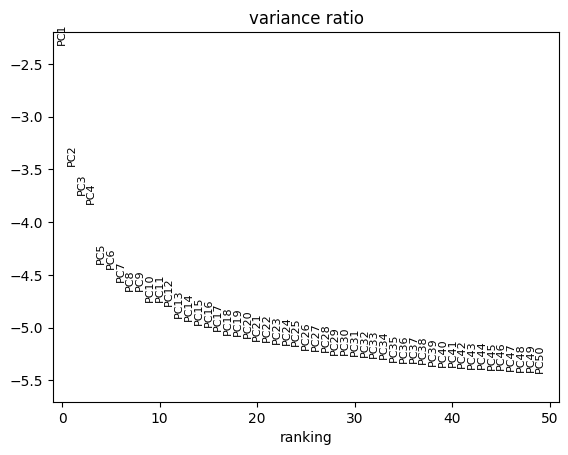

In [ ]:
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)

# UMAP Plot Overview

In [ ]:
len(adata)

504767

In [ ]:
# Subsample to 100 each
drugs = ["BI-3406", "Oxaliplatin", "DMSO_TF"]

# drugs = ["BI-3406", "Paclitaxel", "DMSO_TF"] # top10_drugs
subset = subsample(drugs, num_samples_by_drug=3000)

# subset = adata[(adata.obs['drug'] == "Everolimus") & ((adata.obs["sublibrary"] == "lib_914") | (adata.obs["sublibrary"] == "lib_980") | (adata.obs["sublibrary"] == "lib_979"))] #["sublibrary"].value_counts()
# subset = adata[(adata.obs['drug'] == "Everolimus") & ((adata.obs["phase"] == "lib_914") | (adata.obs["sublibrary"] == "phase") | (adata.obs["phase"] == "lib_979"))] #["sublibrary"].value_counts()

In [ ]:
subset

AnnData object with n_obs × n_vars = 9000 × 1024
    obs: 'sample', 'gene_count', 'tscp_count', 'mread_count', 'drugname_drugconc', 'drug', 'cell_line', 'sublibrary', 'BARCODE', 'pcnt_mito', 'S_score', 'G2M_score', 'phase', 'pass_filter', 'cell_name', 'plate'
    obsm: 'X_pca'
    layers: 'counts'

In [ ]:
# Rename subset DMSO_TF to Control
subset.obs[obs_key] = subset.obs[obs_key].replace({"DMSO_TF": "Control"})

/tmp/ipykernel_3722129/4049465033.py:2: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  subset.obs[obs_key] = subset.obs[obs_key].replace({"DMSO_TF": "Control"})


In [ ]:
sc.pp.neighbors(subset, use_rep="X_pca", n_neighbors=30, n_pcs=30)
# sc.tl.umap(subset)
sc.tl.umap(subset)

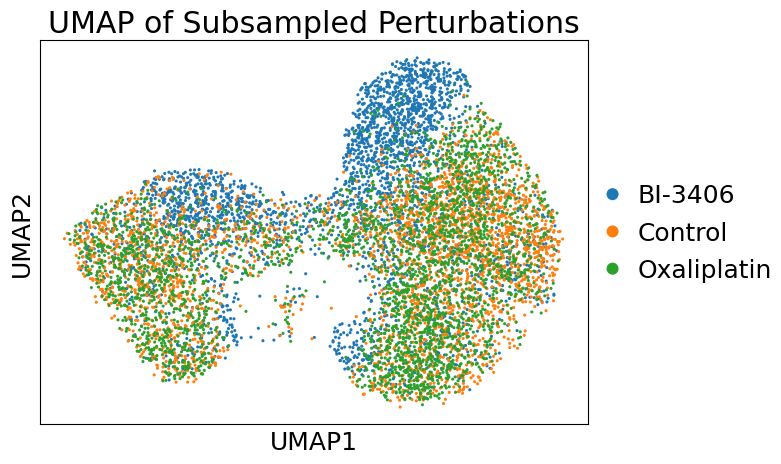

In [ ]:
# Set text size and figure title:
plt.rcParams.update({'font.size': 18})

sc.pl.scatter(subset, basis="umap", color="drug", show=False, title="UMAP of Subsampled Perturbations", legend_fontsize=18, size=20) # color=obs_key

# Save the UMAP plot as a PNG file
plt.savefig("umap_subsampled_perturbations.png", dpi=300, bbox_inches='tight')


In [ ]:
adata.obs['drug'].value_counts()[1:31]

drug
Vemurafenib                  11762
Anastrozole                  10058
Everolimus                    9991
Gemcitabine                   9771
Lonafarnib                    9585
Paclitaxel                    9559
Minodronic acid               9532
Tubulin inhibitor 6           8968
Oxaliplatin                   8950
Adagrasib                     8892
RMC-6236                      8866
olaparib                      8348
4EGI-1                        8235
Regorafenib                   8152
BI-3406                       7882
venetoclax                    7861
DT-061                        7826
ETC-206                       7793
DTP3                          7786
Afatinib                      7762
Torkinib                      7672
Ixazomib                      7379
Capmatinib                    7280
Lapatinib ditosylate          7253
AT7519                        7006
Capivasertib                  6976
Oleic acid                    6918
c-Kit-IN-1                    6870
Infigratinib   

# E-Distance

In [ ]:
top30_drugs = adata.obs['drug'].value_counts().index[1:31].tolist()
edist_subset = subsample(top30_drugs, num_samples_by_drug=500)

In [ ]:
estats = edist(edist_subset, obs_key=obs_key, obsm_key="X_pca", dist="euclidean")
estats

  0%|          | 0/496 [00:00<?, ?it/s]

100%|██████████| 496/496 [00:01<00:00, 267.90it/s]


drug,Vemurafenib,Anastrozole,Everolimus,Gemcitabine,Lonafarnib,Paclitaxel,Minodronic acid,Tubulin inhibitor 6,Oxaliplatin,Adagrasib,RMC-6236,olaparib,4EGI-1,Regorafenib,BI-3406,venetoclax,DT-061,ETC-206,DTP3,Afatinib,Torkinib,Ixazomib,Capmatinib,Lapatinib ditosylate,AT7519,Capivasertib,Oleic acid,c-Kit-IN-1,Infigratinib,Elimusertib hydrochloride,DMSO_TF
drug,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Vemurafenib,0.000000,0.089532,0.065014,0.087430,0.107121,0.088855,0.089147,0.064768,0.098936,0.094434,0.334096,0.096897,0.099224,0.038269,0.497835,0.080572,0.108450,0.117731,0.080823,0.067982,0.157138,0.066951,0.185431,0.068948,0.098228,0.046750,0.092263,0.063705,0.085704,0.277924,0.152053
Anastrozole,0.089532,0.000000,0.099656,0.133747,0.140680,0.167265,0.016262,0.084464,0.013415,0.029171,0.430750,0.037677,0.168368,0.076905,0.628184,0.105510,0.106624,0.062837,0.084442,0.018205,0.066694,0.029608,0.194977,0.069351,0.043557,0.060909,0.021164,0.074241,0.031406,0.352603,0.142740
Everolimus,0.065014,0.099656,0.000000,0.048678,0.106194,0.078792,0.069041,0.021004,0.126532,0.038449,0.331908,0.084576,0.182083,0.037392,0.458691,0.026129,0.040312,0.035721,0.014194,0.067219,0.071771,0.037690,0.105447,0.107093,0.055046,0.034963,0.125369,0.110619,0.043948,0.149216,0.113997
Gemcitabine,0.087430,0.133747,0.048678,0.000000,0.169188,0.131985,0.111666,0.113076,0.174582,0.094233,0.406130,0.114509,0.246552,0.062898,0.531028,0.055341,0.081841,0.085734,0.073187,0.102925,0.100086,0.094944,0.170271,0.113632,0.098737,0.082291,0.154629,0.124860,0.077003,0.198411,0.170845
Lonafarnib,0.107121,0.140680,0.106194,0.169188,0.000000,0.221561,0.109770,0.126742,0.127240,0.107964,0.501989,0.113217,0.152926,0.064275,0.676377,0.120170,0.182450,0.165938,0.147213,0.122890,0.230223,0.115458,0.230896,0.036770,0.154496,0.054564,0.192661,0.080831,0.162857,0.396220,0.122726
Paclitaxel,0.088855,0.167265,0.078792,0.131985,0.221561,0.000000,0.133966,0.099622,0.193906,0.128981,0.122541,0.133086,0.307153,0.080398,0.213569,0.063787,0.083659,0.080272,0.059608,0.081008,0.130287,0.064112,0.065907,0.202621,0.120751,0.124386,0.164902,0.136134,0.101332,0.101102,0.292292
Minodronic acid,0.089147,0.016262,0.069041,0.111666,0.109770,0.133966,0.000000,0.059392,0.024896,0.013948,0.377123,0.022122,0.174907,0.055383,0.567948,0.095916,0.083453,0.031768,0.050255,0.023236,0.058357,0.022205,0.169540,0.065607,0.029908,0.047596,0.040022,0.091197,0.042257,0.290807,0.130409
Tubulin inhibitor 6,0.064768,0.084464,0.021004,0.113076,0.126742,0.099622,0.059392,0.000000,0.078386,0.055577,0.305673,0.097195,0.160500,0.052078,0.460575,0.056431,0.028059,0.052876,0.012506,0.064819,0.091487,0.031461,0.115691,0.113795,0.051905,0.029214,0.088788,0.113861,0.045688,0.181299,0.132804
Oxaliplatin,0.098936,0.013415,0.126532,0.174582,0.127240,0.193906,0.024896,0.078386,0.000000,0.064569,0.411180,0.064360,0.140394,0.100727,0.596508,0.114407,0.127422,0.095491,0.098781,0.044247,0.140445,0.040374,0.174260,0.066054,0.078922,0.046506,0.065747,0.056484,0.063153,0.357168,0.171315


In [ ]:
df = etest(edist_subset, obs_key=obs_key, obsm_key='X_pca', dist='euclidean', control='DMSO_TF', alpha=0.05, runs=1000, n_jobs=-1)

100%|██████████| 1000/1000 [00:21<00:00, 47.44it/s]
/system/apps/studentenv/mkindler/cellpert/lib/python3.11/site-packages/statsmodels/stats/multitest.py:186: RuntimeWarning: divide by zero encountered in log1p
  np.log1p(-pvals))


In [ ]:
df

,edist,pvalue,significant,pvalue_adj,significant_adj
4EGI-1,0.163548,0.001,True,0.030539,True
AT7519,0.097061,0.001,True,0.030539,True
Adagrasib,0.063264,0.001,True,0.030539,True
Afatinib,0.156043,0.001,True,0.030539,True
Anastrozole,0.142737,0.001,True,0.030539,True
BI-3406,0.755581,0.001,True,0.030539,True
Capivasertib,0.096749,0.001,True,0.030539,True
Capmatinib,0.312588,0.001,True,0.030539,True
DMSO_TF,0.000000,1.000,False,1.000000,False
DT-061,0.162291,0.001,True,0.030539,True


In [ ]:
# E-Distance Formula = 2 * E(X, Y) - E(X, X) - E(Y, Y) = 2 * mean of pairwise distances between X and Y - mean of pairwise distances within X - mean of pairwise distances within Y

# top30_drugs = adata.obs['drug'].value_counts().index[1:31].tolist()
# edist_subset = subsample(top30_drugs, num_samples_by_drug=500)

distance = pt.tl.Distance("edistance", obsm_key="X_pca")
df_edist = distance.pairwise(edist_subset, groupby=obs_key)
df_edist = df_edist.rename(index={"DMSO_TF": "Control"}, columns={"DMSO_TF": "Control"})

Output()

In [ ]:
order = estats["DMSO_TF"].sort_values(ascending=False).index.tolist()[:-1] # Drop the last element which is "Control" 
order

['BI-3406',
 'RMC-6236',
 'Elimusertib hydrochloride',
 'Capmatinib',
 'Paclitaxel',
 'c-Kit-IN-1',
 'venetoclax',
 'Oxaliplatin',
 'Gemcitabine',
 'Torkinib',
 '4EGI-1',
 'Oleic acid',
 'DT-061',
 'ETC-206',
 'Infigratinib',
 'Afatinib',
 'Vemurafenib',
 'Ixazomib',
 'Anastrozole',
 'olaparib',
 'DTP3',
 'Tubulin inhibitor 6',
 'Minodronic acid',
 'Lonafarnib',
 'Regorafenib',
 'Everolimus',
 'Lapatinib ditosylate',
 'AT7519',
 'Capivasertib',
 'Adagrasib']

In [ ]:
# Control on top and then sort alphabetically
df_edist = df_edist.reindex(sorted(df_edist.columns), axis=1)
df_edist = df_edist.reindex(sorted(df_edist.index), axis=0)

# Control on top 
# df_edist = df_edist.reindex(["Control"] + [col for col in df_edist.columns if col != "Control"], axis=1)
# df_edist = df_edist.reindex(["Control"] + [row for row in df_edist.index if row != "Control"], axis=0)
df_edist = df_edist.reindex(["Control"] + order, axis=1)
df_edist = df_edist.reindex(["Control"] + order, axis=0)

df_edist

drug,Control,BI-3406,RMC-6236,Elimusertib hydrochloride,Capmatinib,Paclitaxel,c-Kit-IN-1,venetoclax,Oxaliplatin,Gemcitabine,Torkinib,4EGI-1,Oleic acid,DT-061,ETC-206,Infigratinib,Afatinib,Vemurafenib,Ixazomib,Anastrozole,olaparib,DTP3,Tubulin inhibitor 6,Minodronic acid,Lonafarnib,Regorafenib,Everolimus,Lapatinib ditosylate,AT7519,Capivasertib,Adagrasib
drug,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Control,0.000000,0.805105,0.613523,0.442677,0.361640,0.342155,0.274895,0.232513,0.221031,0.220253,0.217042,0.214009,0.213239,0.212117,0.209457,0.209517,0.205691,0.202073,0.197806,0.192639,0.188079,0.183589,0.182598,0.180063,0.172395,0.165811,0.163651,0.158490,0.147334,0.146554,0.113534
BI-3406,0.805105,0.000000,0.081404,0.213691,0.234233,0.262633,0.582119,0.386377,0.645428,0.579645,0.608035,0.866914,0.658870,0.395202,0.473768,0.516570,0.485469,0.547057,0.451106,0.677293,0.568818,0.399405,0.509573,0.616810,0.725247,0.521096,0.507548,0.722480,0.520185,0.559171,0.570945
RMC-6236,0.613523,0.081404,0.000000,0.178798,0.175860,0.172015,0.445801,0.299696,0.460508,0.455156,0.440471,0.650002,0.430547,0.259278,0.329372,0.373097,0.331710,0.383731,0.316352,0.480266,0.383119,0.275590,0.355080,0.426392,0.551272,0.367515,0.381175,0.536672,0.346576,0.404389,0.416396
Elimusertib hydrochloride,0.442677,0.213691,0.178798,0.000000,0.124989,0.149460,0.374473,0.181884,0.405383,0.246322,0.271379,0.570608,0.394596,0.157921,0.206529,0.266996,0.281384,0.326441,0.248062,0.401001,0.310890,0.160158,0.229590,0.338960,0.444384,0.251076,0.197365,0.443527,0.256254,0.274460,0.300694
Capmatinib,0.361640,0.234233,0.175860,0.124989,0.000000,0.114502,0.195848,0.090465,0.222711,0.218417,0.232367,0.430660,0.273445,0.114840,0.163320,0.162405,0.137165,0.234186,0.123314,0.243612,0.187899,0.123543,0.164220,0.217929,0.279297,0.167412,0.153833,0.273088,0.181744,0.173149,0.196264
Paclitaxel,0.342155,0.262633,0.172015,0.149460,0.114502,0.000000,0.185035,0.112895,0.243165,0.180940,0.179613,0.357157,0.214766,0.133026,0.129748,0.150925,0.130198,0.138416,0.113661,0.216711,0.182150,0.109385,0.148961,0.183166,0.270771,0.129423,0.127987,0.251860,0.170567,0.173733,0.178795
c-Kit-IN-1,0.274895,0.582119,0.445801,0.374473,0.195848,0.185035,0.000000,0.102858,0.105240,0.173311,0.243592,0.226380,0.188411,0.211627,0.186102,0.137597,0.119376,0.112765,0.111077,0.123181,0.153140,0.176856,0.162695,0.139891,0.129542,0.114390,0.159310,0.108260,0.195849,0.111541,0.160947
venetoclax,0.232513,0.386377,0.299696,0.181884,0.090465,0.112895,0.102858,0.000000,0.163372,0.104000,0.170003,0.286597,0.198701,0.092463,0.110209,0.085378,0.103581,0.129840,0.075177,0.154660,0.149205,0.079045,0.105473,0.144821,0.169084,0.100495,0.075028,0.162856,0.131732,0.104016,0.108552
Oxaliplatin,0.221031,0.645428,0.460508,0.405383,0.222711,0.243165,0.105240,0.163372,0.000000,0.223392,0.189624,0.190257,0.115468,0.176646,0.144821,0.112601,0.093291,0.148355,0.089780,0.062713,0.113282,0.148414,0.127579,0.073950,0.176305,0.149610,0.175582,0.115146,0.128596,0.095710,0.114236


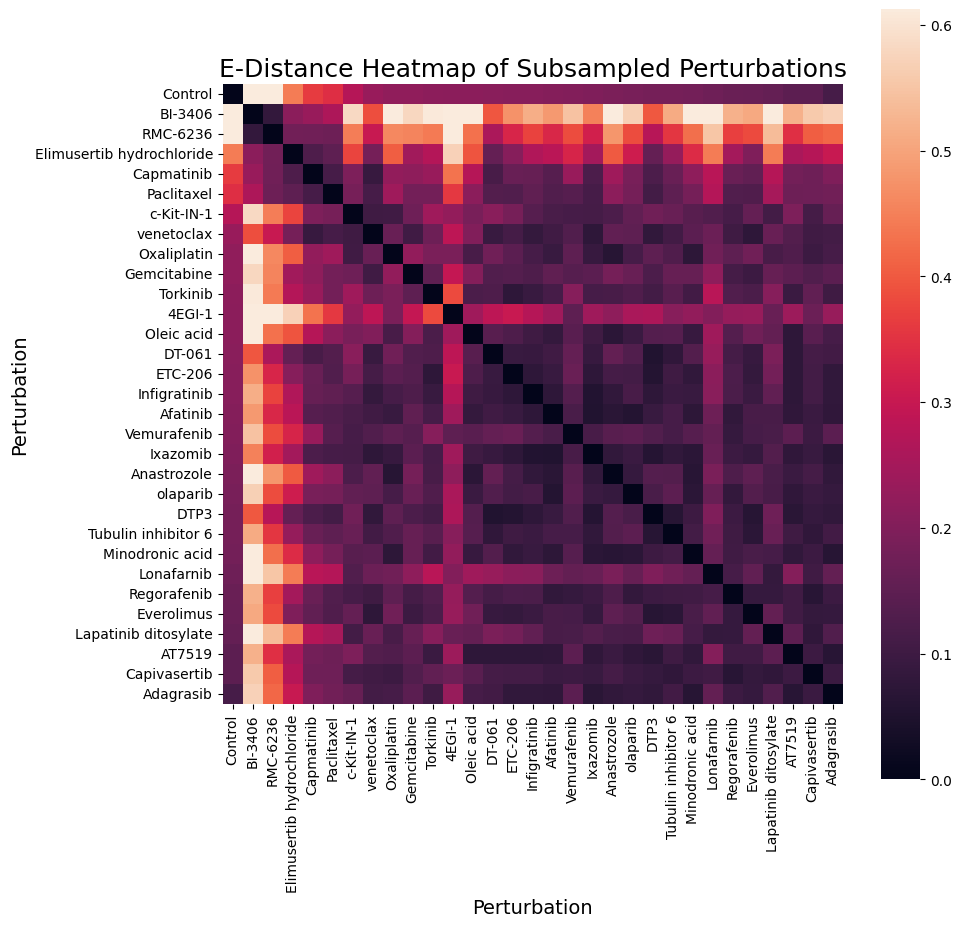

In [ ]:
plt.figure(figsize=(10, 10))
# Fontsize to 14
plt.rcParams.update({'font.size': 10})

heatmap(df_edist, robust=True)
# heatmap(estats, robust=True)

# Set the title of the heatmap
plt.title("E-Distance Heatmap of Subsampled Perturbations", fontsize=18)

# Set the x-axis and y-axis labels
plt.xlabel("Perturbation", fontsize=14)
plt.ylabel("Perturbation", fontsize=14)

# Set height equal to width for square cells
plt.gca().set_aspect('equal', adjustable='box')

# Save the heatmap as a PNG file
plt.savefig("edistance_heatmap.png", dpi=300, bbox_inches='tight')

plt.show()

In [ ]:
etest = pt.tl.DistanceTest("edistance", n_perms=1000, obsm_key="X_pca", alpha=0.05)
tab = etest(edist_subset, groupby=obs_key, contrast=contrast)

Output()

In [ ]:
tab

,distance,pvalue,significant,pvalue_adj,significant_adj
Vemurafenib,0.202073,0.001,True,0.030539,True
Anastrozole,0.192639,0.001,True,0.030539,True
Everolimus,0.163651,0.001,True,0.030539,True
Gemcitabine,0.220253,0.001,True,0.030539,True
Lonafarnib,0.172395,0.001,True,0.030539,True
Paclitaxel,0.342155,0.001,True,0.030539,True
Minodronic acid,0.180063,0.001,True,0.030539,True
Tubulin inhibitor 6,0.182598,0.001,True,0.030539,True
Oxaliplatin,0.221031,0.001,True,0.030539,True
Adagrasib,0.113534,0.001,True,0.030539,True


In [ ]:
tab["significant_adj"]["DMSO_TF"] = "control"

/tmp/ipykernel_3617007/2225119794.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  tab["significant_adj"]["DMSO_TF"] = "control"
/tmp/ipykernel_3617007/2225119794.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a s

2026-10-18 14:25:03 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-10-18 14:25:03 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-18 14:25:03 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.
2026-10-18 14:25:03 | [INFO] Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


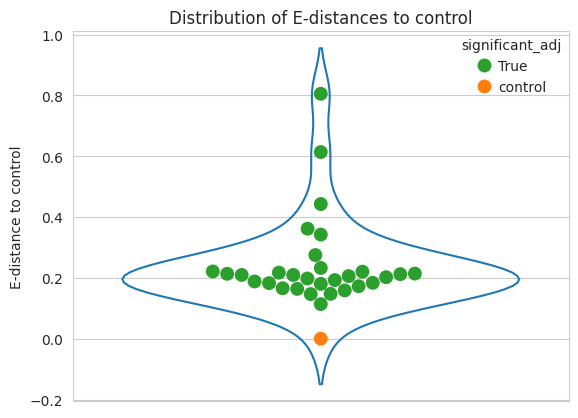

In [ ]:
with sns.axes_style('whitegrid'):
    sns.violinplot(data=tab, x=[0]*len(tab), y='distance', inner=None, fill=False)
    sns.swarmplot(data=tab, x=[0]*len(tab), y='distance', size=10, hue='significant_adj', dodge=False, palette={True: 'tab:green', False: 'tab:red', 'control': 'tab:orange'}, )
plt.xticks([0], [''], )
plt.ylabel('E-distance to control')
plt.title('Distribution of E-distances to control')
plt.show()

/system/apps/studentenv/mkindler/cellpert/lib/python3.11/site-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,
/system/apps/studentenv/mkindler/cellpert/lib/python3.11/site-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,


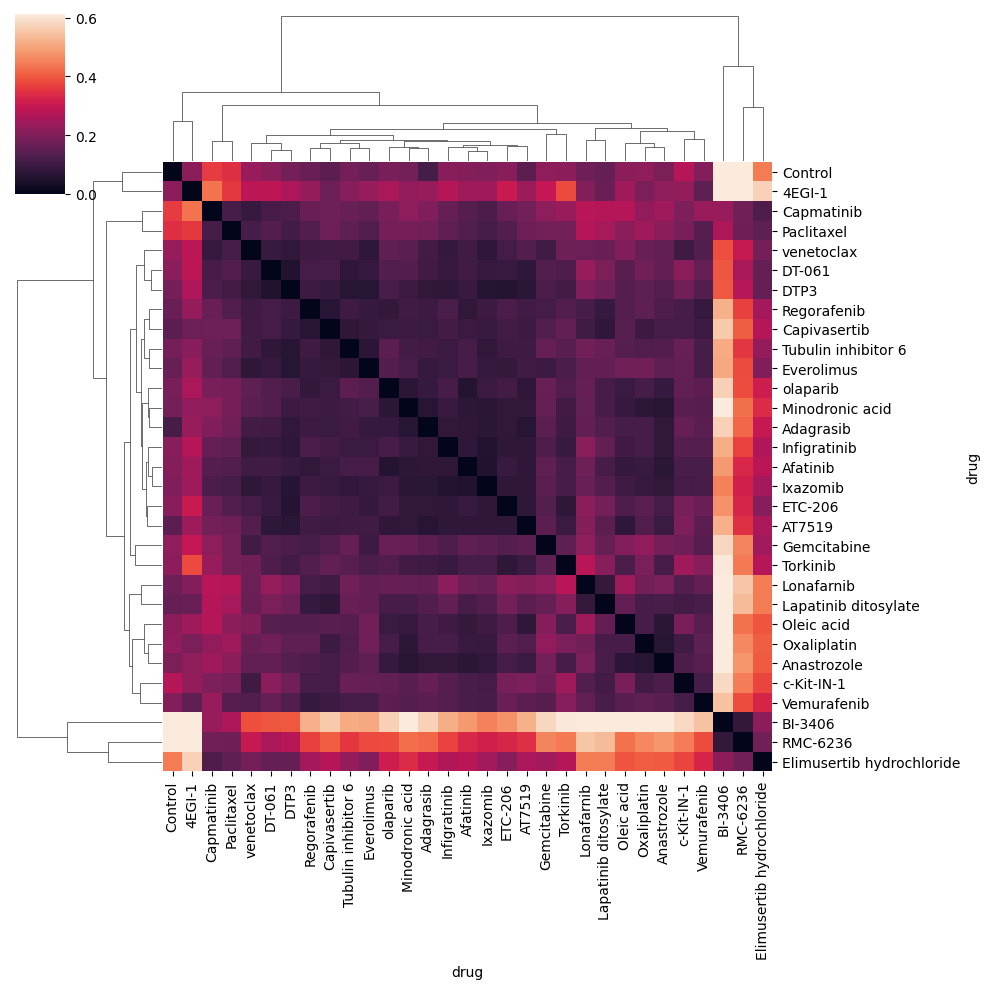

In [ ]:
clustermap(df_edist, robust=True, figsize=(10, 10))
plt.show()

### Statistical Distance Test using the Etest

In [ ]:
etest = pt.tl.DistanceTest("edistance", n_perms=1000, obsm_key="X_pca", alpha=0.0015)
tab = etest(edist_subset, groupby=obs_key, contrast=contrast)

Output()

In [ ]:
tab.head(100)

,distance,pvalue,significant,pvalue_adj,significant_adj
Vemurafenib,0.202073,0.001,True,0.030539,False
Anastrozole,0.192639,0.001,True,0.030539,False
Everolimus,0.163651,0.001,True,0.030539,False
Gemcitabine,0.220253,0.001,True,0.030539,False
Lonafarnib,0.172395,0.001,True,0.030539,False
Paclitaxel,0.342155,0.001,True,0.030539,False
Minodronic acid,0.180063,0.001,True,0.030539,False
Tubulin inhibitor 6,0.182598,0.001,True,0.030539,False
Oxaliplatin,0.221031,0.001,True,0.030539,False
Adagrasib,0.113534,0.001,True,0.030539,False


No statistical significant difference between control and perturbed cells. 

#  MSE

In [ ]:
mse_subset = subsample(top30_drugs, num_samples_by_drug=500)

distance = pt.tl.Distance(metric="mse", obsm_key="X_pca")
df_mse = distance.pairwise(mse_subset, groupby=obs_key)

Output()

/system/apps/studentenv/mkindler/cellpert/lib/python3.11/site-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,
/system/apps/studentenv/mkindler/cellpert/lib/python3.11/site-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,


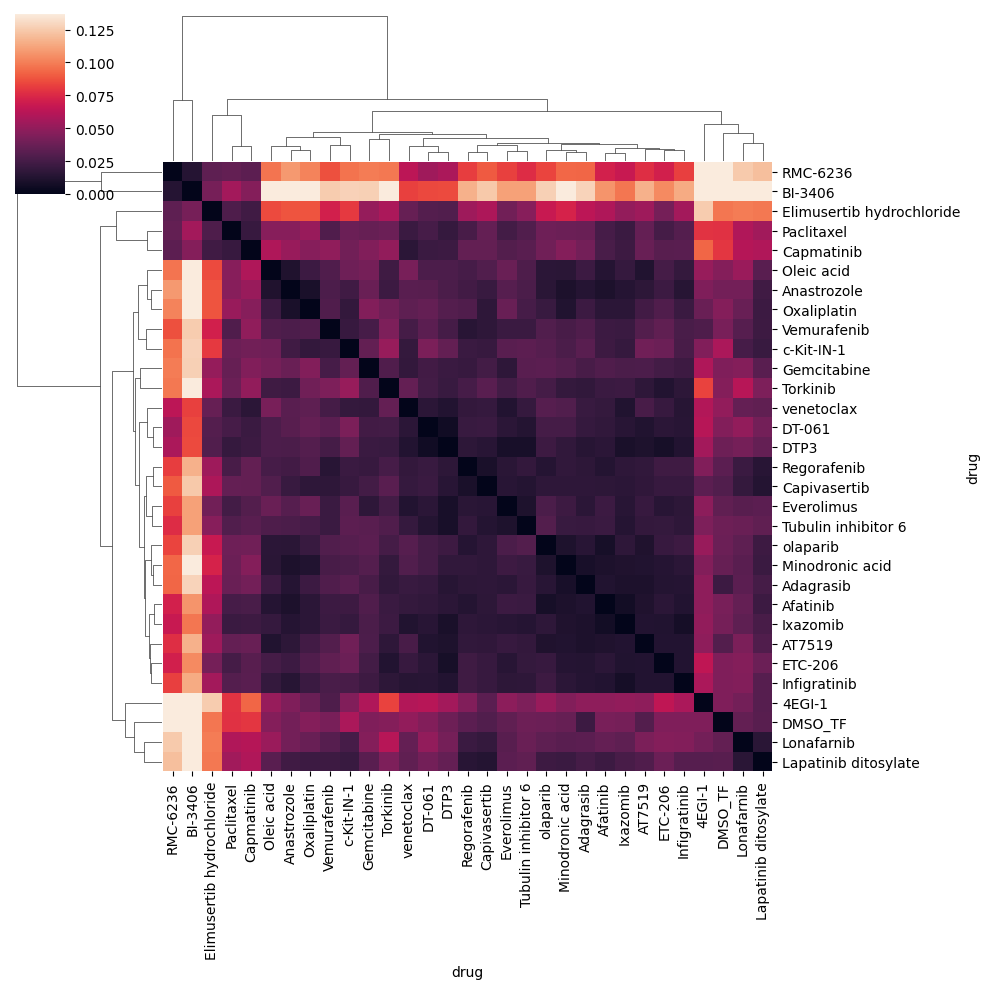

In [ ]:
clustermap(df_mse, robust=True, figsize=(10, 10))
plt.show()

In [ ]:
df_mse["DMSO_TF"].sort_values(ascending=False)

drug
BI-3406                      0.185530
RMC-6236                     0.141892
Elimusertib hydrochloride    0.097691
Capmatinib                   0.079464
Paclitaxel                   0.077663
c-Kit-IN-1                   0.058202
venetoclax                   0.050007
Torkinib                     0.045847
Oxaliplatin                  0.045760
Oleic acid                   0.045667
DT-061                       0.045055
Gemcitabine                  0.044346
ETC-206                      0.044219
4EGI-1                       0.044071
Infigratinib                 0.043994
Vemurafenib                  0.042177
Afatinib                     0.041873
Ixazomib                     0.040931
Anastrozole                  0.040109
DTP3                         0.038471
Tubulin inhibitor 6          0.038444
olaparib                     0.037580
Minodronic acid              0.035912
Lonafarnib                   0.035095
Everolimus                   0.034036
Regorafenib                  0.032320
Lapatin

# Wasserstein Distance

In [ ]:
wasserstein_subset = subsample(top30_drugs, num_samples_by_drug=500)

distance = pt.tl.Distance("wasserstein", obsm_key="X_pca")
df_wasserstein = distance.pairwise(wasserstein_subset, groupby=obs_key)

Output()

2026-10-18 14:28:41 | [INFO] Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-10-18 14:28:41 | [WARNING] An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.


/system/apps/studentenv/mkindler/cellpert/lib/python3.11/site-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,
/system/apps/studentenv/mkindler/cellpert/lib/python3.11/site-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,


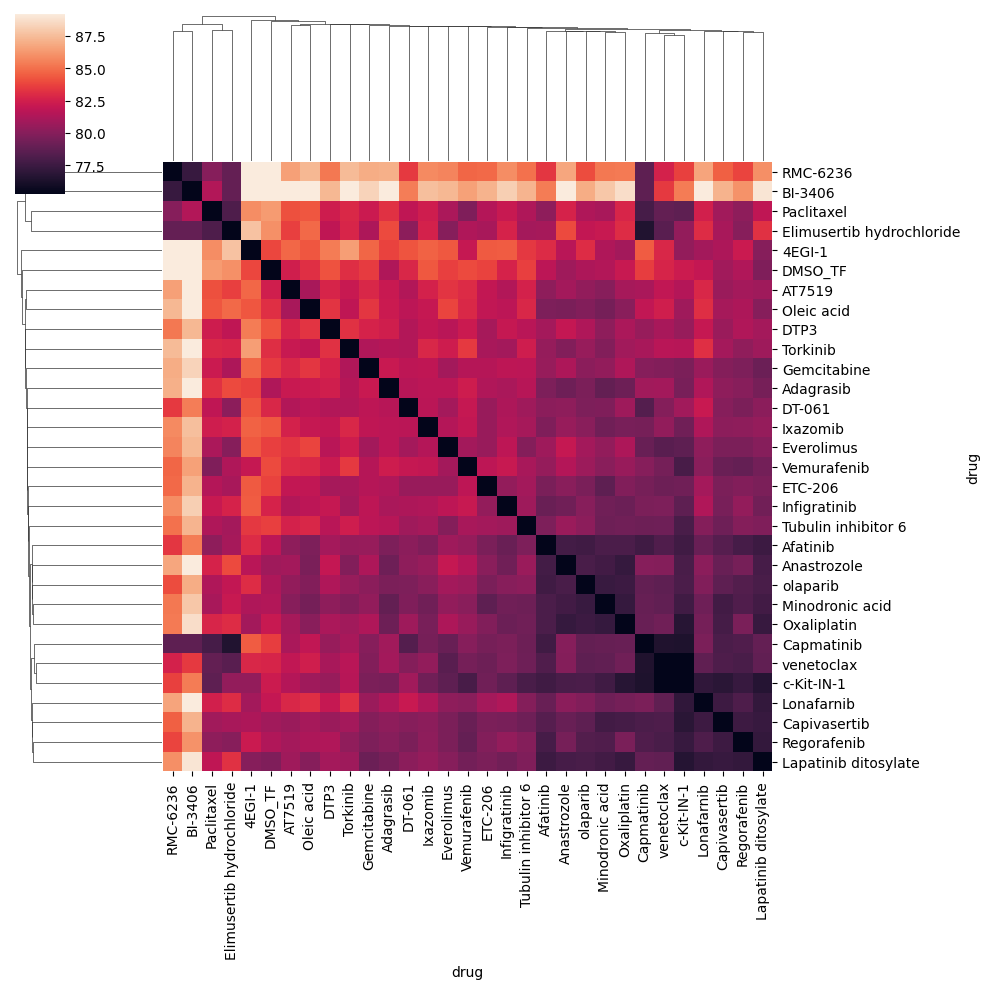

In [ ]:
values = np.ravel(df_wasserstein.values)
nonzero = values[values != 0]
vmin = np.min(nonzero)
clustermap(df_wasserstein, robust=True, figsize=(10, 10), vmin=vmin)
plt.show()

In [ ]:
df_wasserstein["DMSO_TF"].sort_values(ascending=False)

drug
BI-3406                      93.411741
RMC-6236                     90.534043
Paclitaxel                   86.335085
Elimusertib hydrochloride    85.972678
Ixazomib                     84.313402
DTP3                         84.167886
Vemurafenib                  83.947441
4EGI-1                       83.817737
ETC-206                      83.701122
Everolimus                   83.620792
Tubulin inhibitor 6          83.619587
Capmatinib                   83.543218
Gemcitabine                  83.490104
Oleic acid                   83.139667
Torkinib                     83.051817
DT-061                       82.819983
venetoclax                   82.704376
Infigratinib                 82.638608
AT7519                       82.431250
c-Kit-IN-1                   82.239072
Oxaliplatin                  82.097778
Lonafarnib                   81.978545
Afatinib                     81.739915
Minodronic acid              81.387687
Regorafenib                  81.347252
Adagrasib           

# Maximum Mean Discrepancy

In [ ]:
mmd_subset = subsample(top30_drugs, num_samples_by_drug=500)

distance = pt.tl.Distance("mmd", obsm_key="X_pca")
df_mmd = distance.pairwise(mmd_subset, groupby=obs_key)

Output()

/system/apps/studentenv/mkindler/cellpert/lib/python3.11/site-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,
/system/apps/studentenv/mkindler/cellpert/lib/python3.11/site-packages/seaborn/matrix.py:530: ClusterWarning: The symmetric non-negative hollow observation matrix looks suspiciously like an uncondensed distance matrix
  linkage = hierarchy.linkage(self.array, method=self.method,


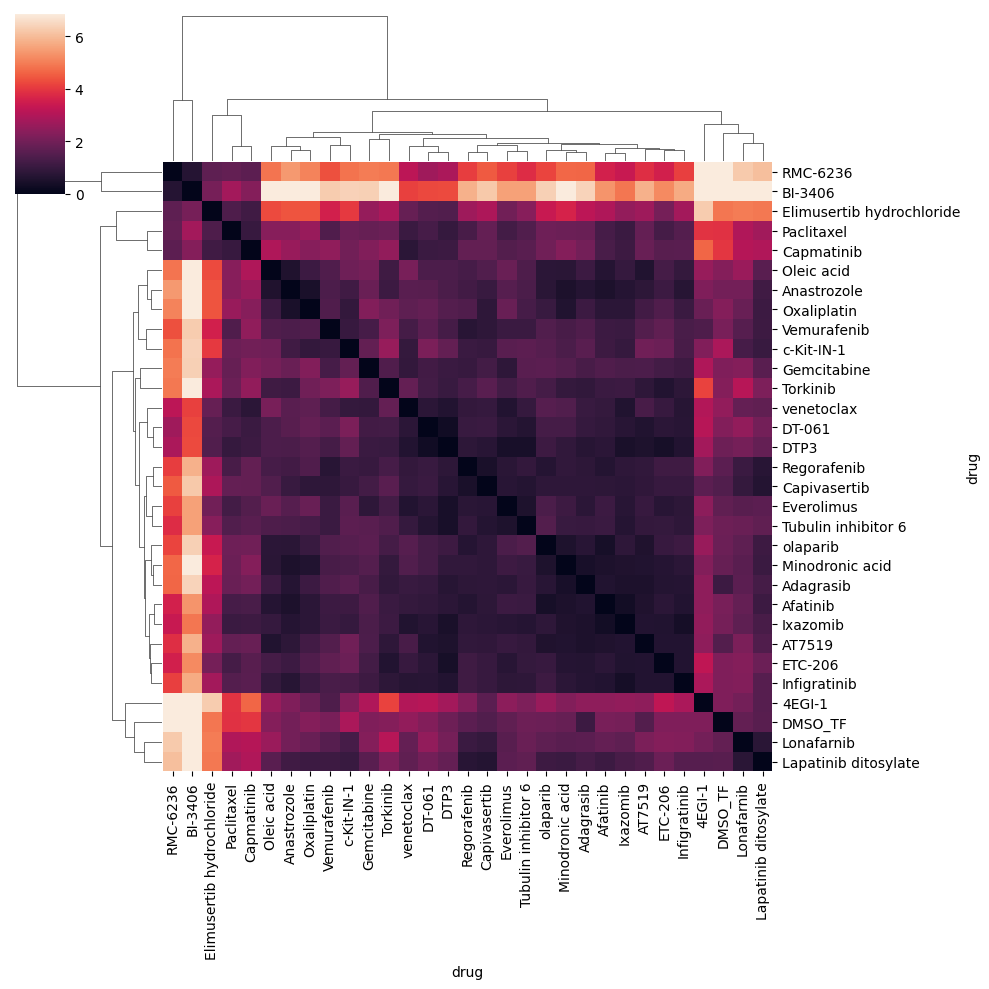

In [ ]:
clustermap(df_mmd, robust=True, figsize=(10, 10))
plt.show()

In [ ]:
df_wasserstein["DMSO_TF"].sort_values(ascending=False)

drug
BI-3406                      93.411741
RMC-6236                     90.534043
Paclitaxel                   86.335085
Elimusertib hydrochloride    85.972678
Ixazomib                     84.313402
DTP3                         84.167886
Vemurafenib                  83.947441
4EGI-1                       83.817737
ETC-206                      83.701122
Everolimus                   83.620792
Tubulin inhibitor 6          83.619587
Capmatinib                   83.543218
Gemcitabine                  83.490104
Oleic acid                   83.139667
Torkinib                     83.051817
DT-061                       82.819983
venetoclax                   82.704376
Infigratinib                 82.638608
AT7519                       82.431250
c-Kit-IN-1                   82.239072
Oxaliplatin                  82.097778
Lonafarnib                   81.978545
Afatinib                     81.739915
Minodronic acid              81.387687
Regorafenib                  81.347252
Adagrasib           

In [ ]:
df_mmd["DMSO_TF"].sort_values(ascending=False)

drug
BI-3406                      9.276494
RMC-6236                     7.094604
Elimusertib hydrochloride    4.884543
Capmatinib                   3.973186
Paclitaxel                   3.883170
c-Kit-IN-1                   2.910109
venetoclax                   2.500326
Torkinib                     2.292351
Oxaliplatin                  2.288009
Oleic acid                   2.283350
DT-061                       2.252750
Gemcitabine                  2.217319
ETC-206                      2.210927
4EGI-1                       2.203546
Infigratinib                 2.199723
Vemurafenib                  2.108842
Afatinib                     2.093654
Ixazomib                     2.046542
Anastrozole                  2.005450
DTP3                         1.923551
Tubulin inhibitor 6          1.922225
olaparib                     1.878983
Minodronic acid              1.795580
Lonafarnib                   1.754760
Everolimus                   1.701807
Regorafenib                  1.615986
Lapatin

# Differential Gene Expression

In [ ]:
dge_subset = subsample(top30_drugs, num_samples_by_drug=500)

sc.tl.rank_genes_groups(dge_subset, groupby='drug', reference='DMSO_TF', method='wilcoxon')#, n_genes=1000)

/system/apps/studentenv/mkindler/cellpert/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:458: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "names"] = self.var_names[global_indices]
/system/apps/studentenv/mkindler/cellpert/lib/python3.11/site-packages/scanpy/tools/_rank_genes_groups.py:460: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  self.stats[group_name, "scores"] = scores[global_indices]
/system/apps/studentenv/mkindler/cellpert/lib/python3.11/site-packages/scanpy/tools/_rank_genes_g

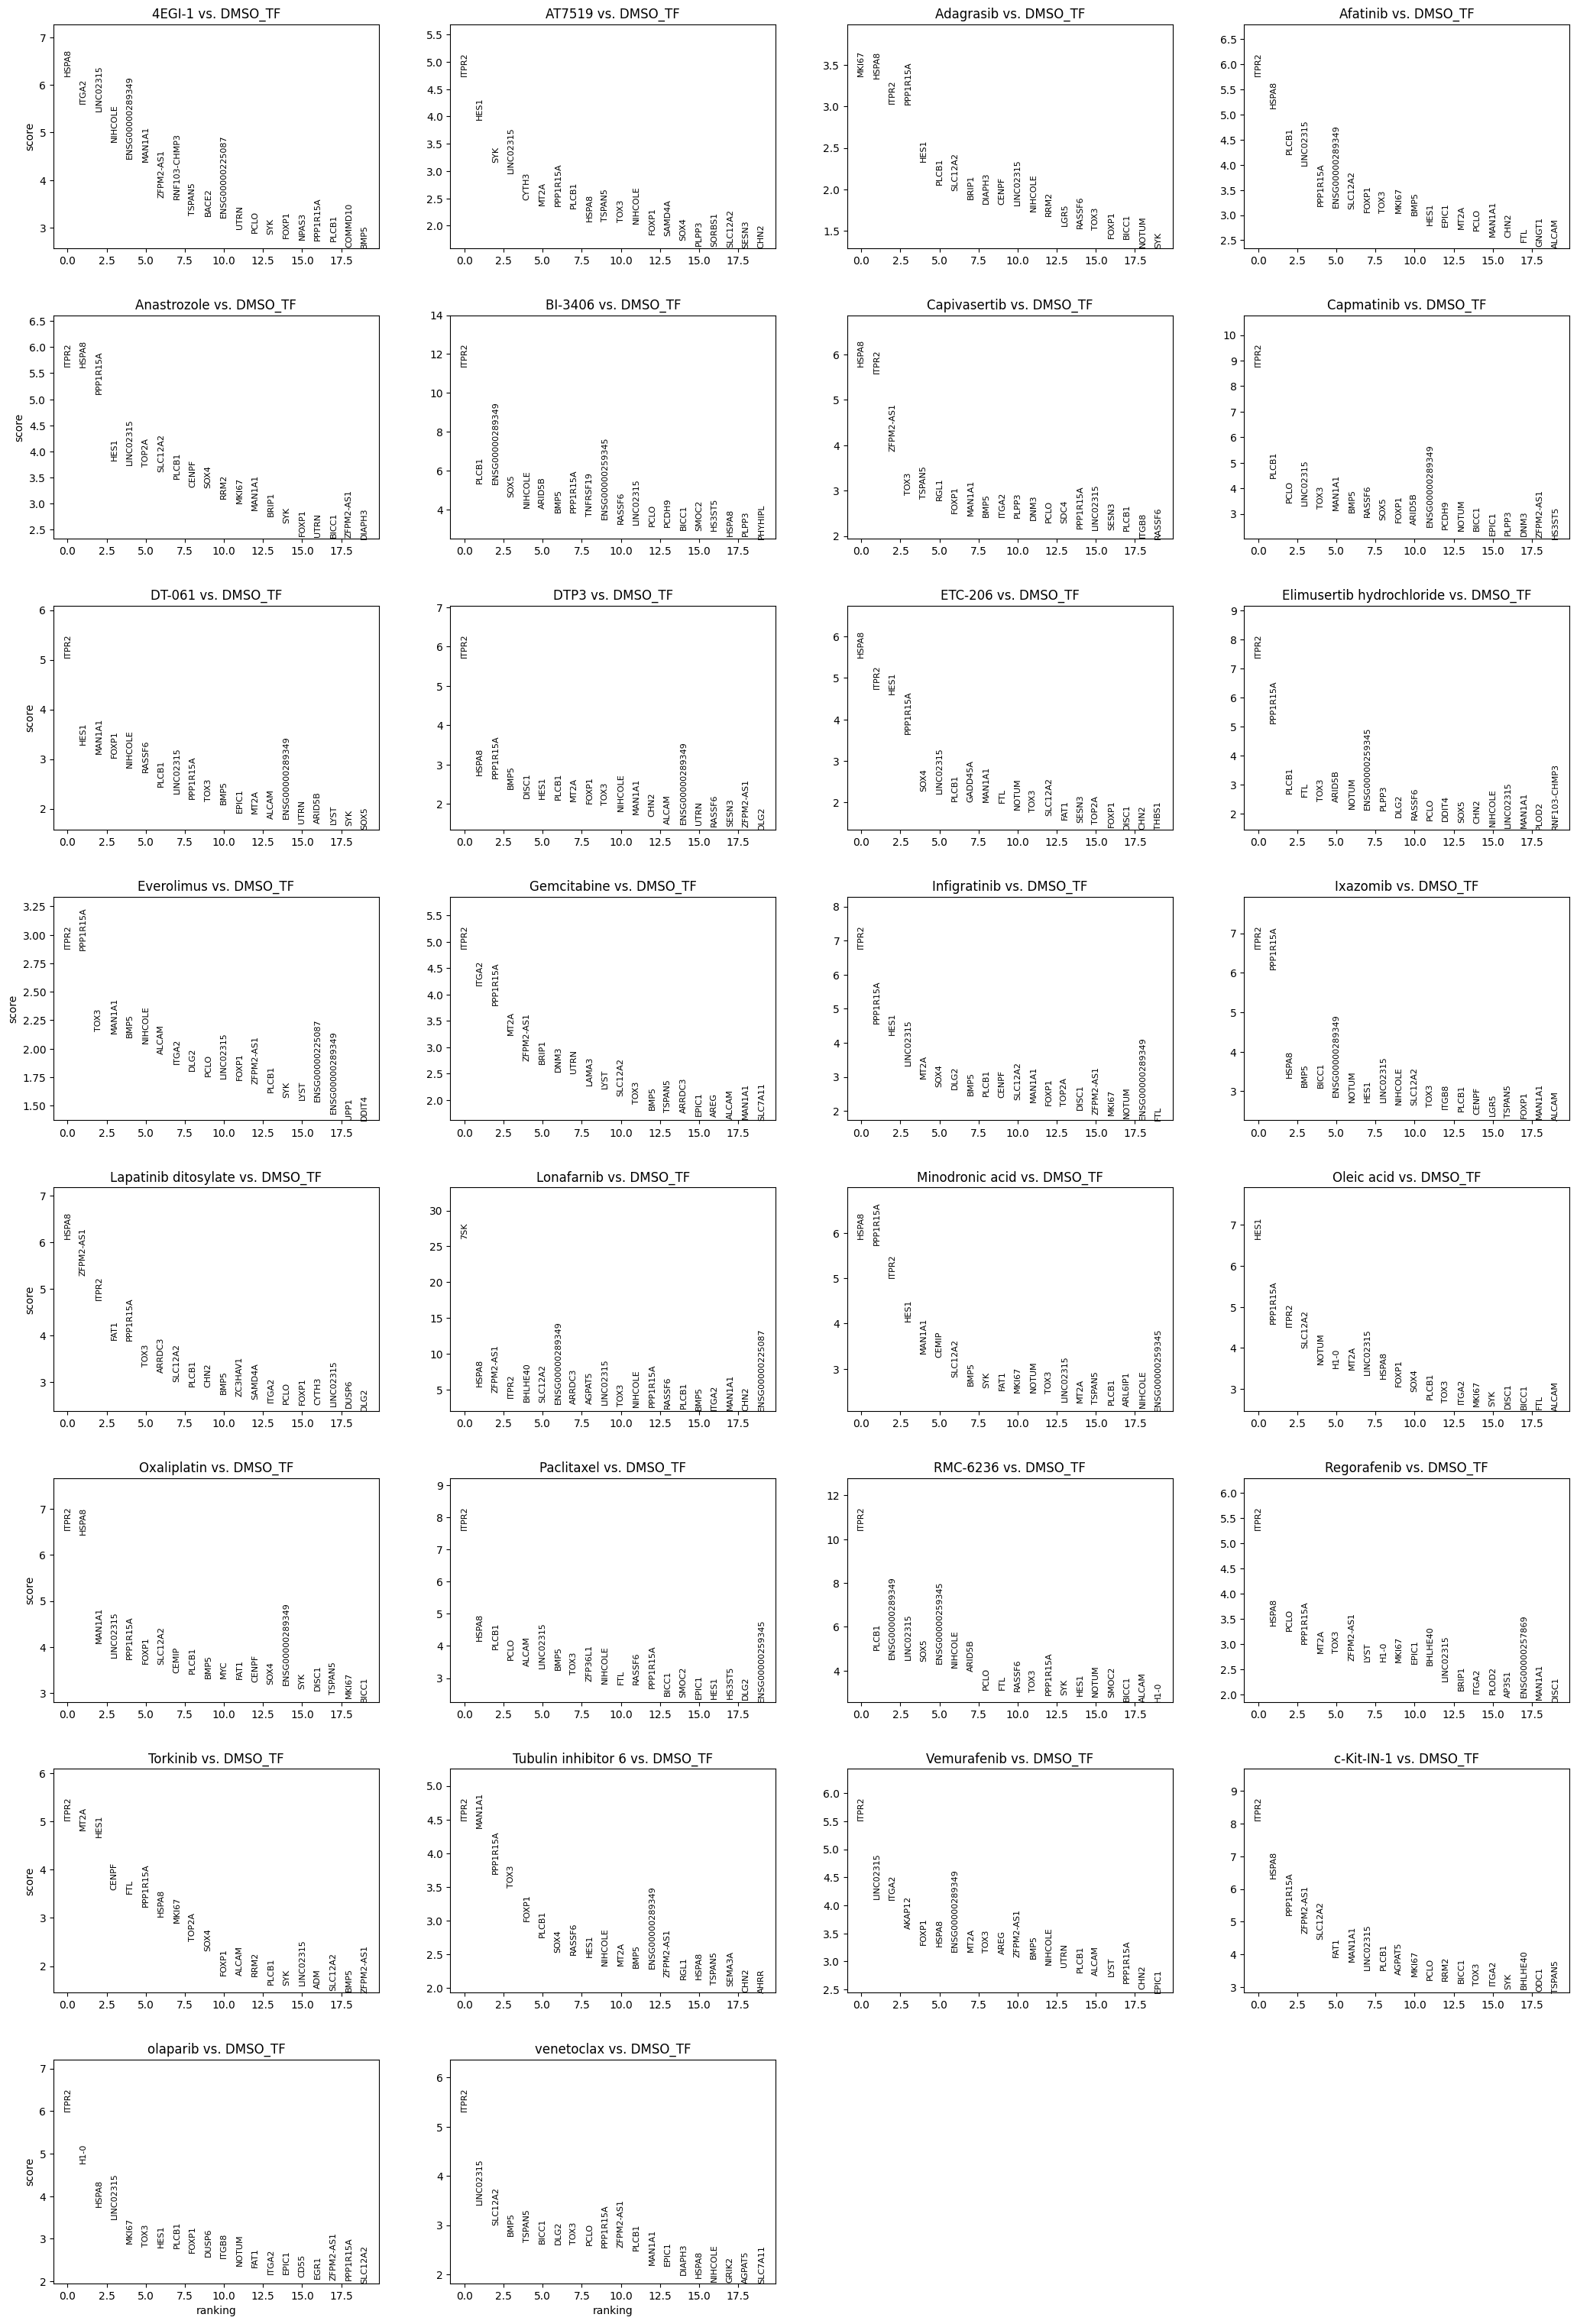

In [ ]:
sc.pl.rank_genes_groups(dge_subset, n_genes=20, sharey=False)

In [ ]:
x = torch.from_numpy(np.array([1, 2, 3, 4, 5]))
y = torch.from_numpy(np.array([2, 3, 4, 5, 6]))
torch.concat((y, x))

tensor([2, 3, 4, 5, 6, 1, 2, 3, 4, 5])

In [ ]:
x = torch.tensor([1, 2, 3, 4, 5])
y = torch.tensor([2, 3, 4, 5, 6])
torch.concat((y, x))

tensor([2, 3, 4, 5, 6, 1, 2, 3, 4, 5])

In [ ]:
def calc_de_genes(drug):
    result = sc.get.rank_genes_groups_df(dge_subset, group=drug)

    # Filter for significantly DE genes using both p-value and fold change thresholds
    de_genes = result[
        (result['pvals_adj'] < 0.05) &
        (result['logfoldchanges'].abs() > 0.5) 
    ]
    print(30*"-")
    print(drug)
    print(f"Number of significant DE genes: {len(de_genes)}")
    return len(de_genes)


drug_de_counts = {}
for drug in top30_drugs:
    drug_de_counts[drug] = calc_de_genes(drug)

drug_de_counts["DMSO_TF"] = 0

------------------------------
Vemurafenib
Number of significant DE genes: 6
------------------------------
Anastrozole
Number of significant DE genes: 9
------------------------------
Everolimus
Number of significant DE genes: 3
------------------------------
Gemcitabine
Number of significant DE genes: 8
------------------------------
Lonafarnib
Number of significant DE genes: 5
------------------------------
Paclitaxel
Number of significant DE genes: 11
------------------------------
Minodronic acid
Number of significant DE genes: 6
------------------------------
Tubulin inhibitor 6
Number of significant DE genes: 7
------------------------------
Oxaliplatin
Number of significant DE genes: 8
------------------------------
Adagrasib
Number of significant DE genes: 1
------------------------------
RMC-6236
Number of significant DE genes: 23
------------------------------
olaparib
Number of significant DE genes: 6
------------------------------
4EGI-1
Number of significant DE genes: 10


In [ ]:
drug_de_counts_df = pd.DataFrame.from_dict(drug_de_counts, orient='index', columns=['num_de_genes'])
drug_de_counts_df = drug_de_counts_df.sort_values(by='num_de_genes', ascending=False)
drug_de_counts_df.head(20)

,num_de_genes
BI-3406,33
RMC-6236,23
Elimusertib hydrochloride,16
Capmatinib,12
c-Kit-IN-1,12
Paclitaxel,11
4EGI-1,10
ETC-206,9
Anastrozole,9
Oxaliplatin,8


In [ ]:
df_edist["DMSO_TF"].sort_values(ascending=False)

drug
BI-3406                      0.805105
RMC-6236                     0.613523
Elimusertib hydrochloride    0.442677
Capmatinib                   0.361640
Paclitaxel                   0.342155
c-Kit-IN-1                   0.274895
venetoclax                   0.232513
Oxaliplatin                  0.221031
Gemcitabine                  0.220253
Torkinib                     0.217042
4EGI-1                       0.214009
Oleic acid                   0.213239
DT-061                       0.212117
Infigratinib                 0.209517
ETC-206                      0.209457
Afatinib                     0.205691
Vemurafenib                  0.202073
Ixazomib                     0.197806
Anastrozole                  0.192639
olaparib                     0.188079
DTP3                         0.183589
Tubulin inhibitor 6          0.182598
Minodronic acid              0.180063
Lonafarnib                   0.172395
Regorafenib                  0.165811
Everolimus                   0.163651
Lapatin

In [ ]:
df_mse["DMSO_TF"].sort_values(ascending=False) 

drug
BI-3406                      0.185530
RMC-6236                     0.141892
Elimusertib hydrochloride    0.097691
Capmatinib                   0.079464
Paclitaxel                   0.077663
c-Kit-IN-1                   0.058202
venetoclax                   0.050007
Torkinib                     0.045847
Oxaliplatin                  0.045760
Oleic acid                   0.045667
DT-061                       0.045055
Gemcitabine                  0.044346
ETC-206                      0.044219
4EGI-1                       0.044071
Infigratinib                 0.043994
Vemurafenib                  0.042177
Afatinib                     0.041873
Ixazomib                     0.040931
Anastrozole                  0.040109
DTP3                         0.038471
Tubulin inhibitor 6          0.038444
olaparib                     0.037580
Minodronic acid              0.035912
Lonafarnib                   0.035095
Everolimus                   0.034036
Regorafenib                  0.032320
Lapatin

In [ ]:
import numpy as np

d = {"X": 4.5, "Y": 3.2, "Z": 5.1}

list(d.values())

[4.5, 3.2, 5.1]

In [ ]:
list(drug_de_counts_df.index) + ["DMSO_TF"]

['BI-3406',
 'RMC-6236',
 'Elimusertib hydrochloride',
 'Capmatinib',
 'c-Kit-IN-1',
 'Paclitaxel',
 '4EGI-1',
 'ETC-206',
 'Anastrozole',
 'Oxaliplatin',
 'Torkinib',
 'Gemcitabine',
 'Tubulin inhibitor 6',
 'Oleic acid',
 'Afatinib',
 'venetoclax',
 'Ixazomib',
 'olaparib',
 'Infigratinib',
 'Minodronic acid',
 'Vemurafenib',
 'DT-061',
 'Lonafarnib',
 'Capivasertib',
 'AT7519',
 'Lapatinib ditosylate',
 'DTP3',
 'Everolimus',
 'Regorafenib',
 'Adagrasib',
 'DMSO_TF',
 'DMSO_TF']

In [ ]:
df_edist["DMSO_TF"].rank(ascending=False).sort_values(ascending=True)

drug
BI-3406                       1.0
RMC-6236                      2.0
Elimusertib hydrochloride     3.0
Capmatinib                    4.0
Paclitaxel                    5.0
c-Kit-IN-1                    6.0
venetoclax                    7.0
Oxaliplatin                   8.0
Gemcitabine                   9.0
Torkinib                     10.0
4EGI-1                       11.0
Oleic acid                   12.0
DT-061                       13.0
Infigratinib                 14.0
ETC-206                      15.0
Afatinib                     16.0
Vemurafenib                  17.0
Ixazomib                     18.0
Anastrozole                  19.0
olaparib                     20.0
DTP3                         21.0
Tubulin inhibitor 6          22.0
Minodronic acid              23.0
Lonafarnib                   24.0
Regorafenib                  25.0
Everolimus                   26.0
Lapatinib ditosylate         27.0
AT7519                       28.0
Capivasertib                 29.0
Adagrasib

In [ ]:
mse_rank = df_mse["DMSO_TF"].rank(ascending=False).sort_values(ascending=True)
edist_rank = df_edist["DMSO_TF"].rank(ascending=False).sort_values(ascending=True)
de_rank = drug_de_counts_df["num_de_genes"].rank(ascending=False).sort_values(ascending=True)
wasserstein_rank = df_wasserstein["DMSO_TF"].rank(ascending=False).sort_values(ascending=True)
mmd_rank = df_mmd["DMSO_TF"].rank(ascending=False).sort_values(ascending=True)

In [ ]:
df_ranked = pd.DataFrame({
    "MSE": mse_rank,
    "E-Distance": edist_rank,
    "DE Genes": de_rank,
    "Wasserstein": wasserstein_rank,
    "MMD": mmd_rank,
    "Counts": adata.obs['drug'].value_counts()[:31]
})

In [ ]:
df_ranked.sort_values(by=["MSE", "E-Distance", "DE Genes"], ascending=True)

,MSE,E-Distance,DE Genes,Wasserstein,MMD,Counts
BI-3406,1.0,1.0,1.0,1.0,1.0,7882
RMC-6236,2.0,2.0,2.0,2.0,2.0,8866
Elimusertib hydrochloride,3.0,3.0,3.0,4.0,3.0,6814
Capmatinib,4.0,4.0,4.5,12.0,4.0,7280
Paclitaxel,5.0,5.0,6.0,3.0,5.0,9559
c-Kit-IN-1,6.0,6.0,4.5,20.0,6.0,6870
venetoclax,7.0,7.0,14.5,17.0,7.0,7861
Torkinib,8.0,10.0,11.0,15.0,8.0,7672
Oxaliplatin,9.0,8.0,11.0,21.0,9.0,8950
Oleic acid,10.0,12.0,14.5,14.0,10.0,6918


In [ ]:
df_ranked.drop("Counts", axis=1).mean(axis=1).sort_values()

BI-3406                       1.0
RMC-6236                      2.0
Elimusertib hydrochloride     3.2
Paclitaxel                    4.8
Capmatinib                    5.7
c-Kit-IN-1                    8.5
Torkinib                     10.4
venetoclax                   10.5
4EGI-1                       10.8
Gemcitabine                  11.4
Oxaliplatin                  11.6
ETC-206                      11.7
Oleic acid                   12.1
Vemurafenib                  15.0
DT-061                       15.1
Ixazomib                     15.6
Infigratinib                 16.2
Afatinib                     17.5
Tubulin inhibitor 6          17.9
DTP3                         18.3
Anastrozole                  18.9
olaparib                     22.0
Minodronic acid              22.4
Everolimus                   22.9
Lonafarnib                   23.7
AT7519                       25.5
Regorafenib                  26.1
Lapatinib ditosylate         27.1
Capivasertib                 27.9
Adagrasib     

In [ ]:

df_eval = pd.DataFrame({
    #"drug": list(drug_de_counts_df.index) + ["DMSO_TF"],
    "num_de_genes": drug_de_counts_df["num_de_genes"],
    "edist": df_edist["DMSO_TF"],
    "mse": df_mse["DMSO_TF"],
    "wasserstein": df_wasserstein["DMSO_TF"],
    "mmd": df_mmd["DMSO_TF"]
})

In [ ]:
df_eval.head(50)

,num_de_genes,edist,mse,wasserstein,mmd
4EGI-1,10,0.214009,0.044071,83.817737,2.203546
AT7519,5,0.147334,0.029690,82.431250,1.484522
Adagrasib,1,0.113534,0.021393,81.305035,1.069650
Afatinib,7,0.205691,0.041873,81.739915,2.093654
Anastrozole,9,0.192639,0.040109,80.820723,2.005450
BI-3406,33,0.805105,0.185530,93.411741,9.276494
Capivasertib,5,0.146554,0.029139,80.874580,1.456972
Capmatinib,12,0.361640,0.079464,83.543218,3.973186
DMSO_TF,0,0.000000,0.000000,0.000000,0.000000
DT-061,5,0.212117,0.045055,82.819983,2.252750


# Gene Distribution Analysis

In [ ]:
selected_drug = "BI-3406" # "Paclitaxel" # "BI-3406"
selected_drugs = ["BI-3406", "Capmatinib", "Gemcitabine", "Anastrozole", "Adagrasib"]
dge_subset = subsample(selected_drugs, num_samples_by_drug=500)
colors = ["#221f1d", '#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b']

# Rename DMSO_TF to Control for better readability in plots
dge_subset.obs['drug'] = dge_subset.obs['drug'].replace({'DMSO_TF': 'Control'})

dge_subset.obs['drug'] = pd.Categorical(
    dge_subset.obs['drug'],
    categories=selected_drugs + ['Control'],
    ordered=True
)

sc.tl.rank_genes_groups(dge_subset, groupby='drug', reference='Control', method='wilcoxon')

/tmp/ipykernel_3722129/761025487.py:7: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  dge_subset.obs['drug'] = dge_subset.obs['drug'].replace({'DMSO_TF': 'Control'})


In [ ]:
dge_subset.obs["drug"].unique()

['BI-3406', 'Capmatinib', 'Gemcitabine', 'Anastrozole', 'Adagrasib', 'Control']
Categories (6, object): ['BI-3406' < 'Capmatinib' < 'Gemcitabine' < 'Anastrozole' < 'Adagrasib' < 'Control']

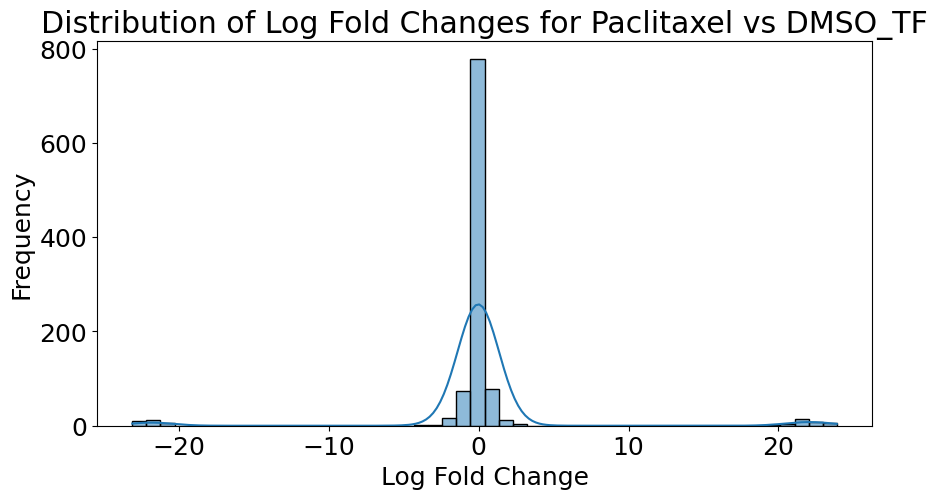

In [ ]:
# Get distribution of top DE genes for Paclitaxel vs DMSO_TF
result = sc.get.rank_genes_groups_df(dge_subset, group=selected_drug)

plt.figure(figsize=(10, 5))
sns.histplot(result['logfoldchanges'], bins=50, kde=True)
plt.title("Distribution of Log Fold Changes for Paclitaxel vs DMSO_TF")
plt.xlabel("Log Fold Change")
plt.ylabel("Frequency")
plt.show()

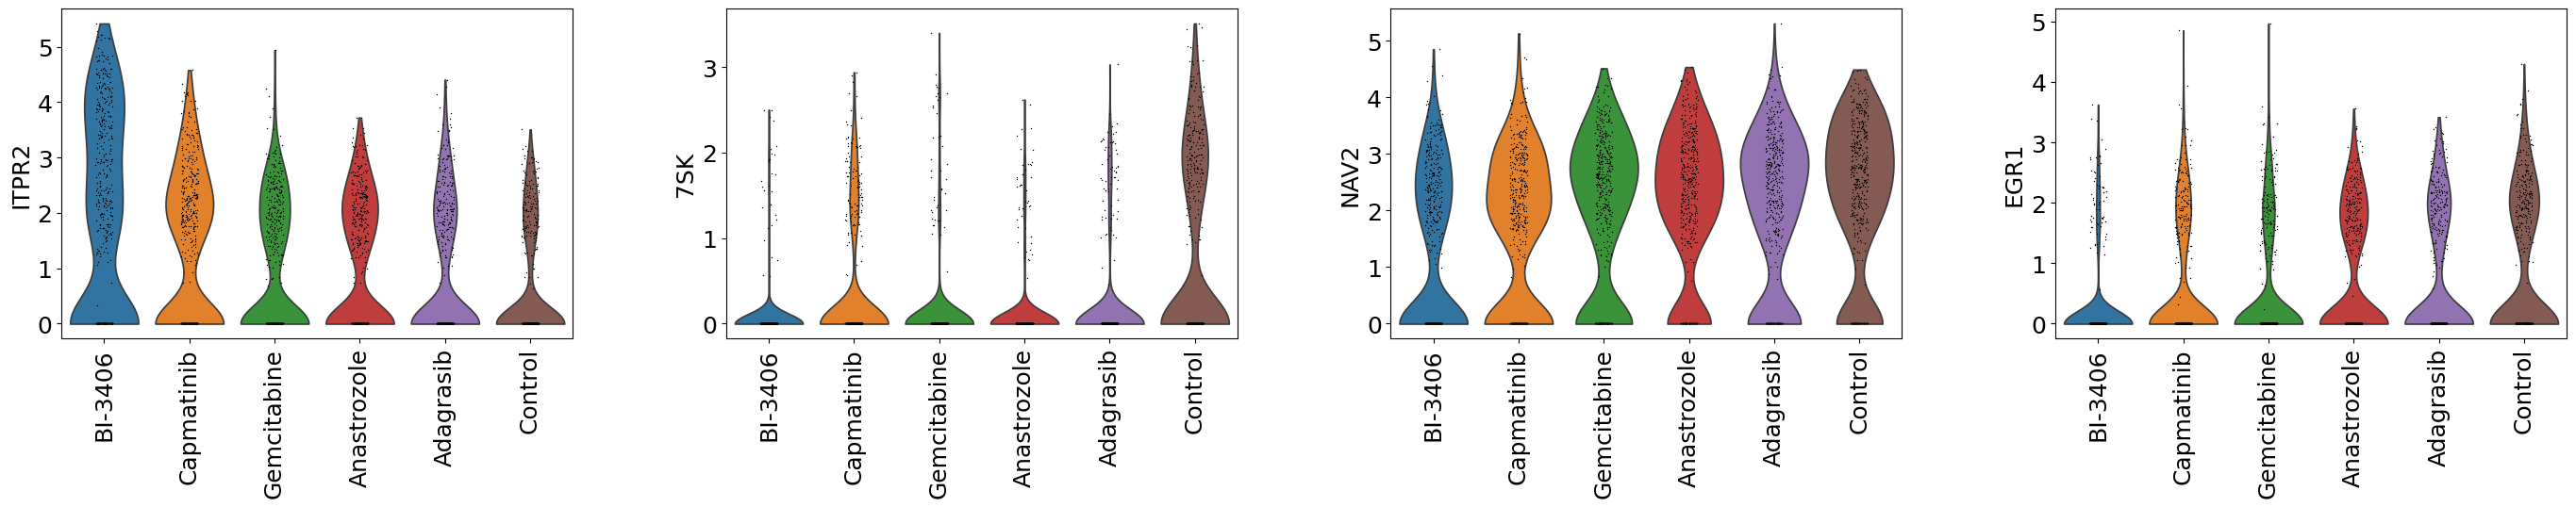

In [ ]:
# Violin Plots of top DE genes
top_genes = result.sort_values('pvals_adj').head(4)['names'].tolist()

# fig, axs = plt.subplots(figsize=(15, 10), nrows=2, ncols=2, sharey=True)

# Set title and font size for the violin plot
# plt.xlabel("Genes", fontsize=14)
# plt.ylabel("Expression Levels", fontsize=14)

violin_axs = sc.pl.violin(dge_subset, keys=top_genes, groupby='drug', rotation=90, order=selected_drugs + ["Control"], hue=colors, show=False, multi_panel=True)

# alt: Stack violin subplots horizontally
# axs = sc.pl.violin(dge_subset, keys=top_genes, groupby='drug', rotation=90, order=selected_drugs + ["Control"], hue=colors, show=False, multi_panel=True)

# for i, ax in enumerate(axs):
#     ax.set_title(f"Violin Plots of Top DE Genes for {selected_drug} vs Control", fontsize=16)
# plt.title(f"Violin Plots of Top DE Genes for {selected_drug} vs Control", fontsize=16)

# axs[0, 0] = violin_axs[0]
# axs[0, 1] = violin_axs[1]
# axs[1, 0] = violin_axs[2]
# axs[1, 1] = violin_axs[3]


# fig = plt.gcf()

# # 3. Set the overarching title
# fig.suptitle(f"Violin Plots of Top DE Genes for 5 drugs vs Control", fontsize=28, x=0.44)  # Adjust y for spacing

# # 4. Optional: Adjust spacing so the super title doesn't overlap the subplots
# fig.tight_layout()

# # 5. Finally, display or save the plot
# plt.show()

/system/apps/studentenv/mkindler/cellpert/lib/python3.11/site-packages/scanpy/plotting/_anndata.py:961: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/system/apps/studentenv/mkindler/cellpert/lib/python3.11/site-packages/scanpy/plotting/_anndata.py:961: UserWarning: The palette list has more values (7) than needed (6), which may not be intended.
  sns.violinplot(
/system/apps/studentenv/mkindler/cellpert/lib/python3.11/site-packages/scanpy/plotting/_anndata.py:961: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
/system/apps/studentenv/mkindler/cellpert/lib/python3.11/site-packages/scanpy/plotting/_anndata.py:961: UserWarning: The palette list has more values (7) than needed (6), whi

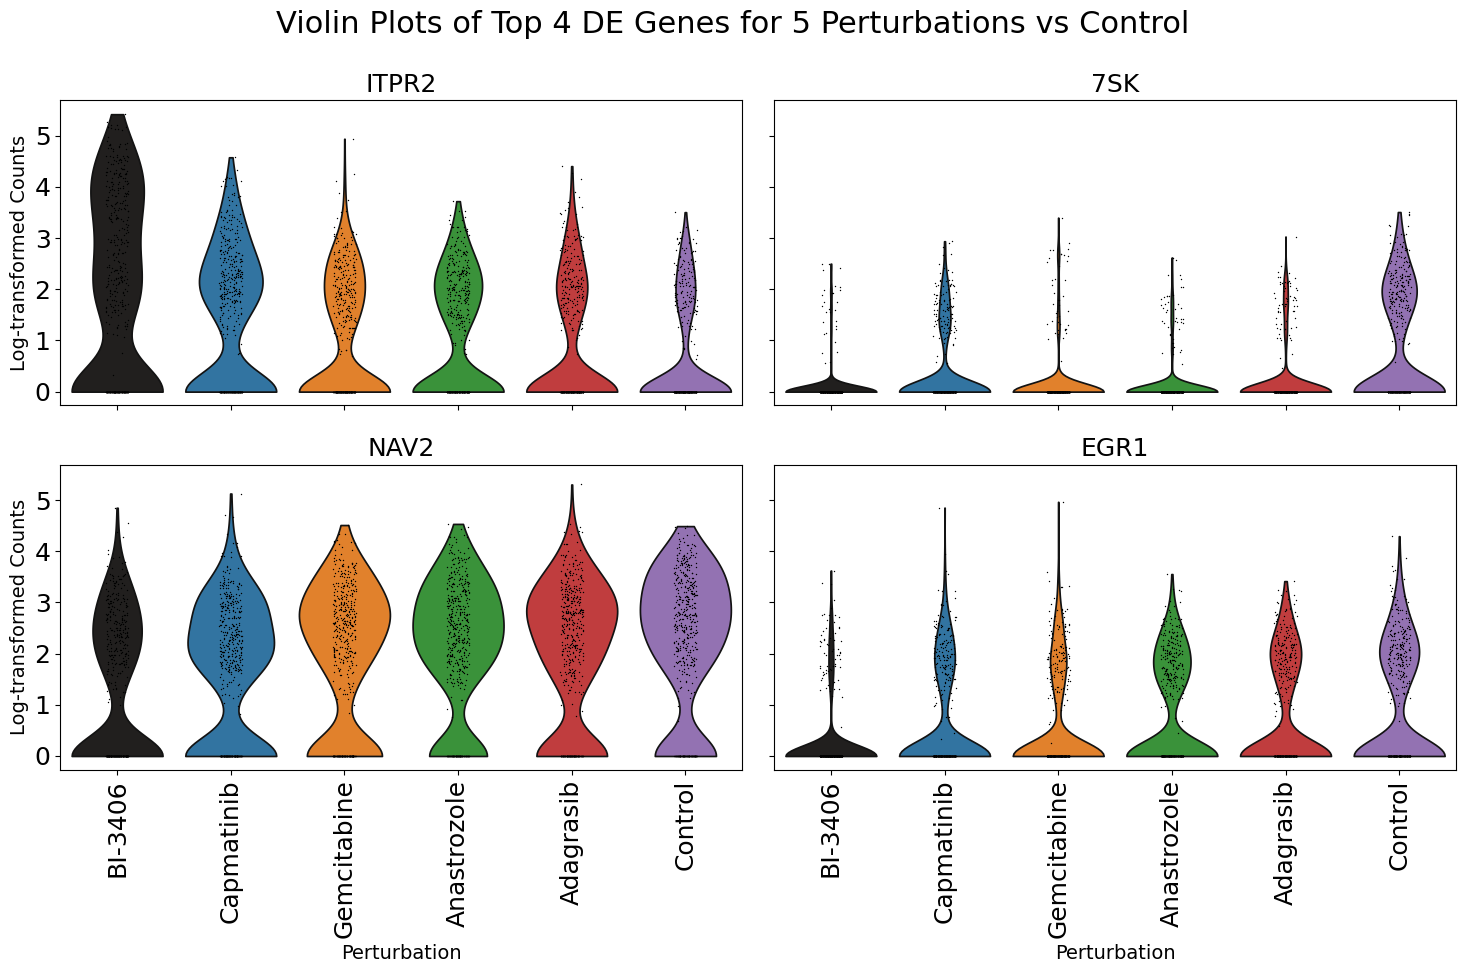

In [ ]:
import matplotlib.pyplot as plt
import scanpy as sc

# 1. Grab your top 4 genes
top_genes = result.sort_values('pvals_adj').head(4)['names'].tolist()

# 2. Initialize a 2x2 grid using Matplotlib
fig, axs = plt.subplots(figsize=(15, 10), nrows=2, ncols=2, sharey=True, sharex=True)

# 3. Flatten the 2D axes matrix (2x2) into a 1D array (length 4) for simple looping
axs_flat = axs.flatten()

# 4. Draw each gene into its corresponding axis block
for i, gene in enumerate(top_genes):
    sc.pl.violin(
        dge_subset, 
        keys=gene,                          # Plot exactly one gene per iteration
        groupby='drug', 
        rotation=90, 
        order=selected_drugs + ["Control"], 
        palette=colors,                     # Use 'palette' for color styling in Scanpy
        ax=axs_flat[i],                     # Enforce the specific 2x2 quadrant position
        show=False                          # Prevent resetting the canvas canvas
    )
    # Set titles for individual quadrants
    axs_flat[i].set_title(gene, fontsize=18)
    axs_flat[i].set_ylabel("Log-transformed Counts", fontsize=14)
    axs_flat[i].set_xlabel("Perturbation", fontsize=14)

# 5. Apply the overall layout modifications
fig.suptitle(f"Violin Plots of Top 4 DE Genes for 5 Perturbations vs Control", fontsize=22, y=0.98)
plt.tight_layout()

# 6. Save or display the clean 2x2 matrix
plt.savefig("top_genes_2x2_violin.png", dpi=300, bbox_inches="tight")
plt.show()


# Mean & Variance Visualization and Pearson Correlation

In [ ]:
control_mean = np.mean(adata[adata.obs['drug'] == 'DMSO_TF'].X.toarray(), axis=0)

def mean_pearson_correlation_and_plot(drugs):
    # means = {}
    for drug in drugs:
        mask = adata.obs["drug"] == drug
        adata_pert = adata[mask]
        adata_array = adata_pert.X.toarray()
        mean = np.mean(adata_array, axis=0)

        corr, _ = pearsonr(mean, control_mean)
        print(f"Pearson correlation between {drug} and control: {corr:.4f}")

        plt.figure(figsize=(20, 10))
        plt.plot(mean, label=drug, alpha=0.5)
        plt.plot(control_mean, label="DMSO_TF", alpha=0.5)
        plt.title(f"Mean expression for {drug}")
        plt.xlabel("Gene index")
        plt.ylabel("Mean expression")
        plt.ylim(0, 7)
        plt.legend()
        plt.show()
    
    # Calculate Pearson correlation between the mean expression profiles of the drugs
    # for drug in drugs:
    #     corr, _ = pearsonr(means[drug], control_mean)
    #     print(f"Pearson correlation between {drug} and control: {corr:.4f}")

Pearson correlation between Vemurafenib and control: 0.9940


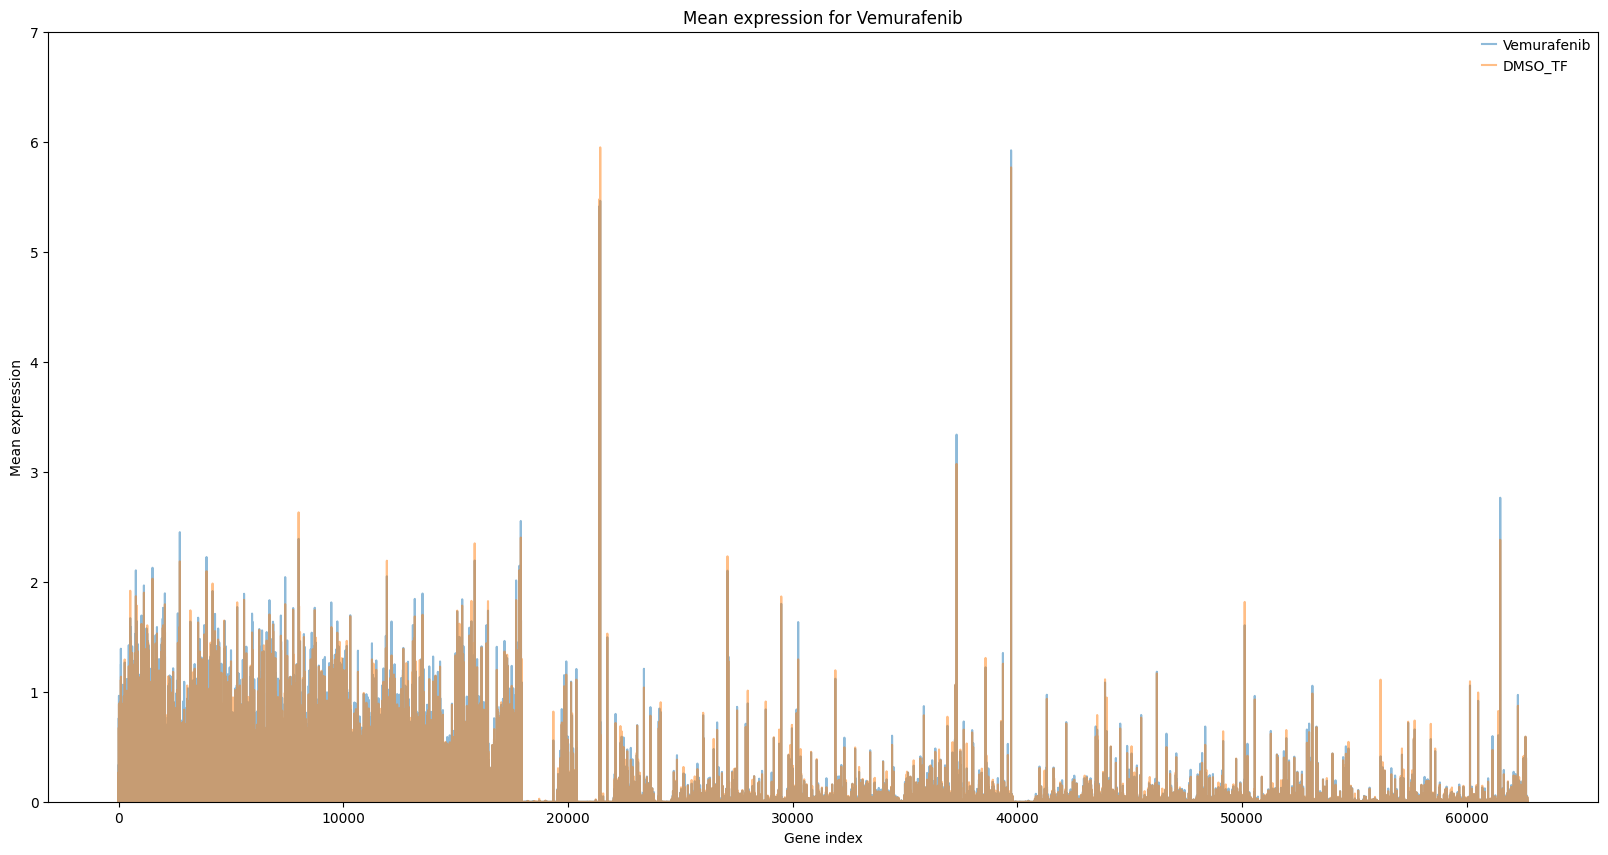

Pearson correlation between Anastrozole and control: 0.9942


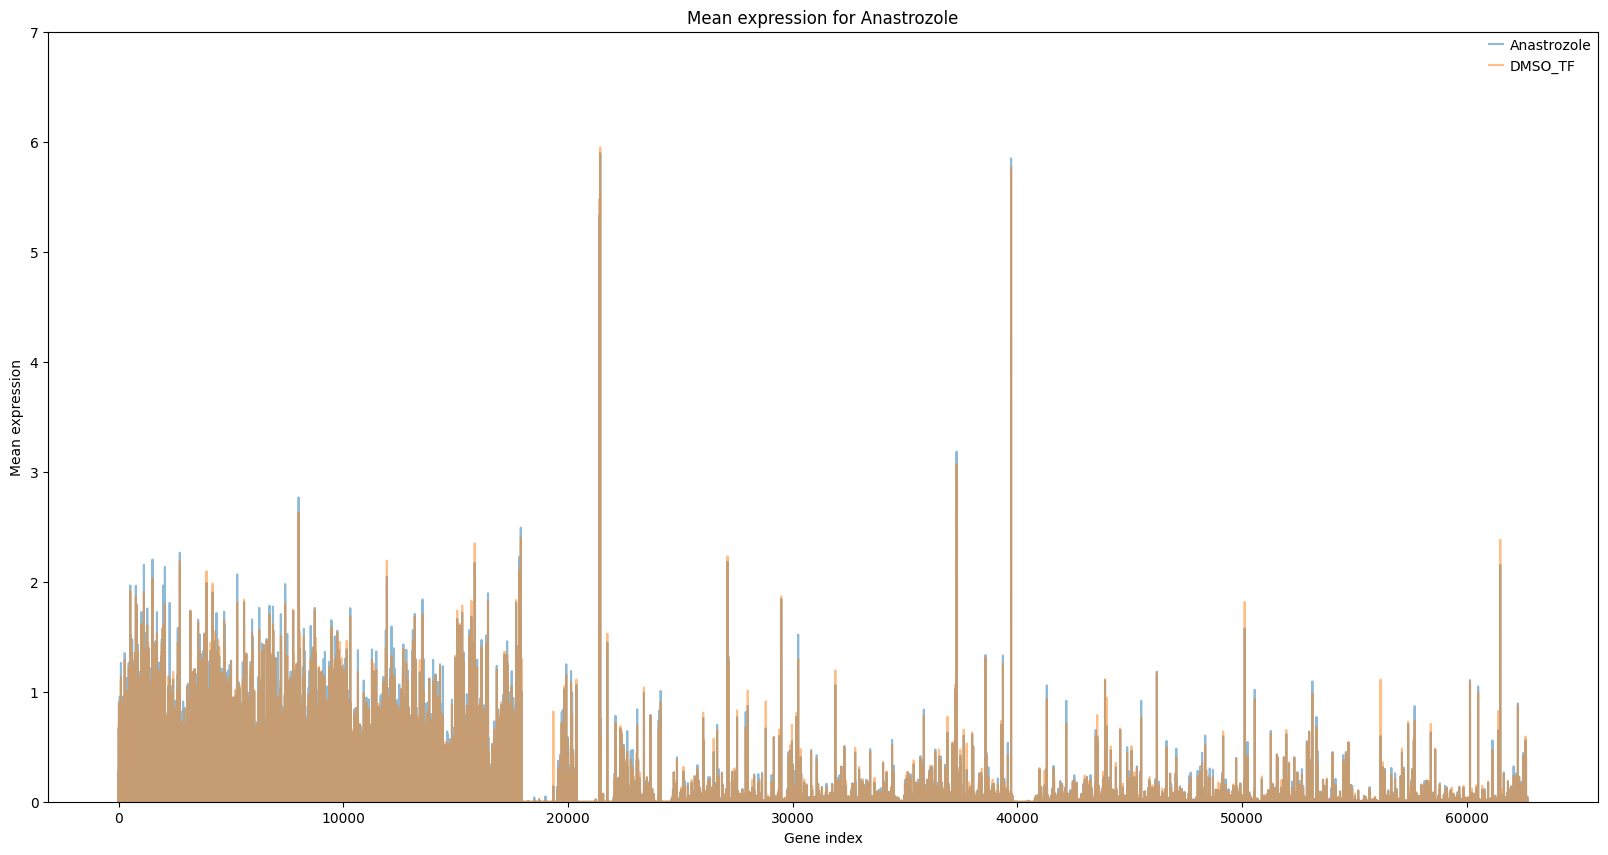

Pearson correlation between Everolimus and control: 0.9946


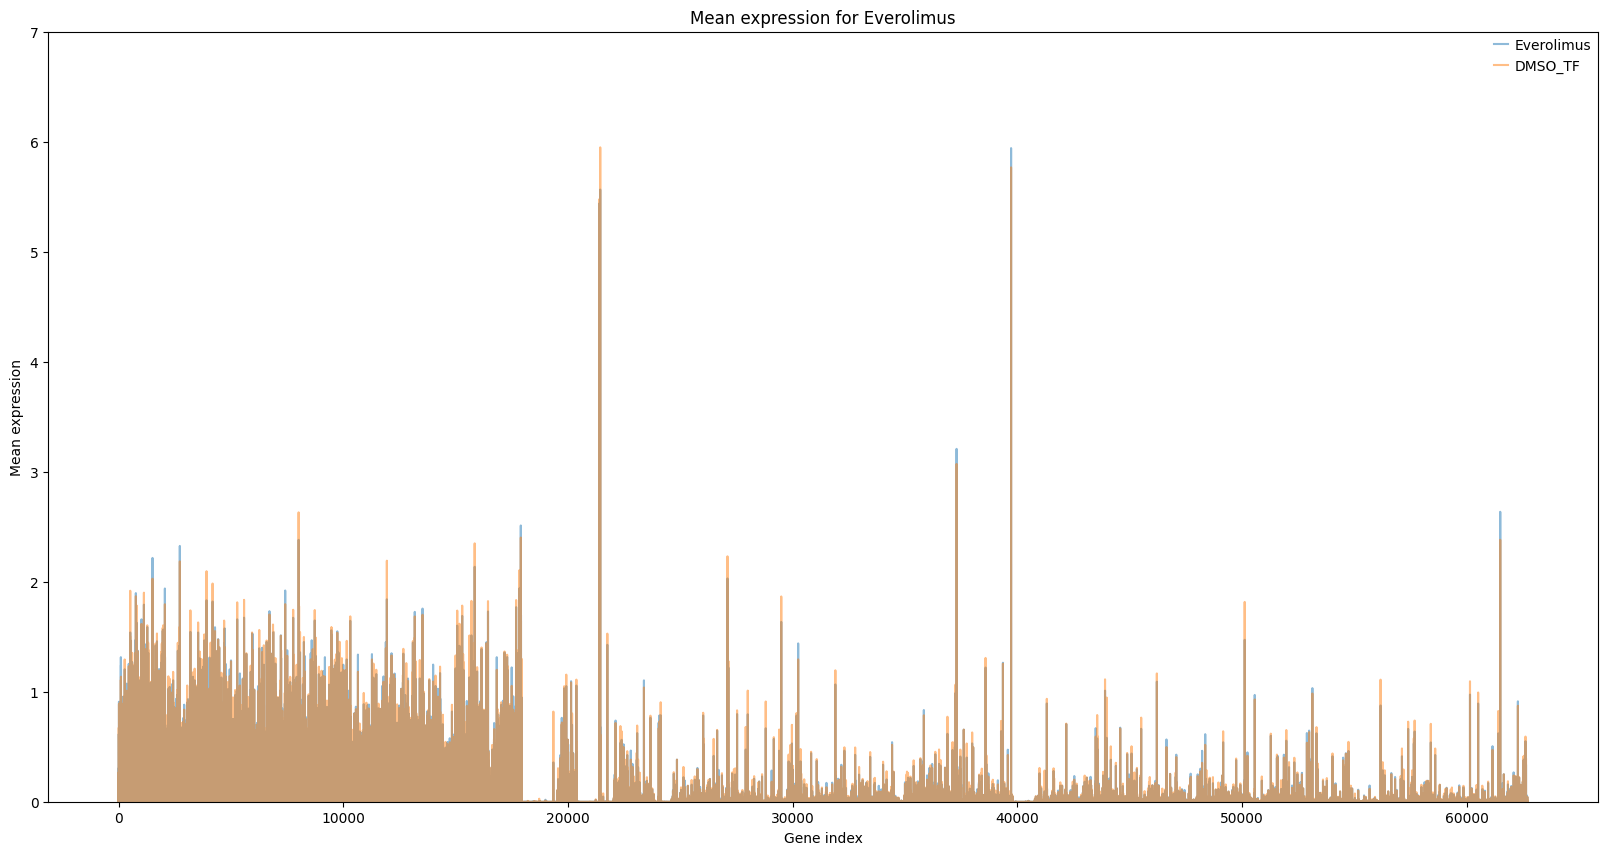

Pearson correlation between Gemcitabine and control: 0.9911


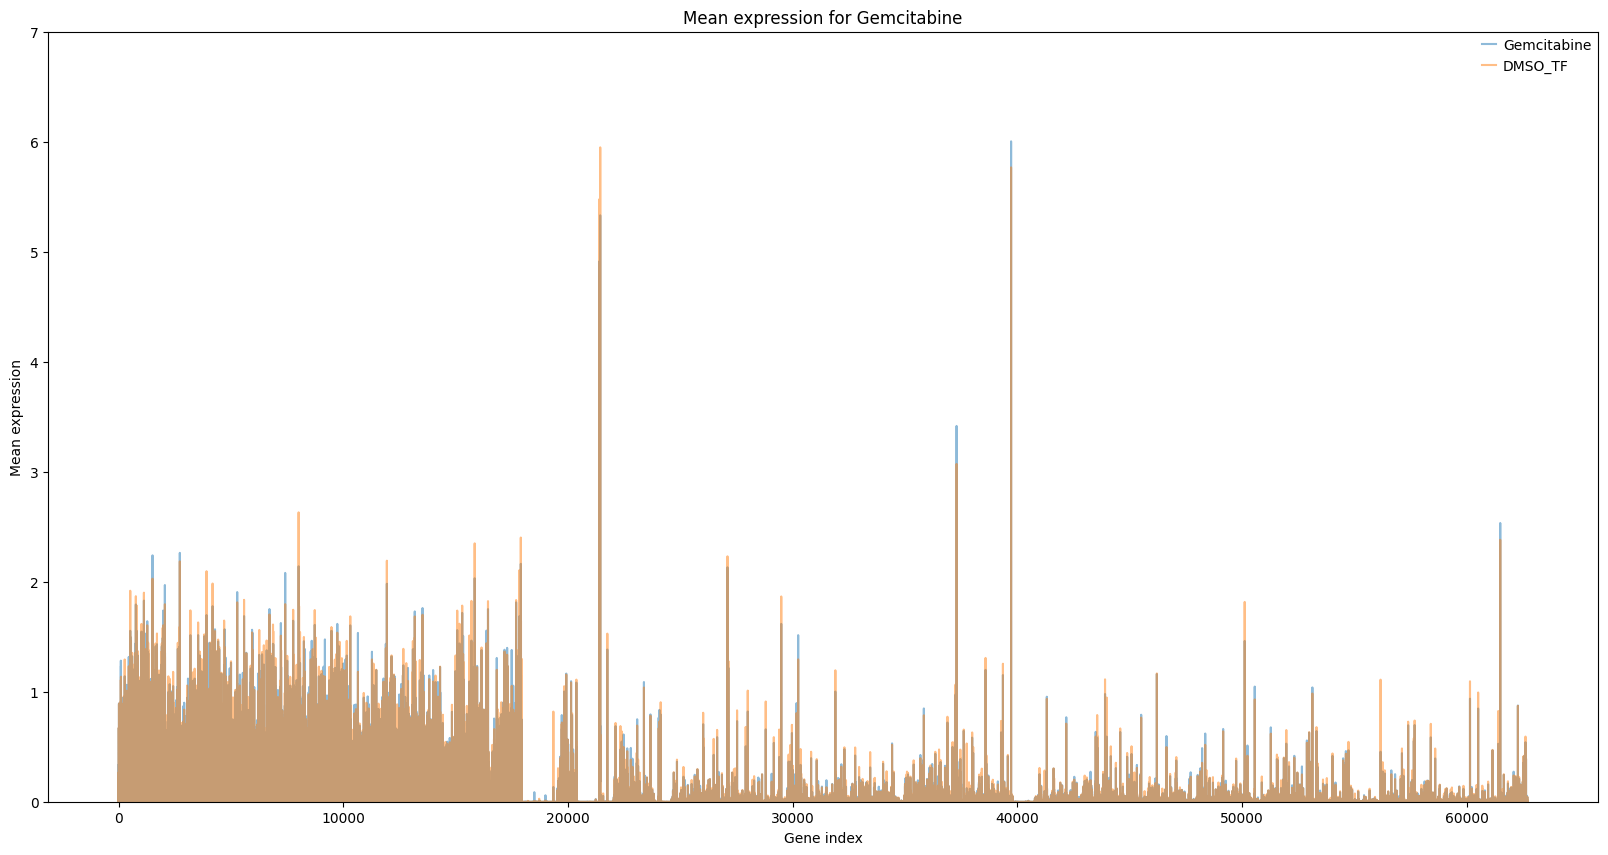

Pearson correlation between Lonafarnib and control: 0.9911


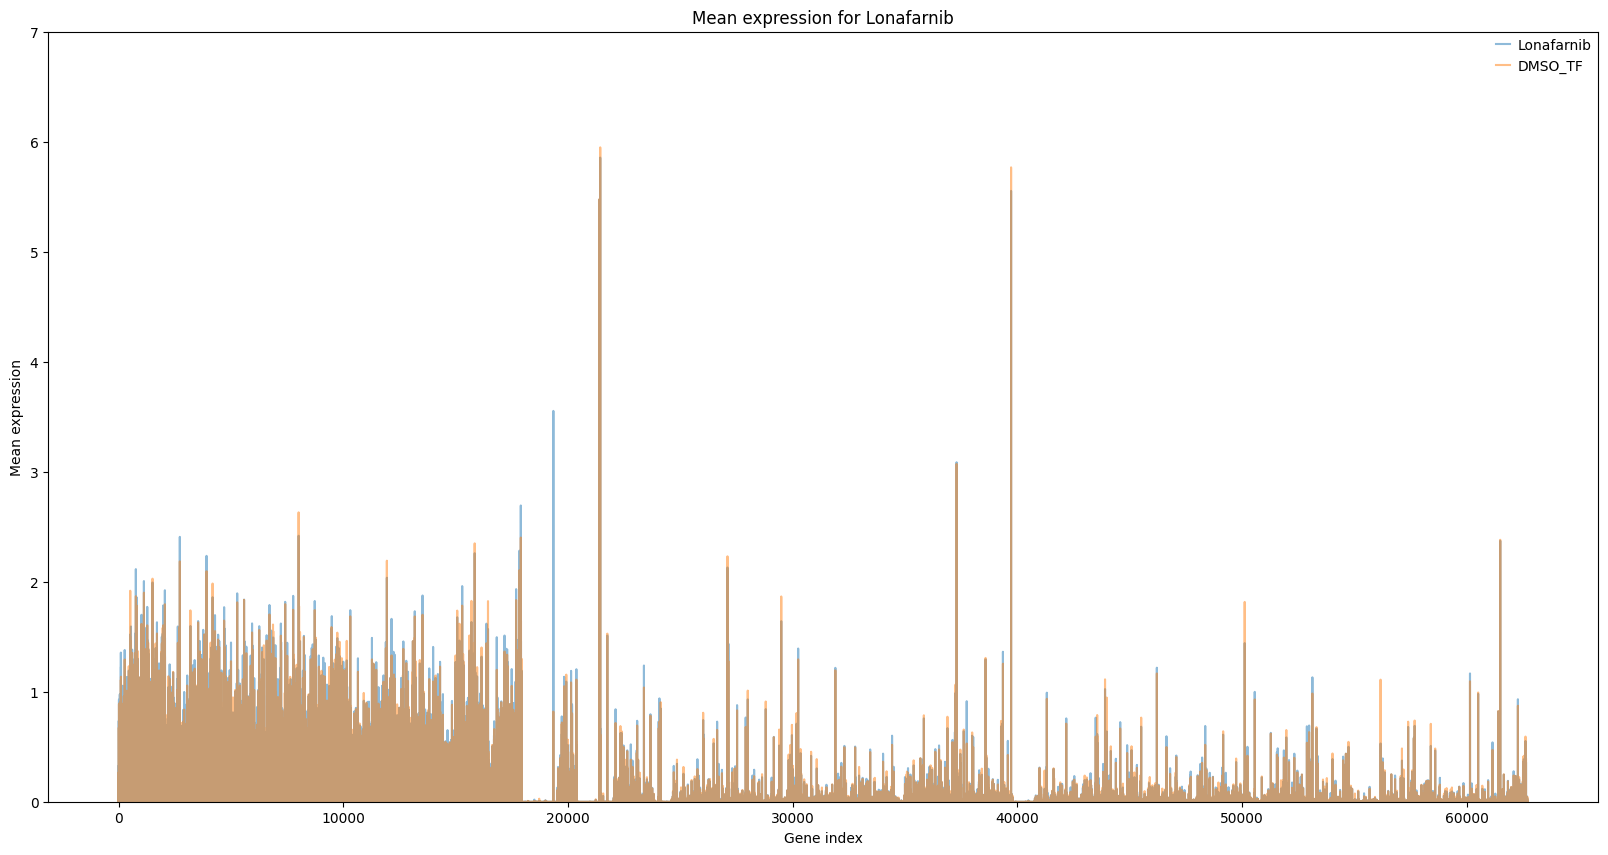

Pearson correlation between Paclitaxel and control: 0.9904


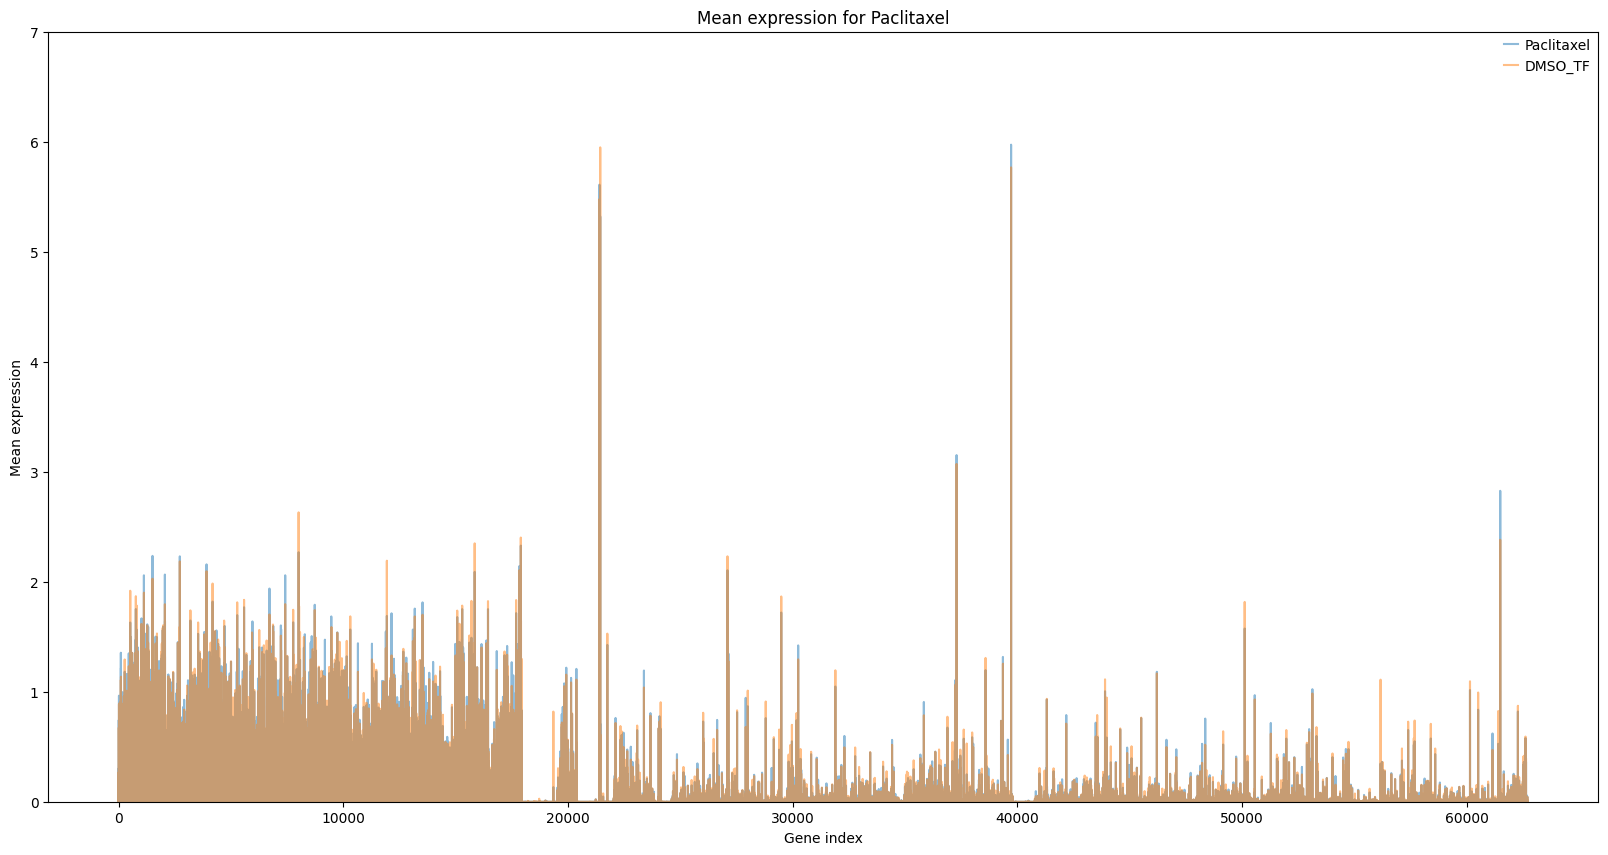

Pearson correlation between Minodronic acid and control: 0.9924


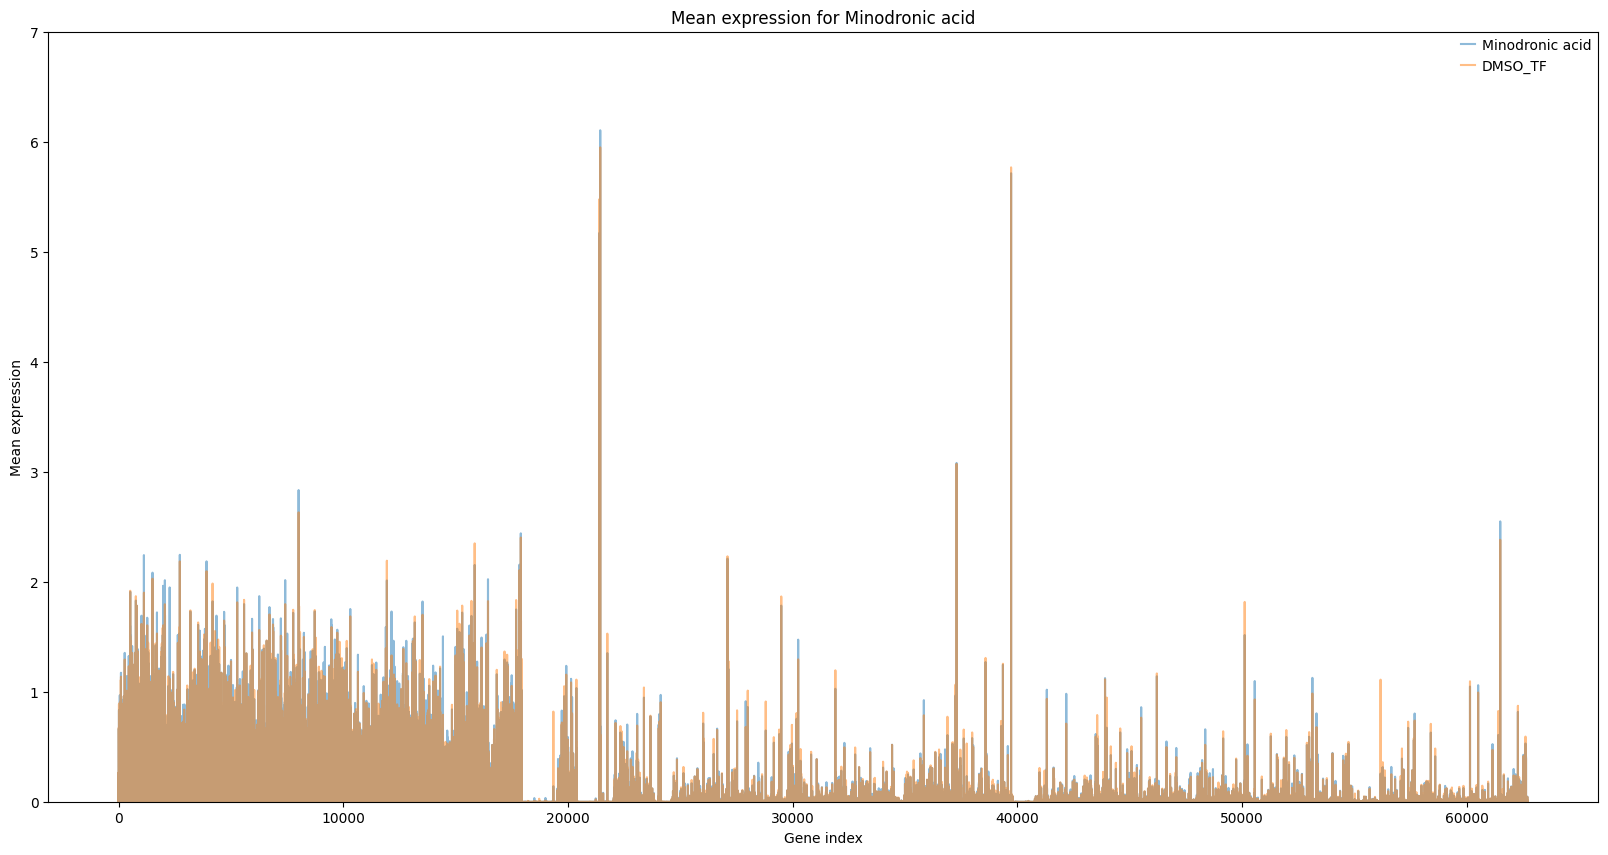

Pearson correlation between Tubulin inhibitor 6 and control: 0.9944


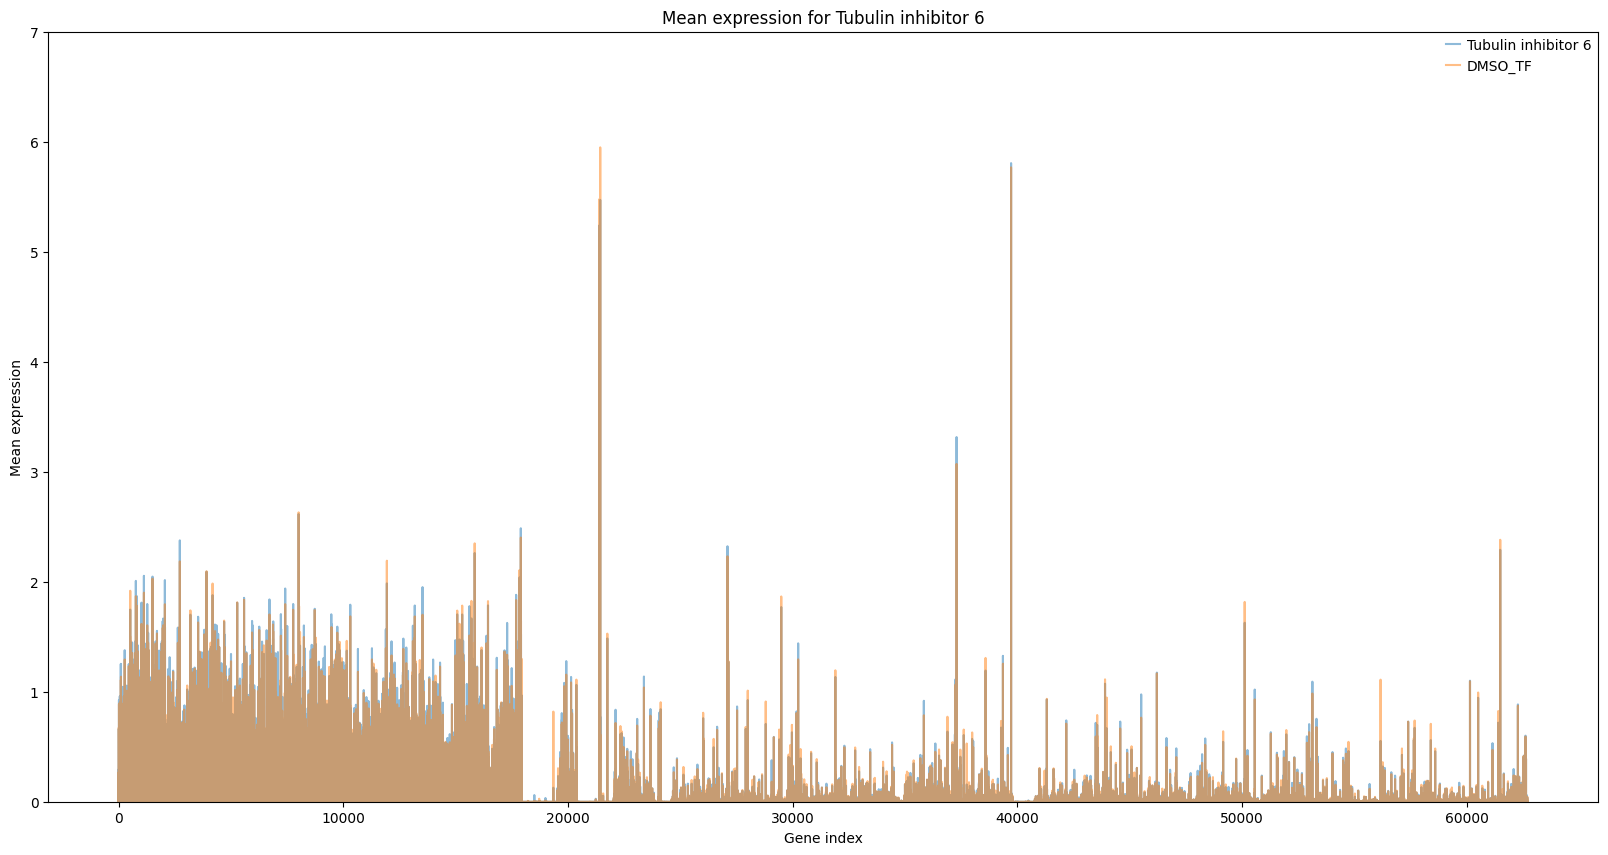

Pearson correlation between Oxaliplatin and control: 0.9907


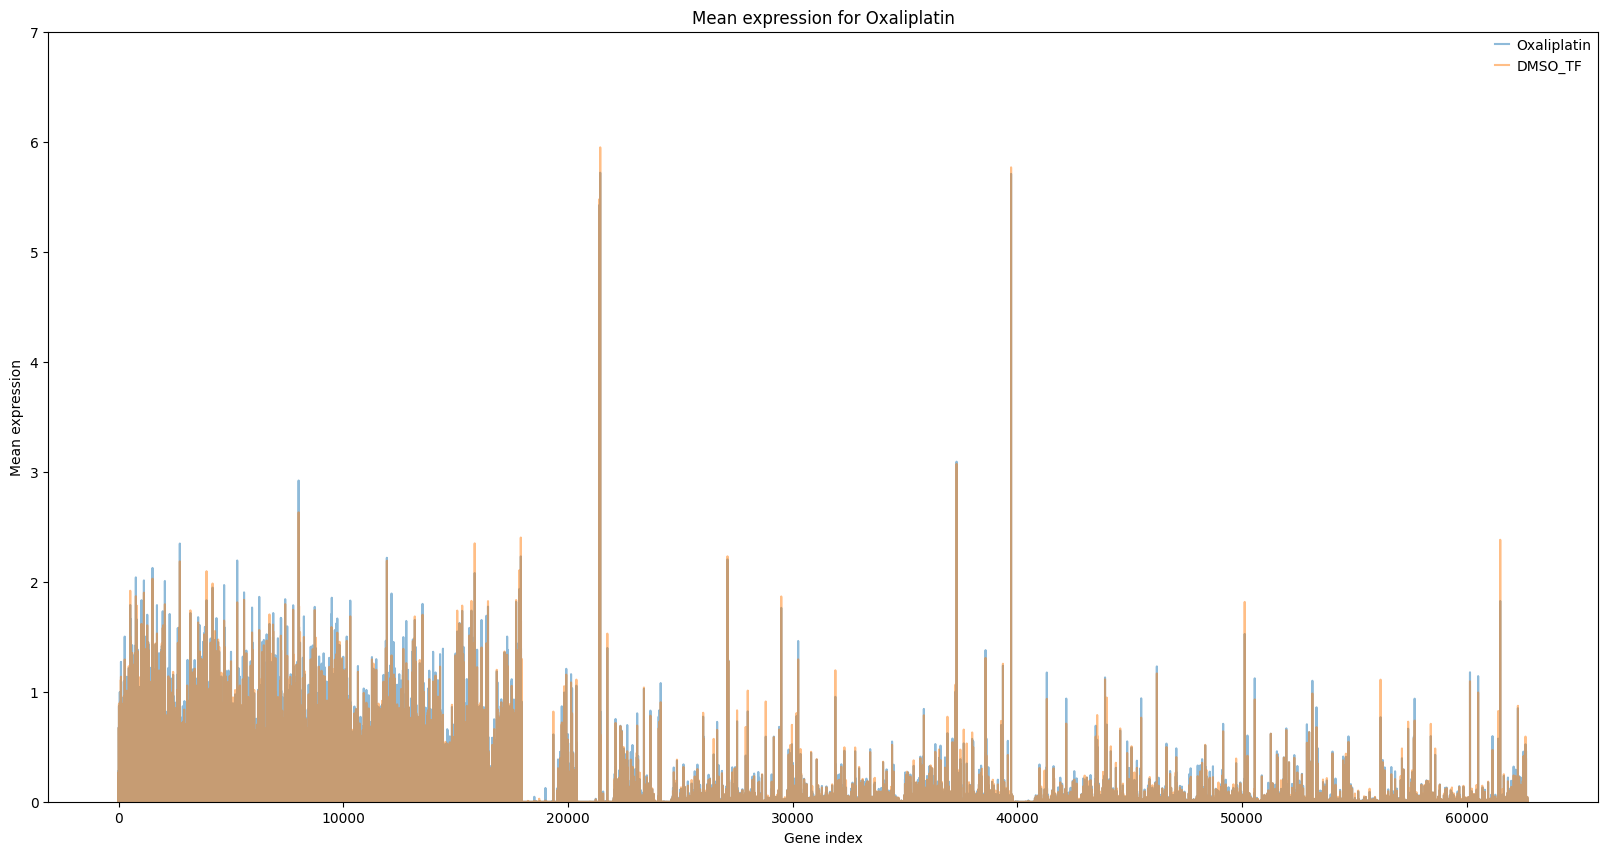

Pearson correlation between Adagrasib and control: 0.9966


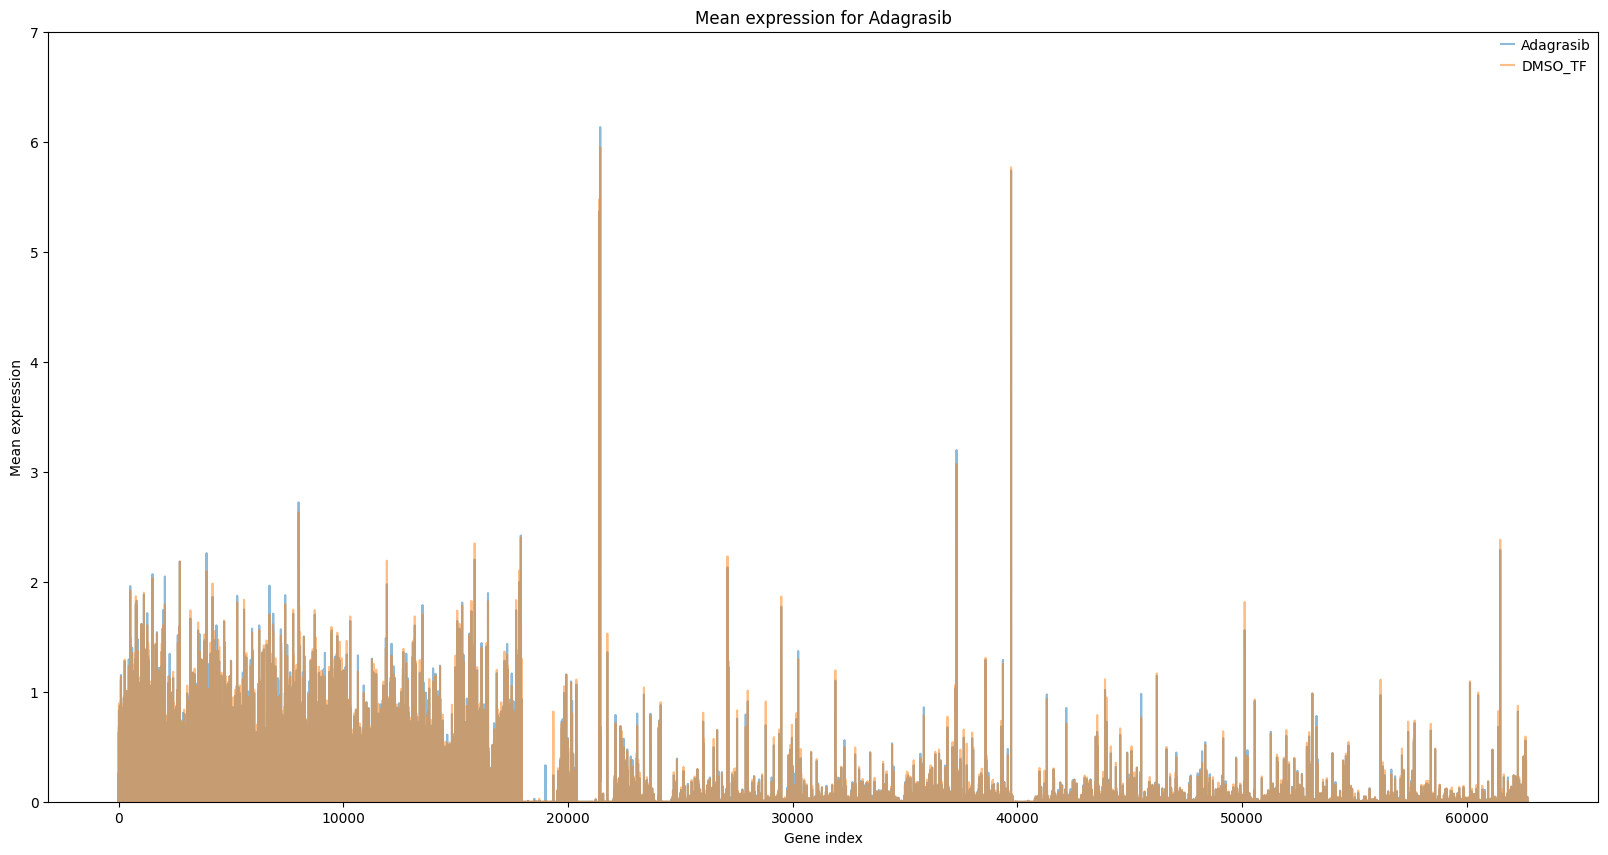

Pearson correlation between RMC-6236 and control: 0.9853


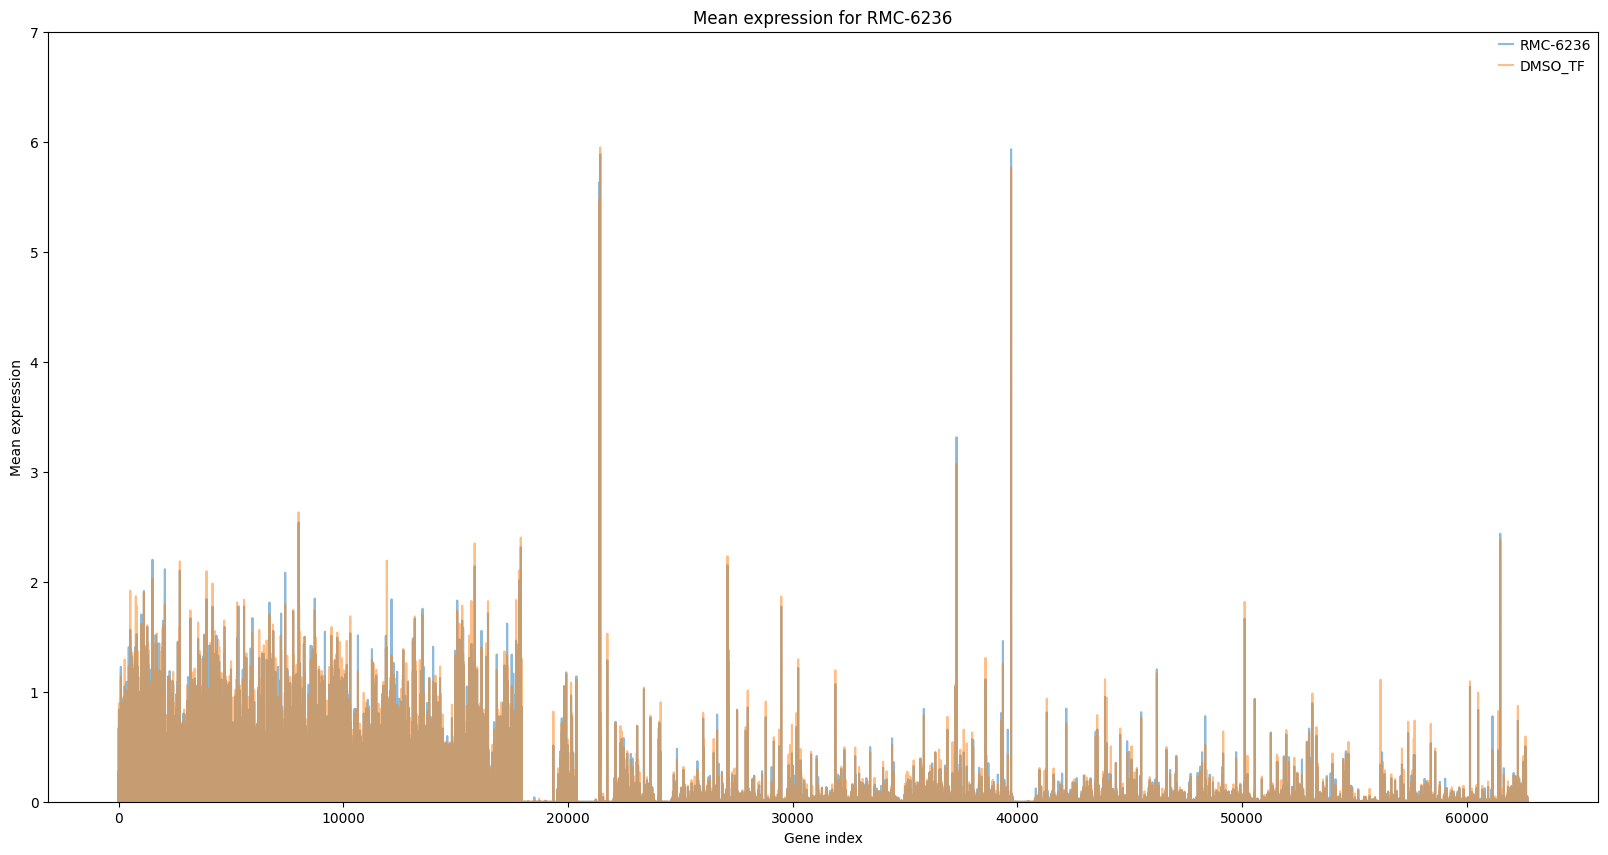

Pearson correlation between olaparib and control: 0.9946


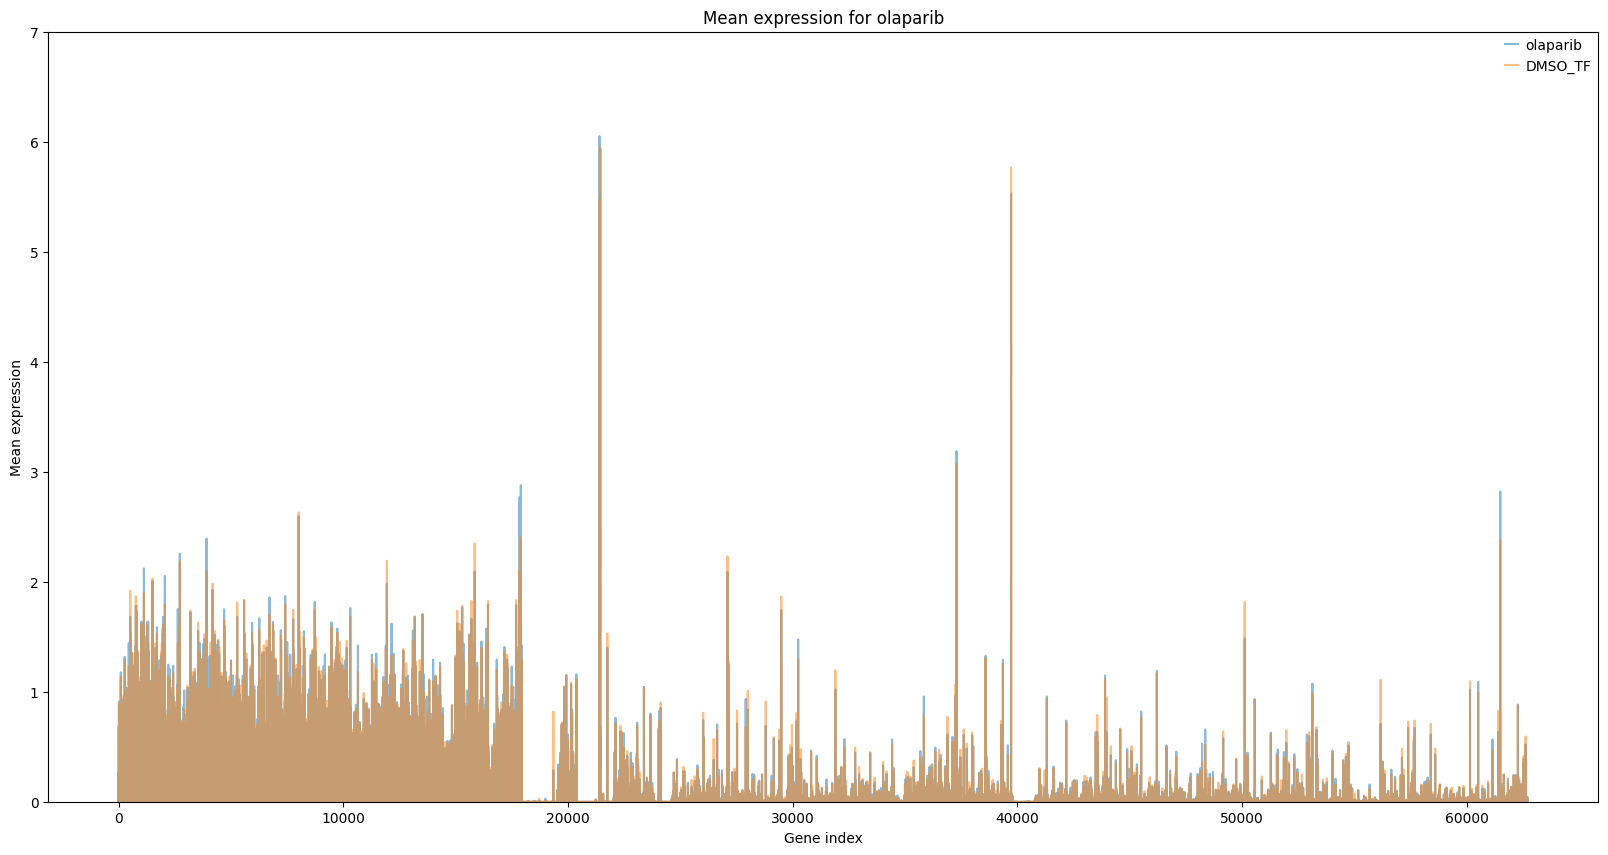

Pearson correlation between 4EGI-1 and control: 0.9935


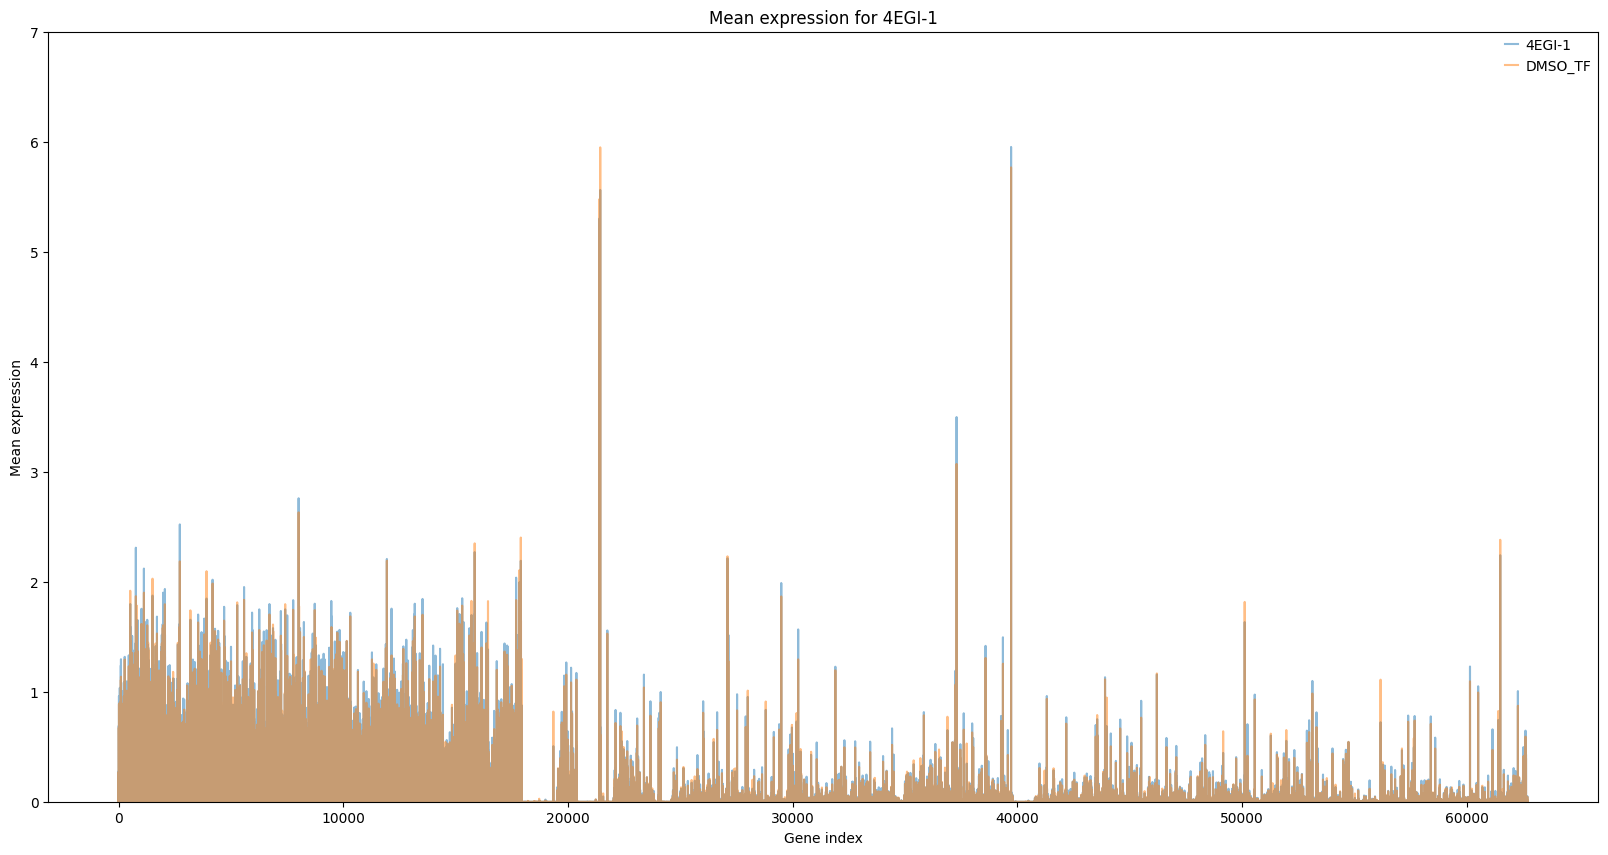

Pearson correlation between Regorafenib and control: 0.9936


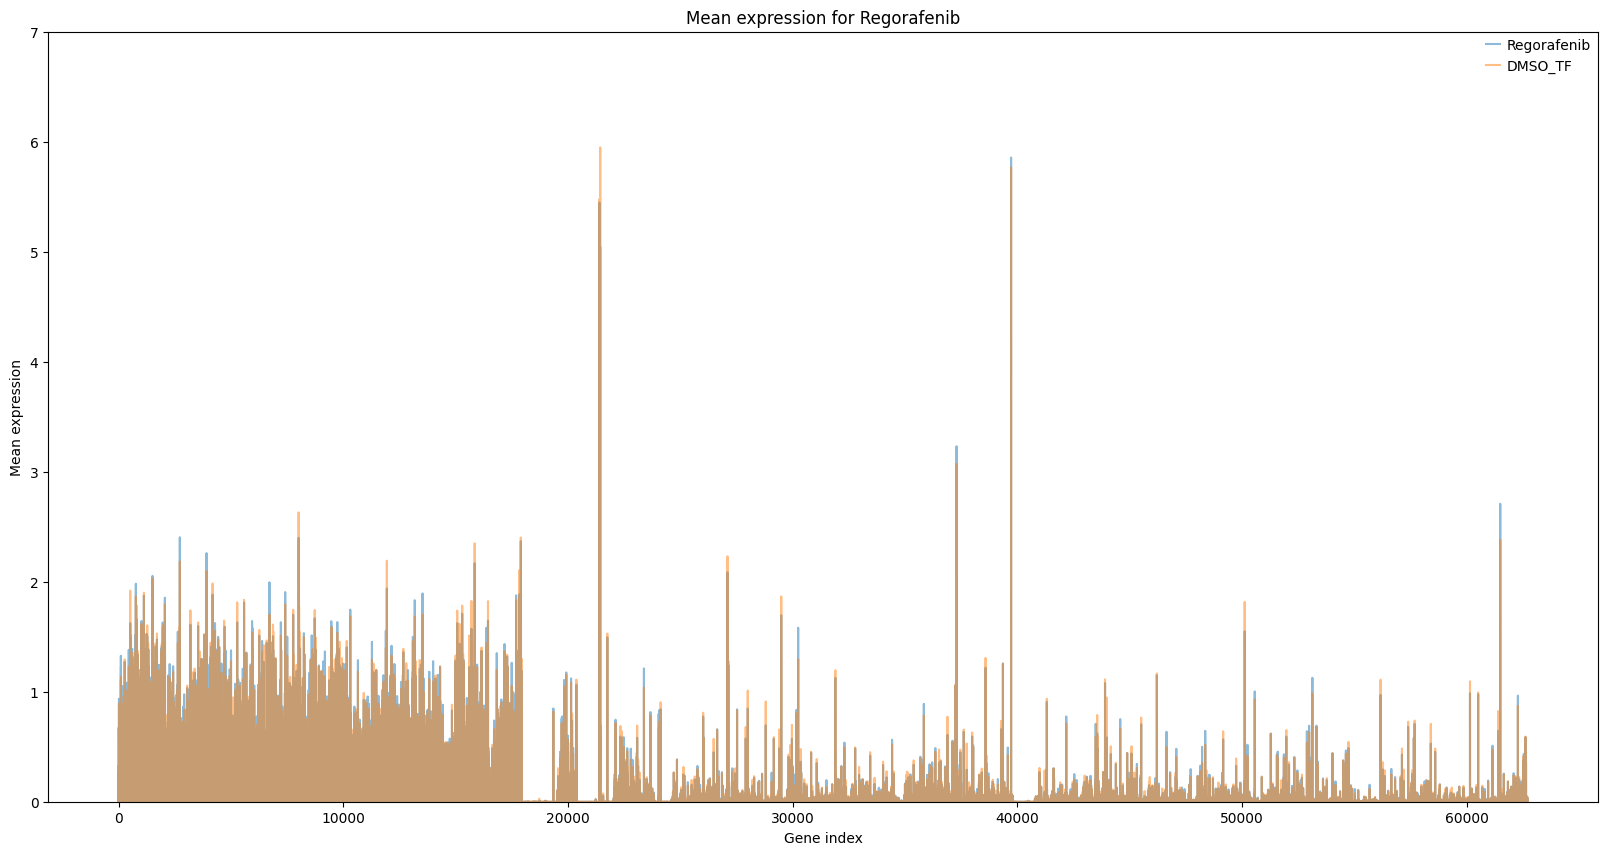

Pearson correlation between BI-3406 and control: 0.9804


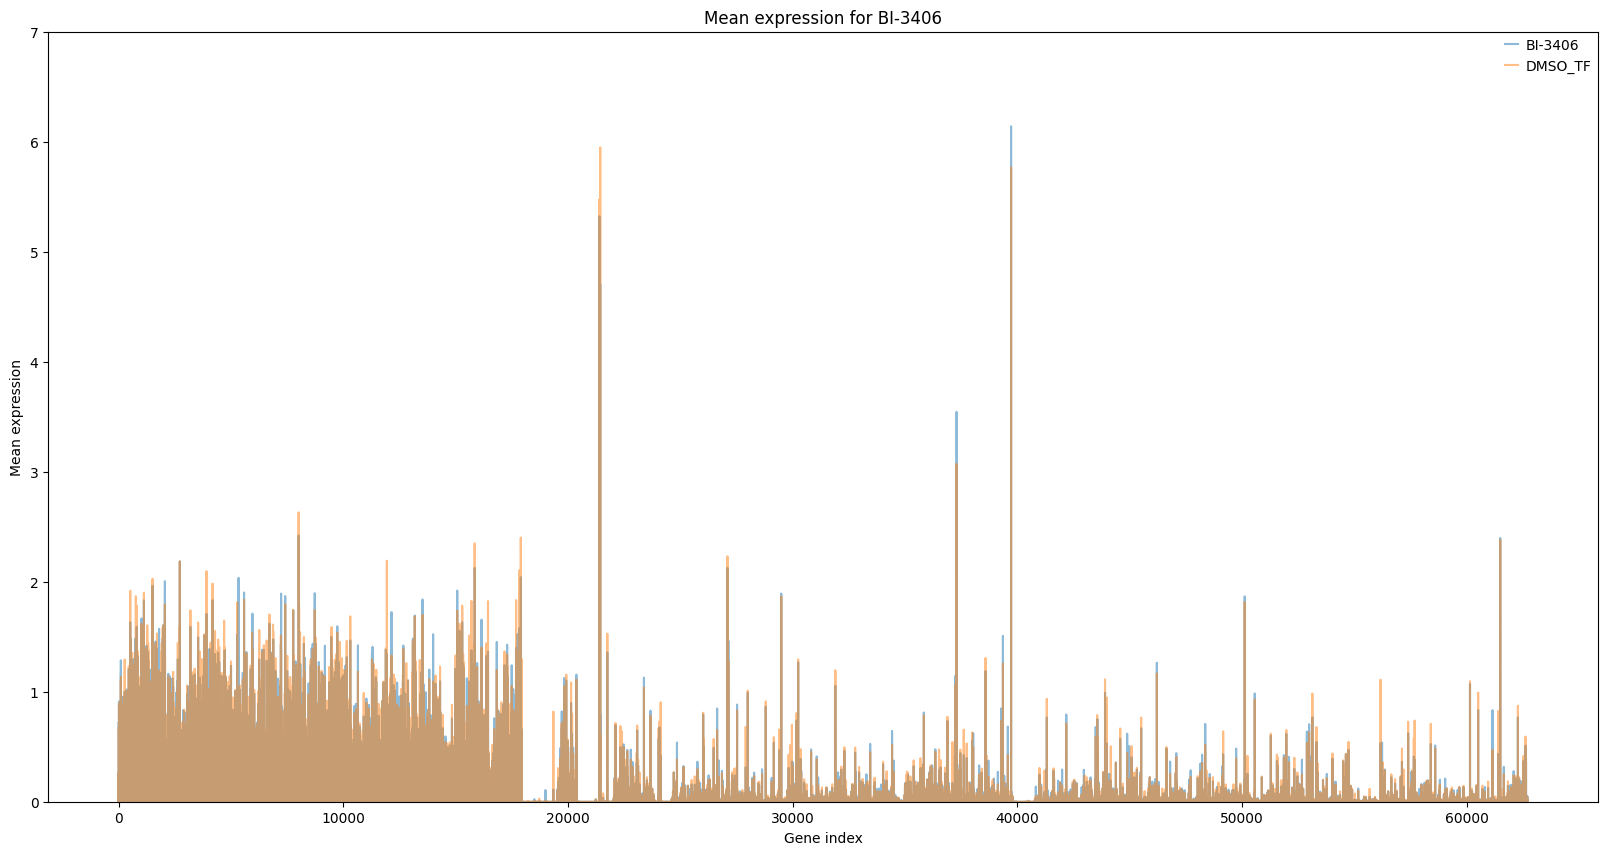

Pearson correlation between venetoclax and control: 0.9884


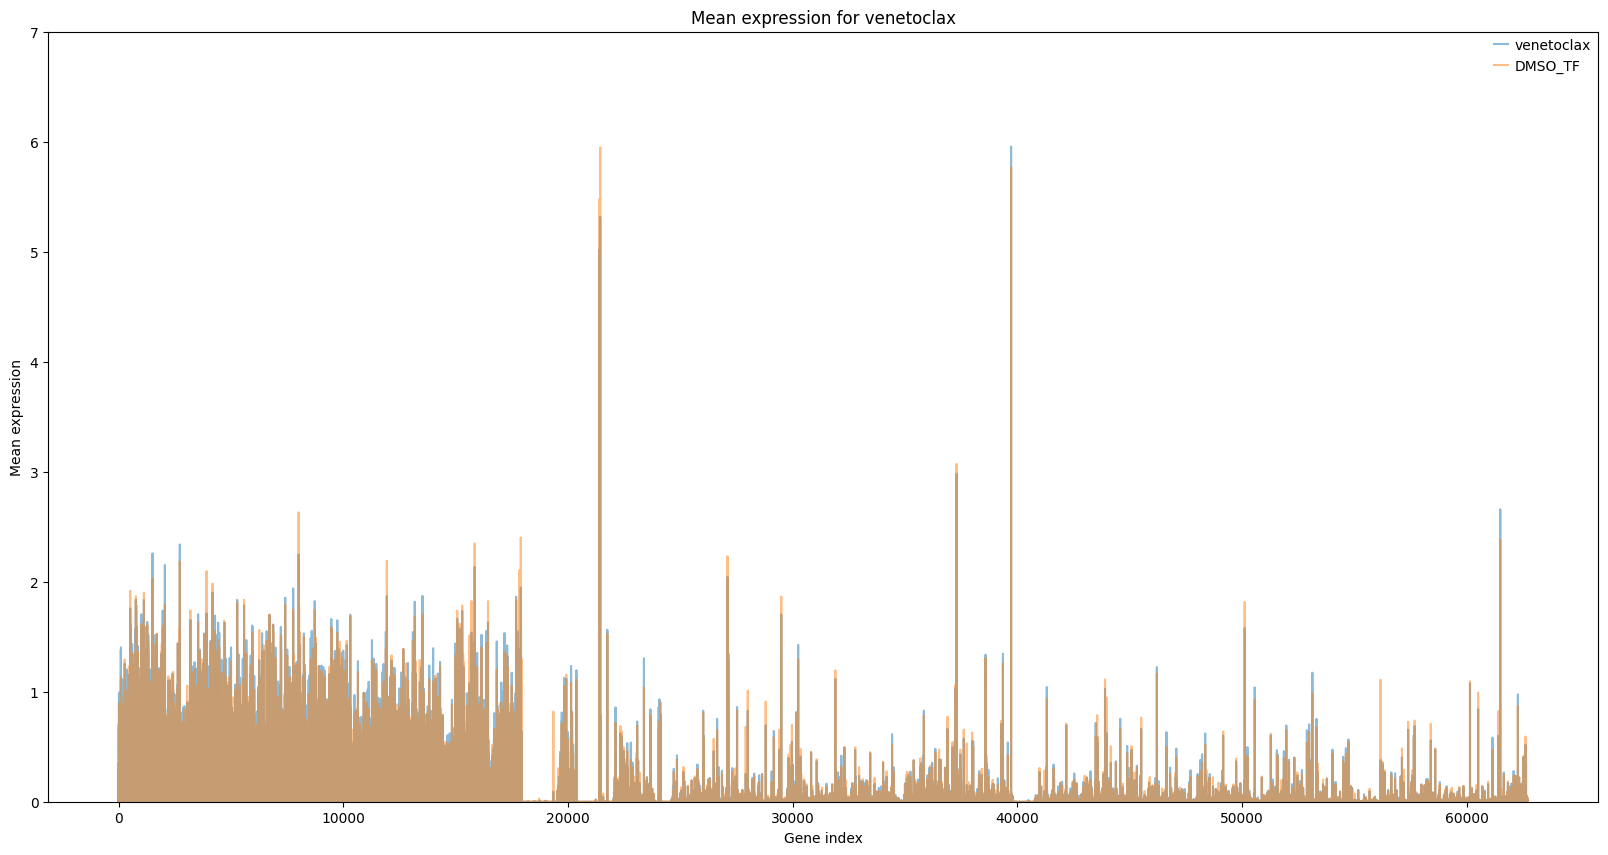

Pearson correlation between DT-061 and control: 0.9938


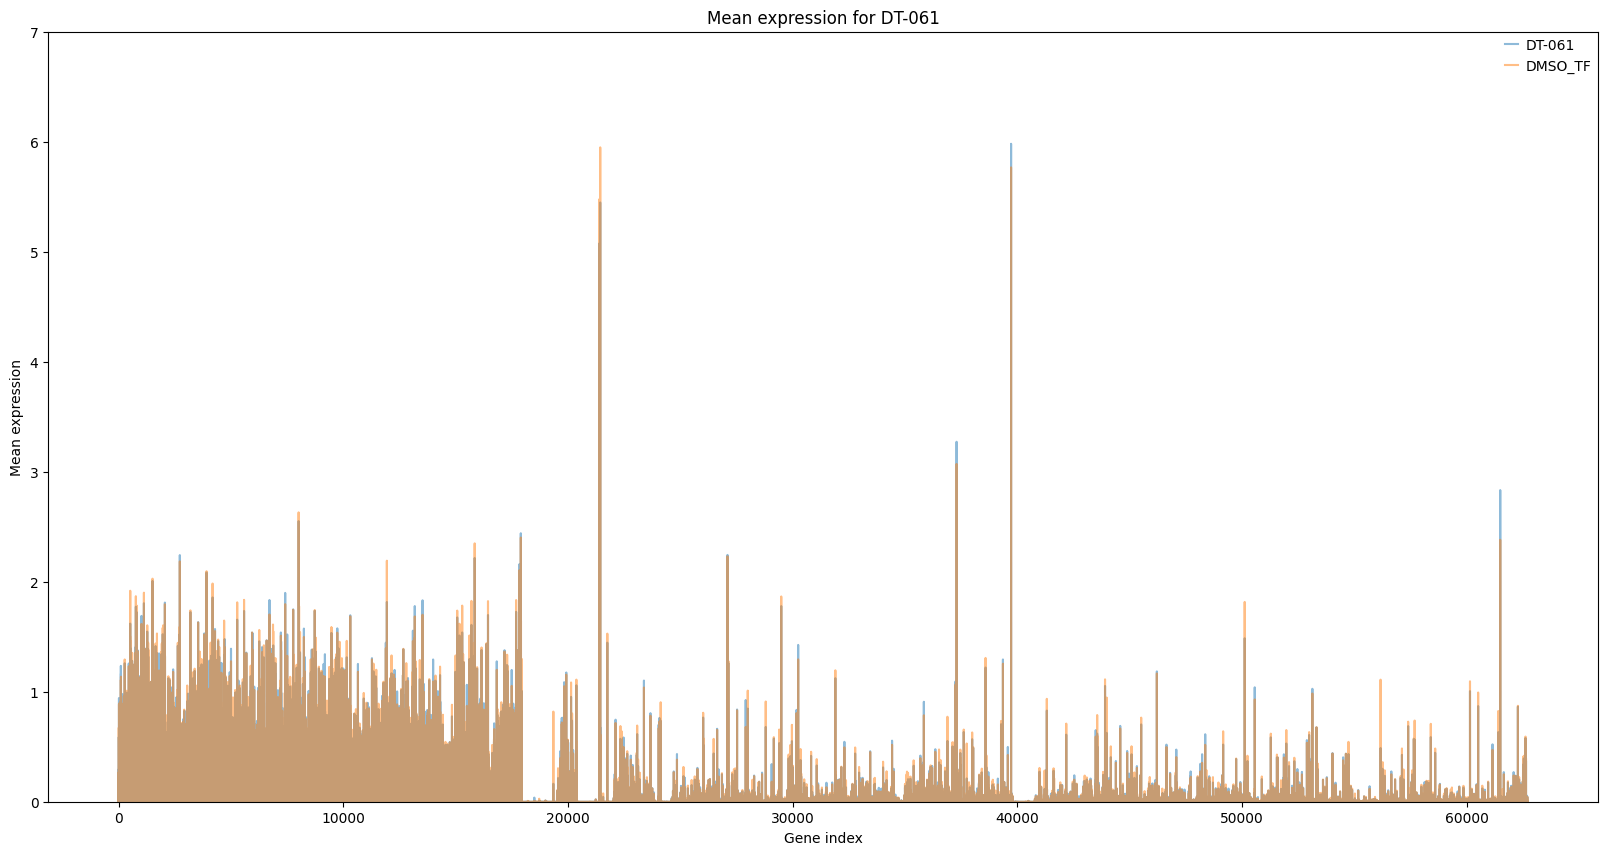

Pearson correlation between ETC-206 and control: 0.9914


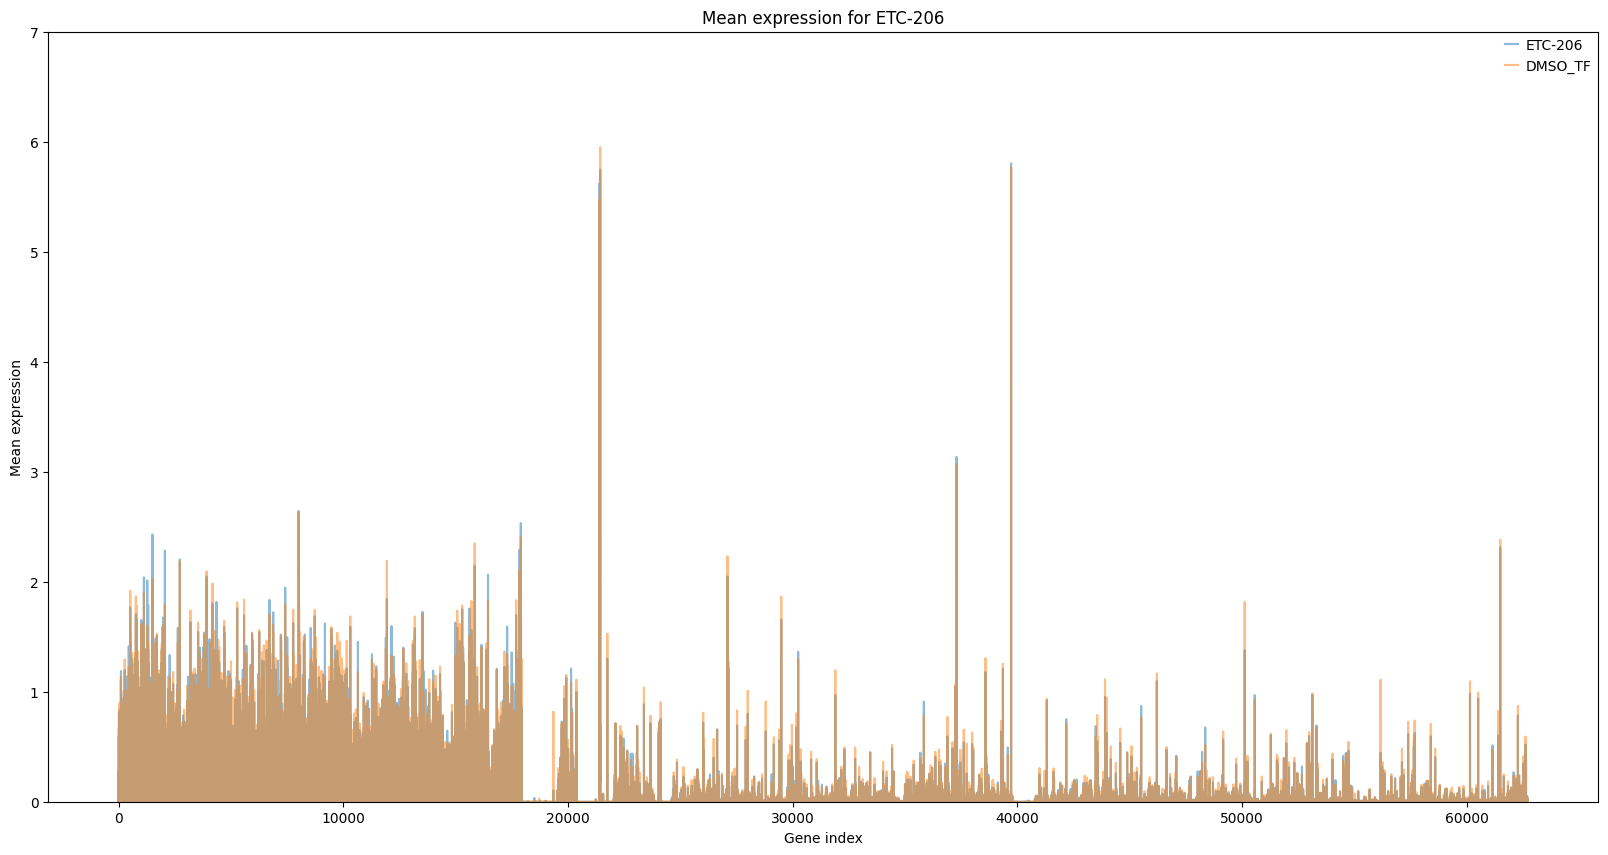

Pearson correlation between DTP3 and control: 0.9932


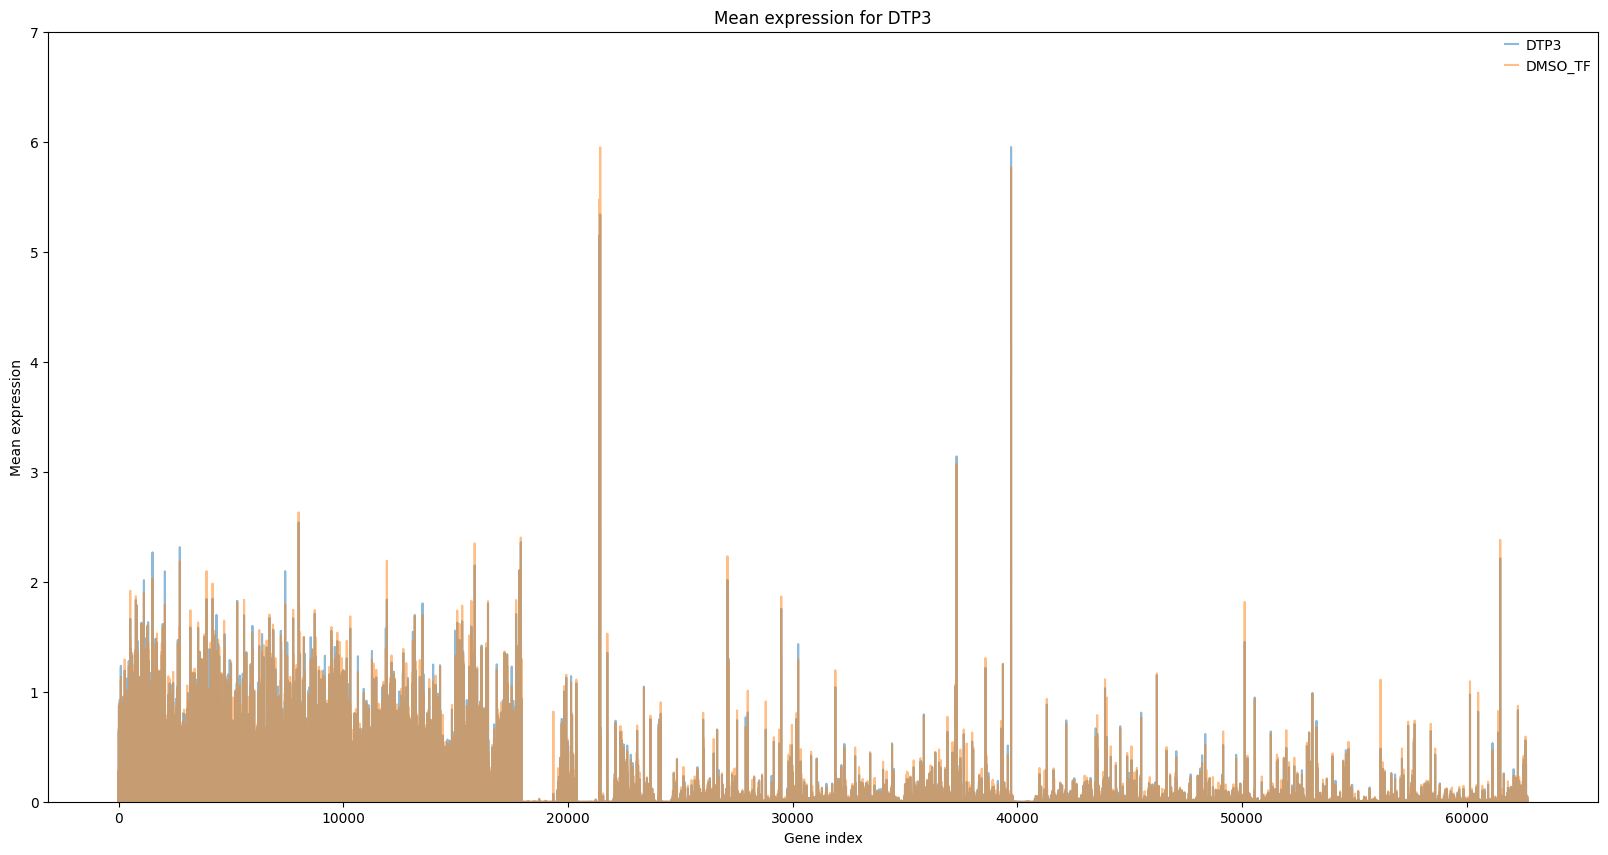

Pearson correlation between Afatinib and control: 0.9939


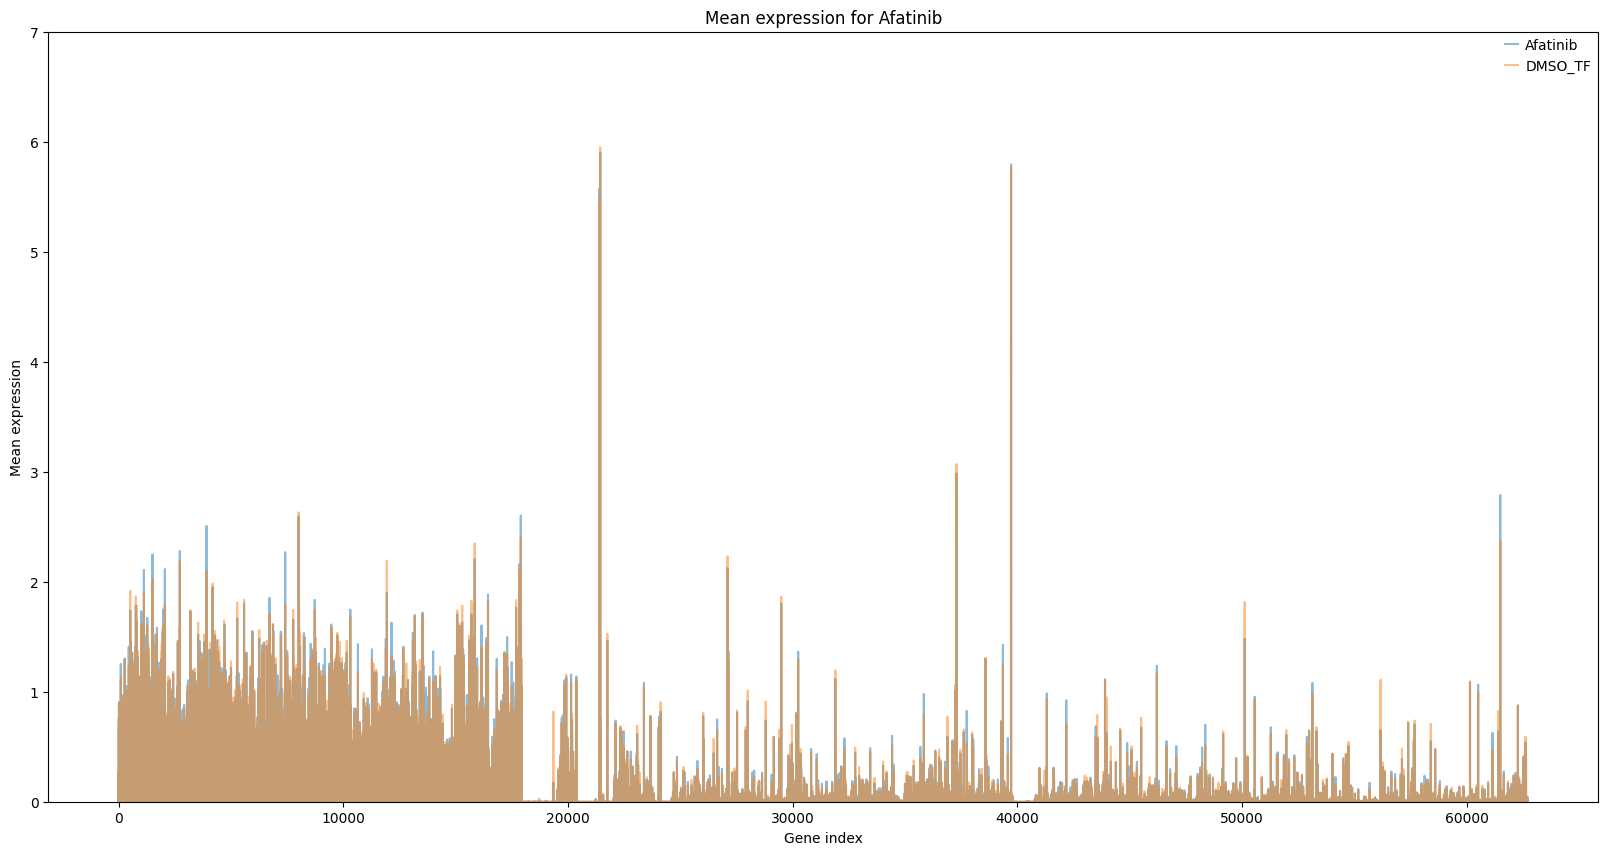

Pearson correlation between Torkinib and control: 0.9900


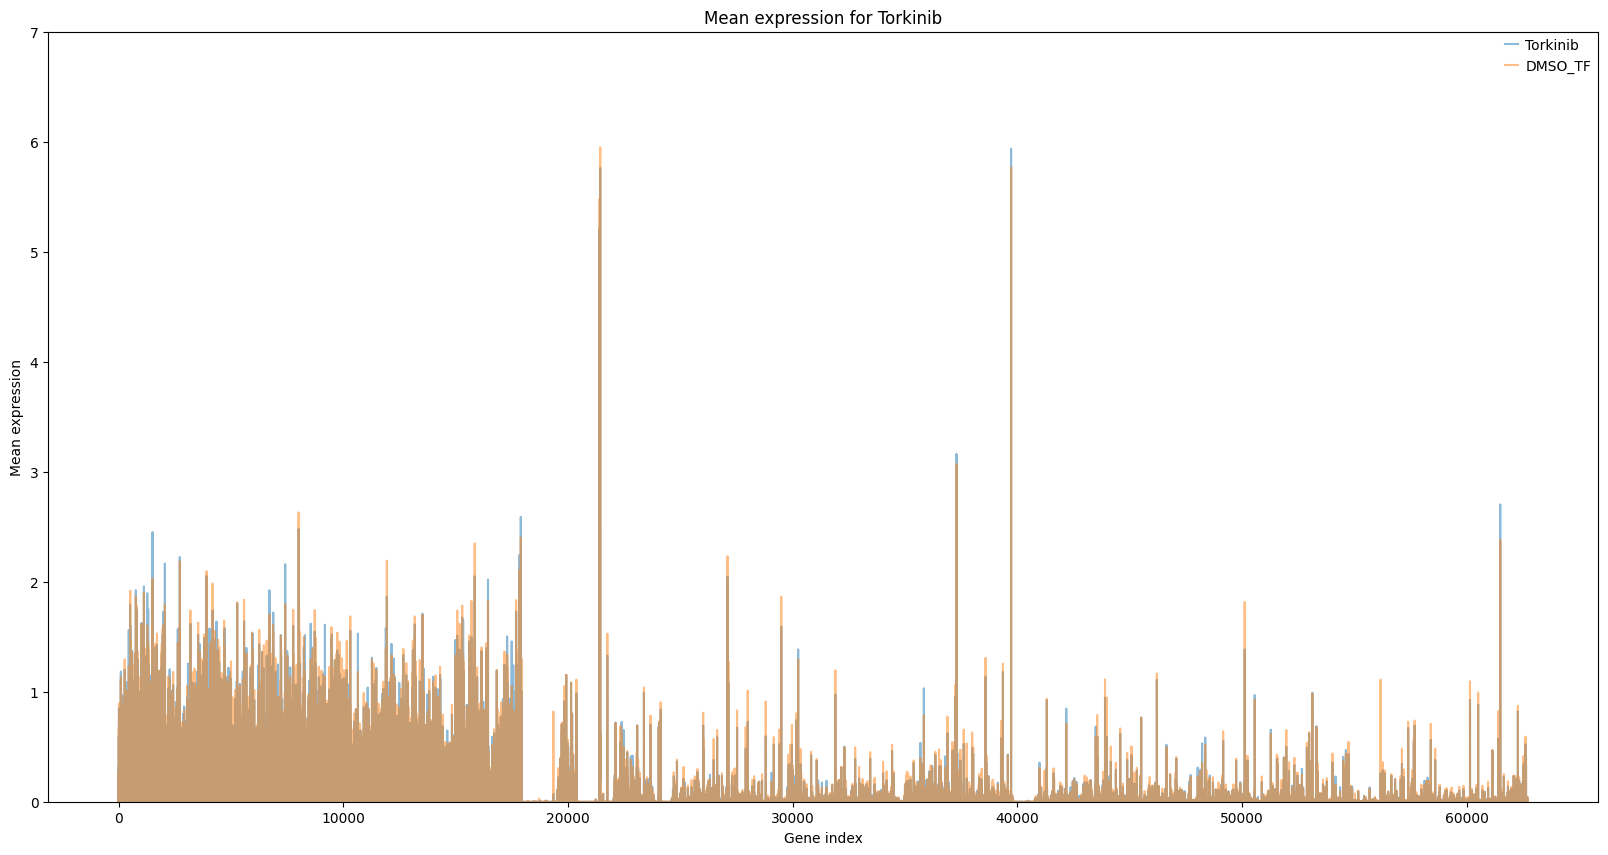

Pearson correlation between Ixazomib and control: 0.9936


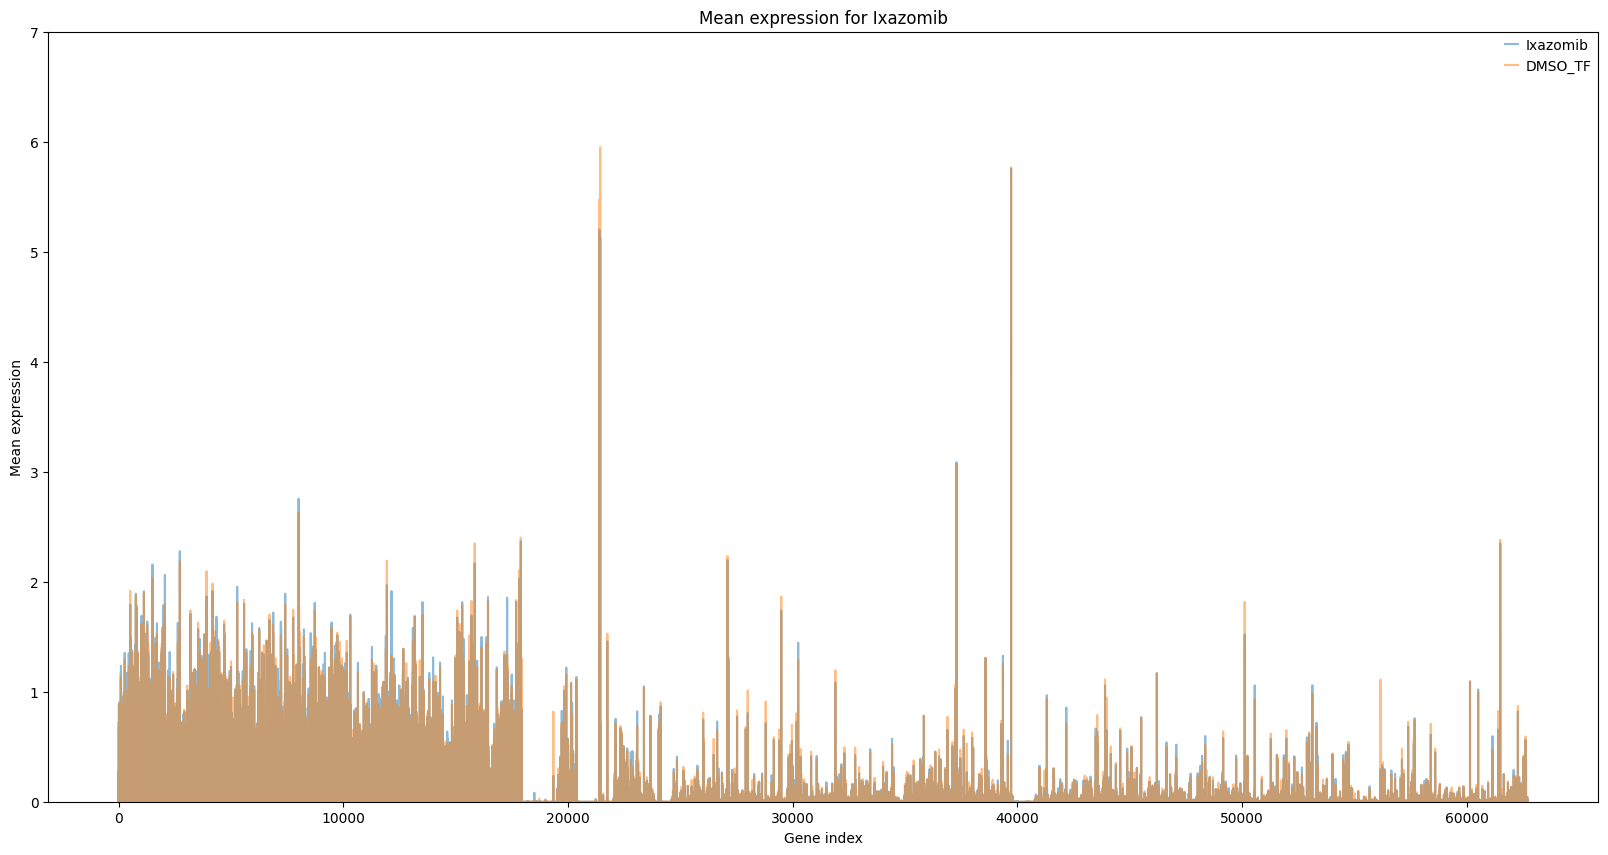

Pearson correlation between Capmatinib and control: 0.9903


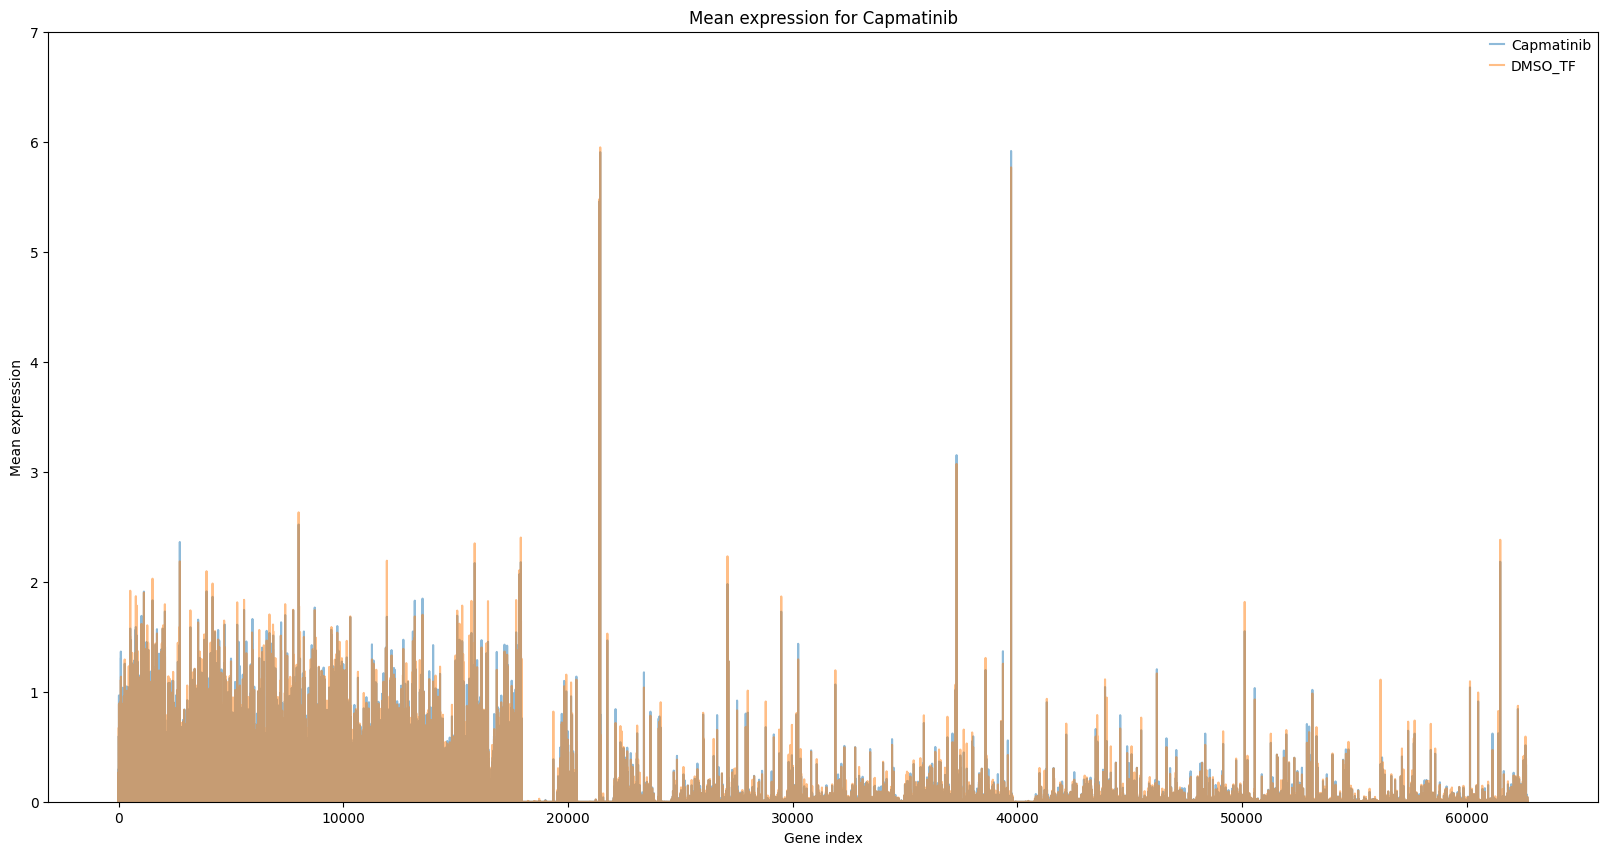

Pearson correlation between Lapatinib ditosylate and control: 0.9939


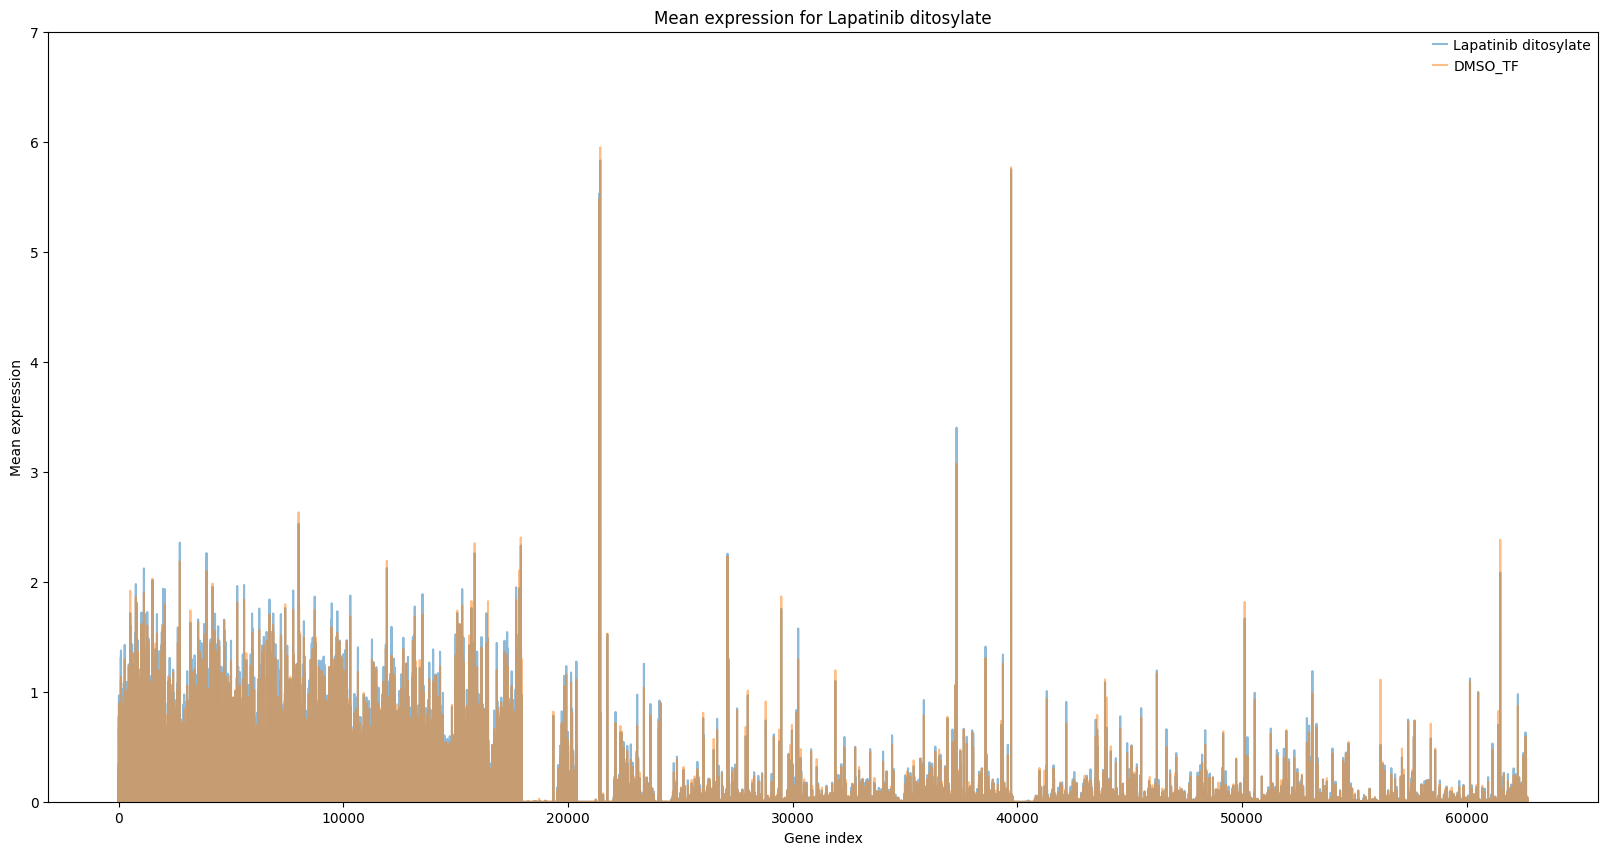

Pearson correlation between AT7519 and control: 0.9941


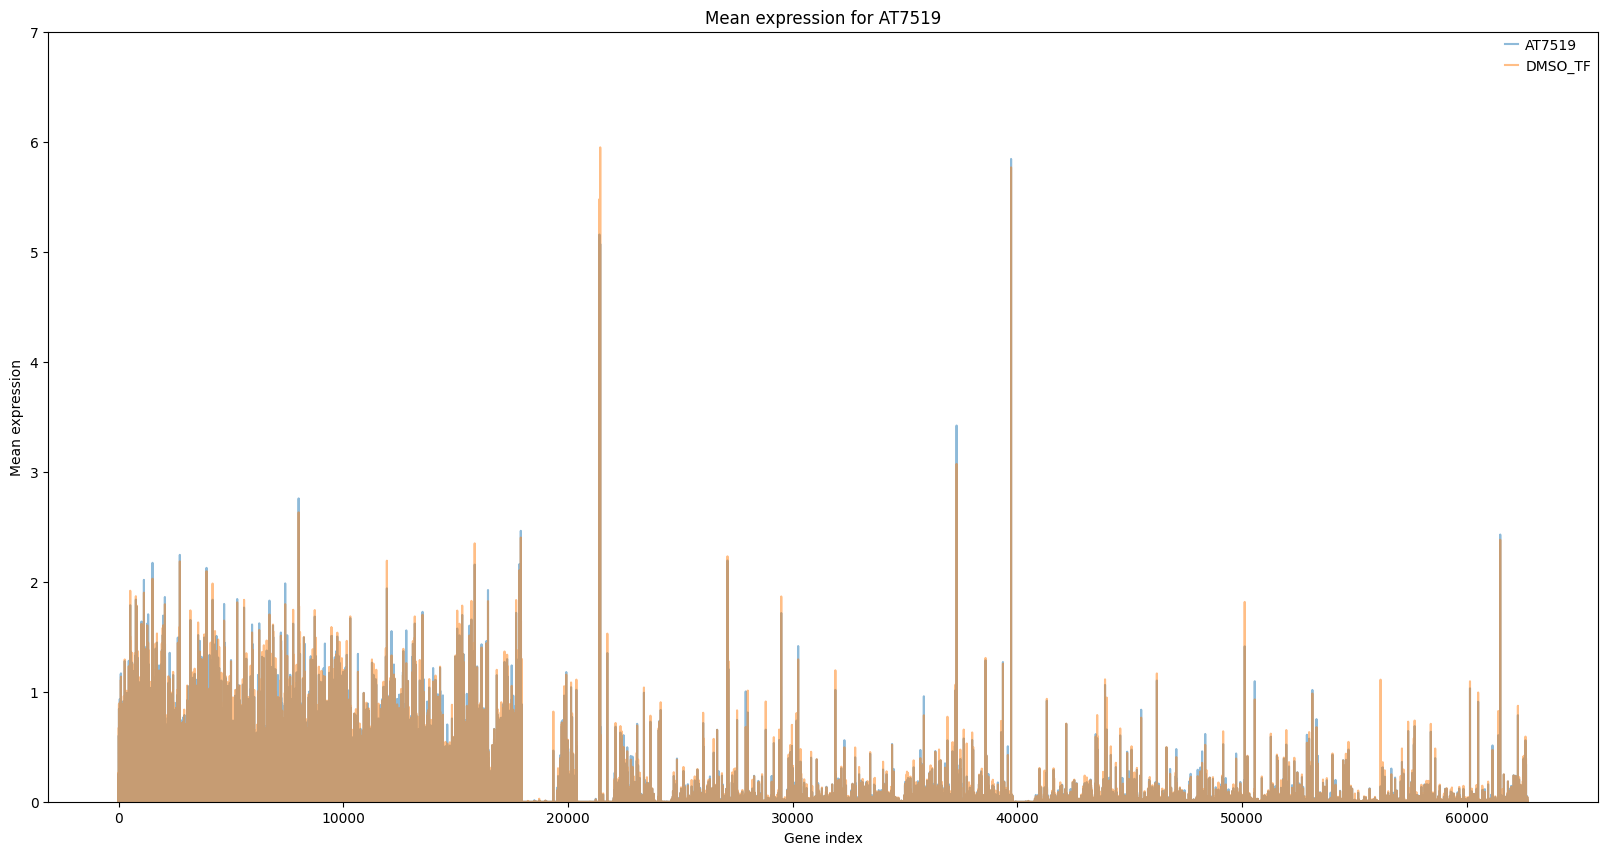

Pearson correlation between Capivasertib and control: 0.9944


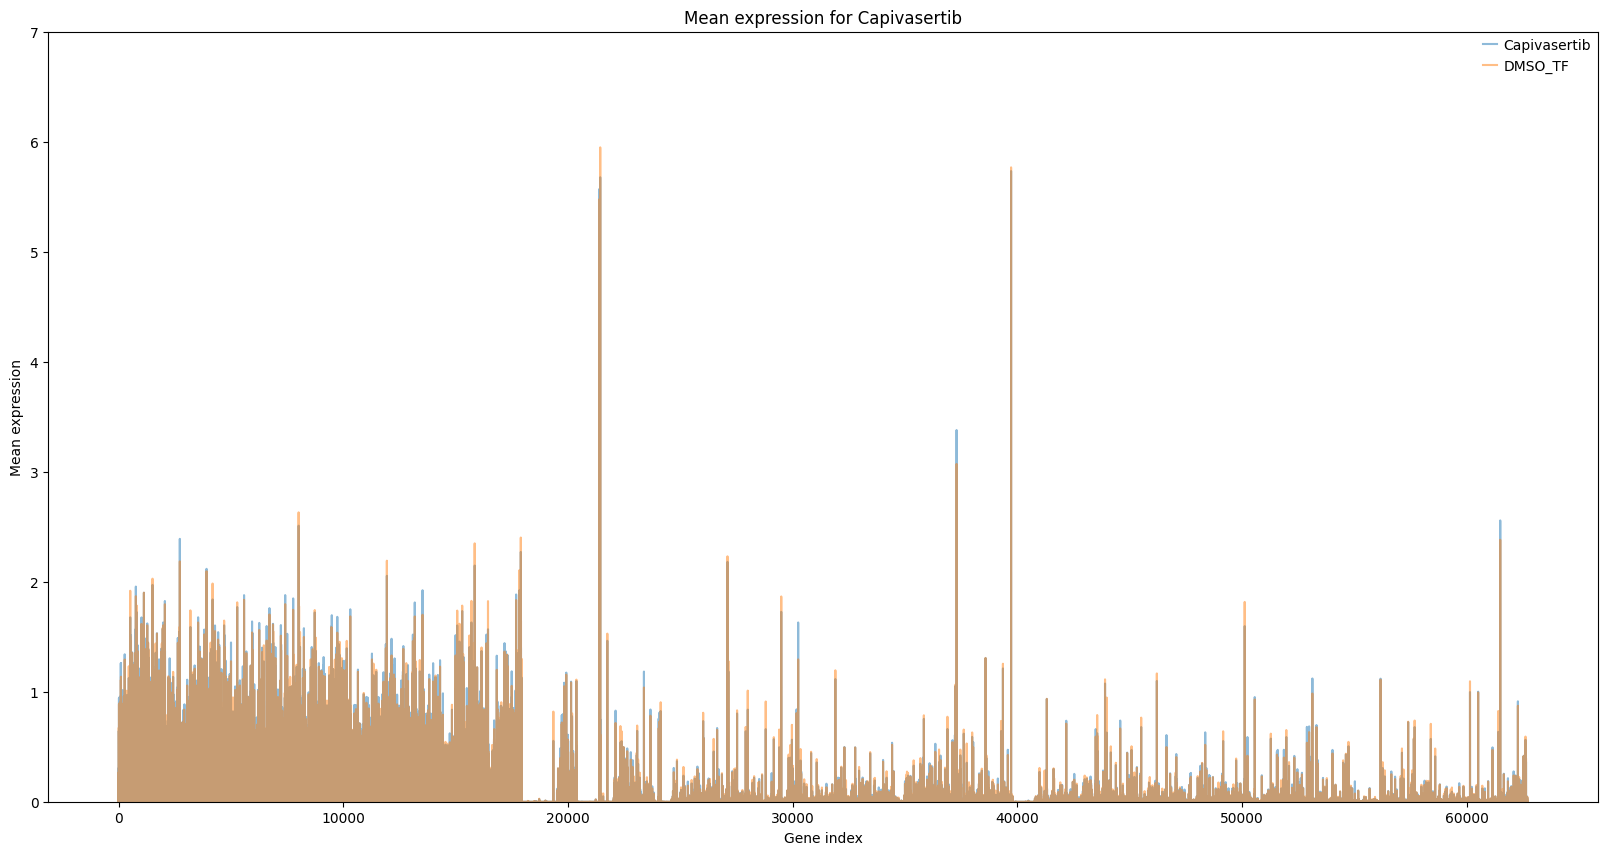

Pearson correlation between Oleic acid and control: 0.9917


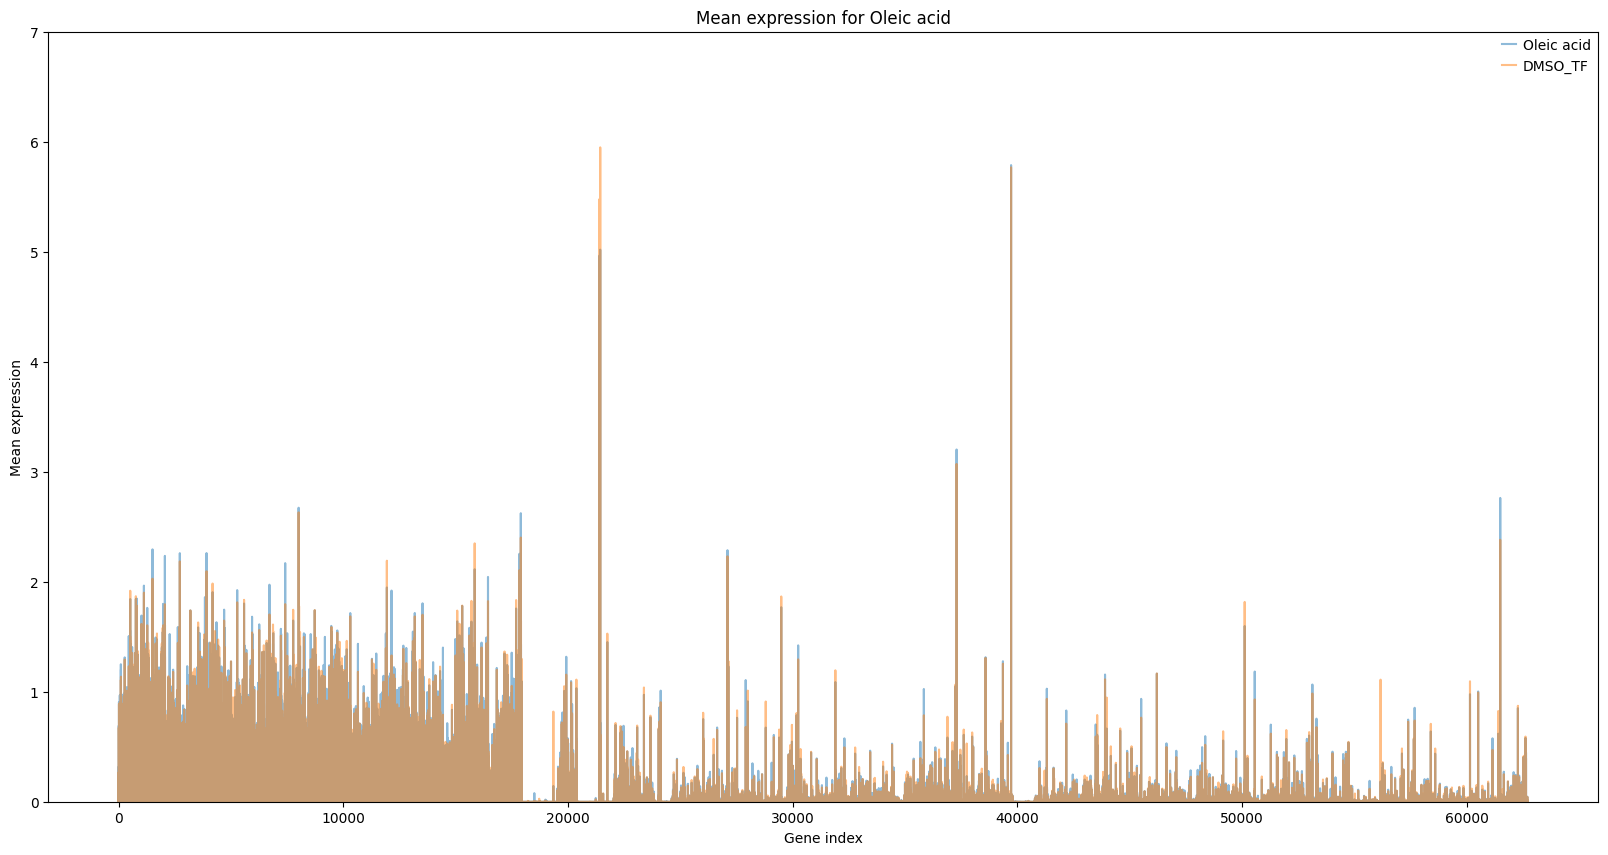

Pearson correlation between c-Kit-IN-1 and control: 0.9891


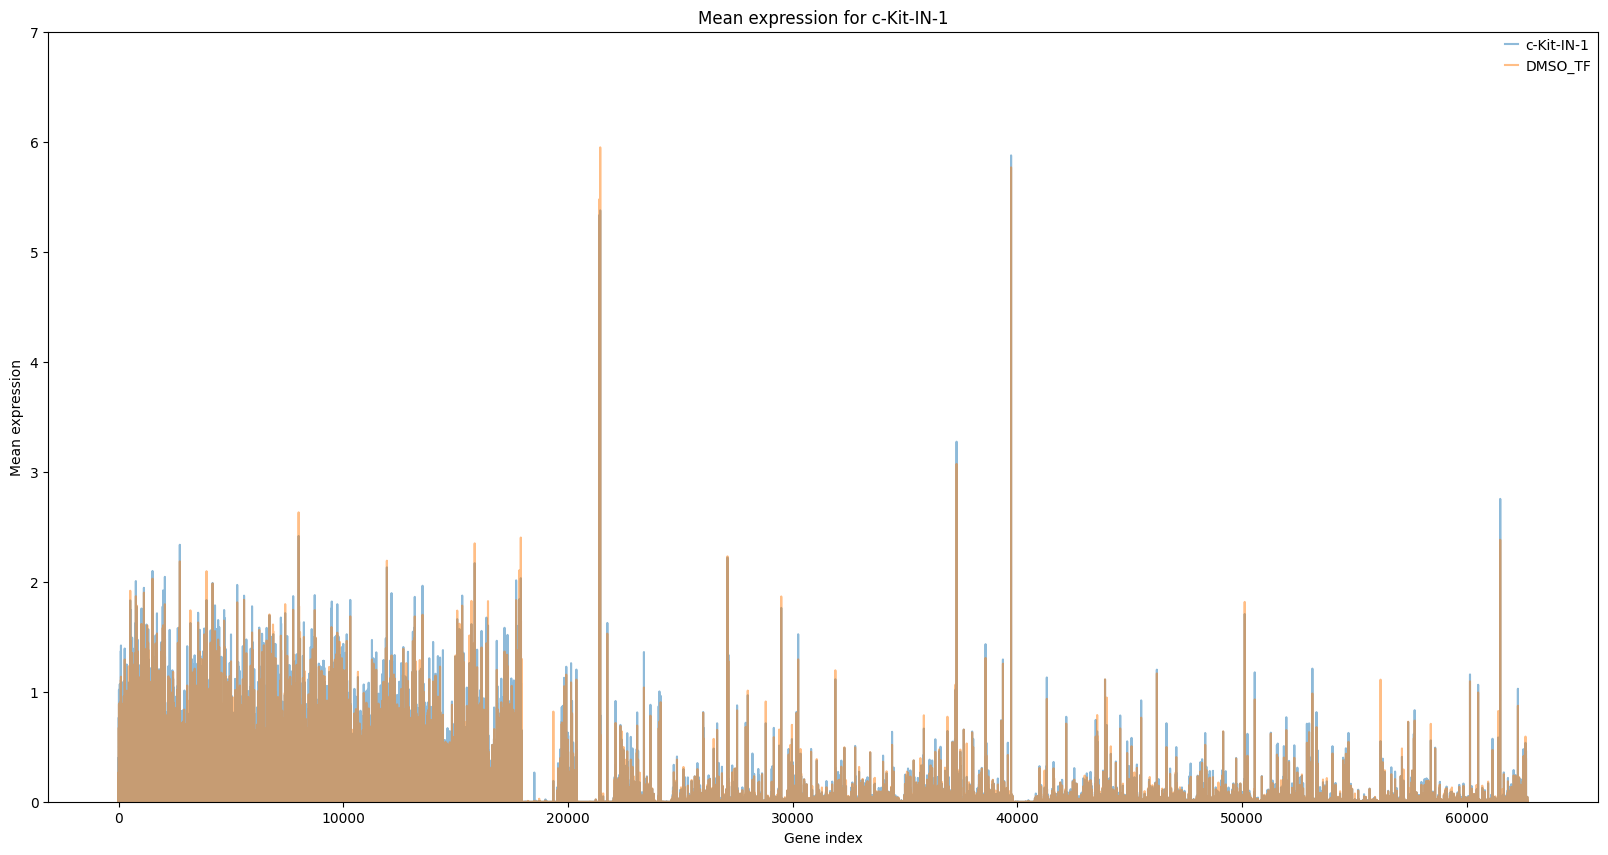

Pearson correlation between Infigratinib and control: 0.9906


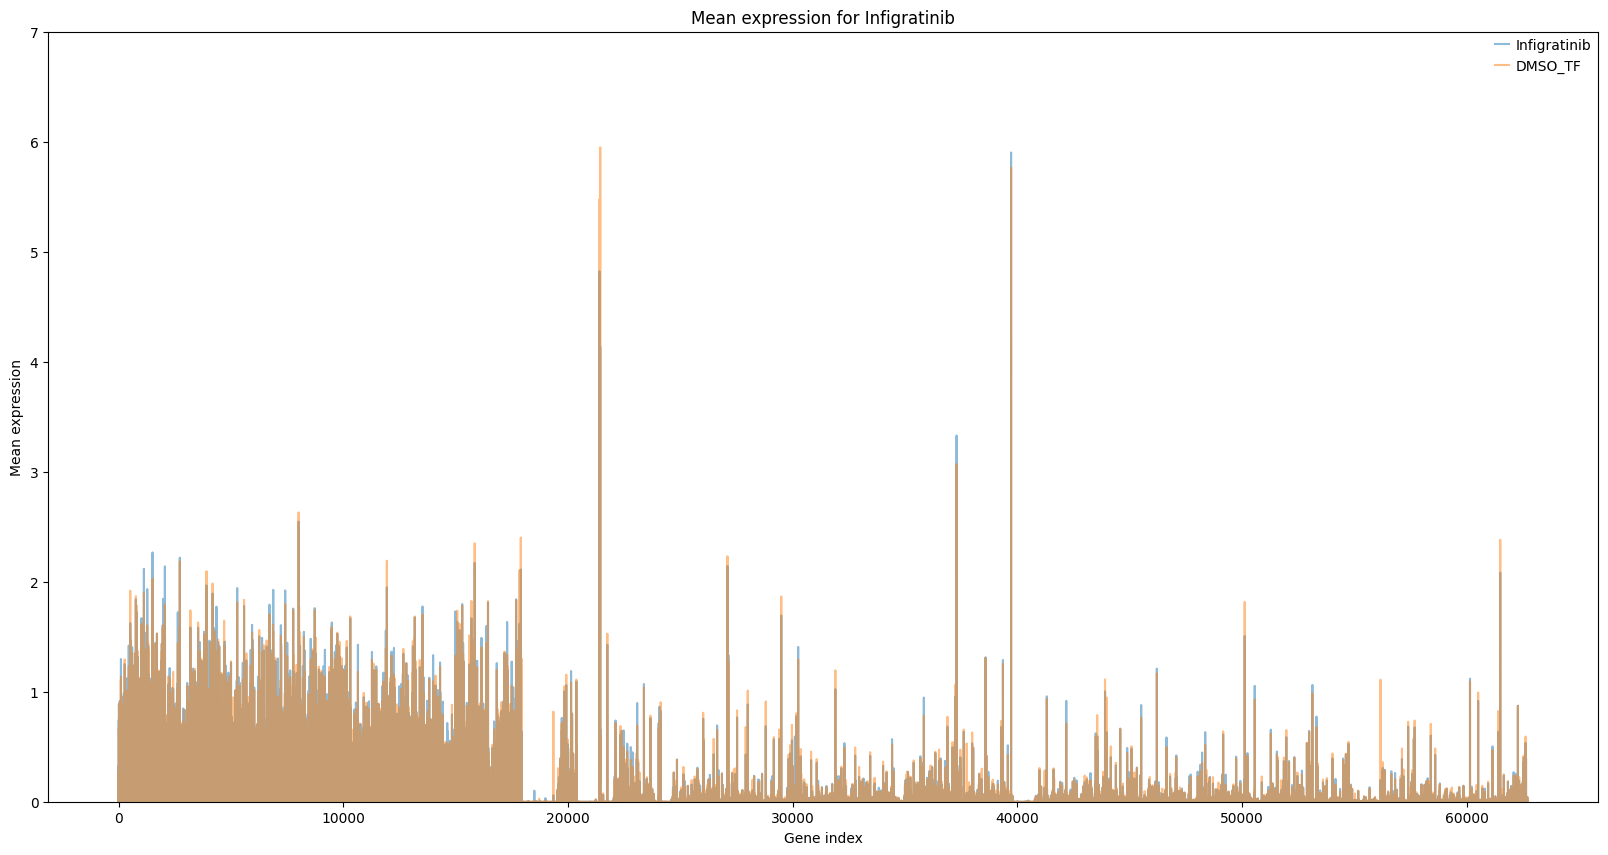

Pearson correlation between Elimusertib hydrochloride and control: 0.9853


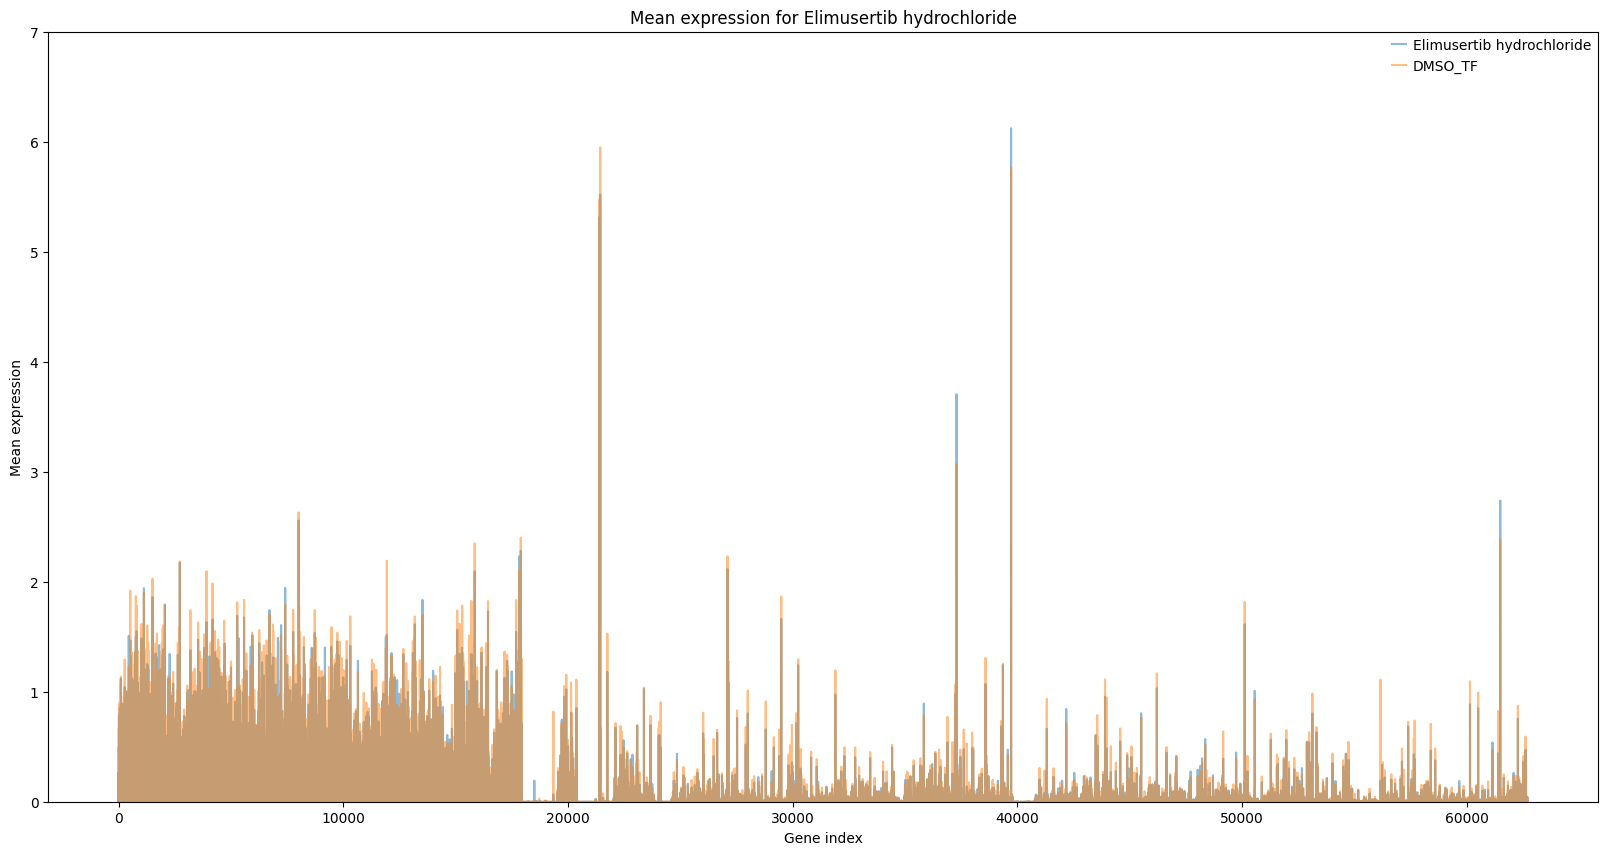

In [ ]:
all_drugs = adata.obs['drug'].unique().tolist()
mean_pearson_correlation_and_plot(top30_drugs)


# Variance Comparison

In [ ]:
control_var = np.var(adata[adata.obs['drug'] == 'DMSO_TF'].X.toarray(), axis=0)

def variance_plot(drugs):
    # means = {}
    for drug in drugs:
        mask = adata.obs["drug"] == drug
        adata_pert = adata[mask]
        adata_array = adata_pert.X.toarray()
        var = np.var(adata_array, axis=0)

        plt.figure(figsize=(20, 10))
        plt.plot(var, label=drug, alpha=0.5)
        plt.plot(control_var, label="DMSO_TF", alpha=0.5)
        plt.title(f"Variance by gene for {drug}")
        plt.xlabel("Gene index")
        plt.ylabel("Gene Variance")
        plt.ylim(0, 4)
        plt.legend()
        plt.show()
    
    # Calculate Pearson correlation between the mean expression profiles of the drugs
    # for drug in drugs:
    #     corr, _ = pearsonr(means[drug], control_mean)
    #     print(f"Pearson correlation between {drug} and control: {corr:.4f}")

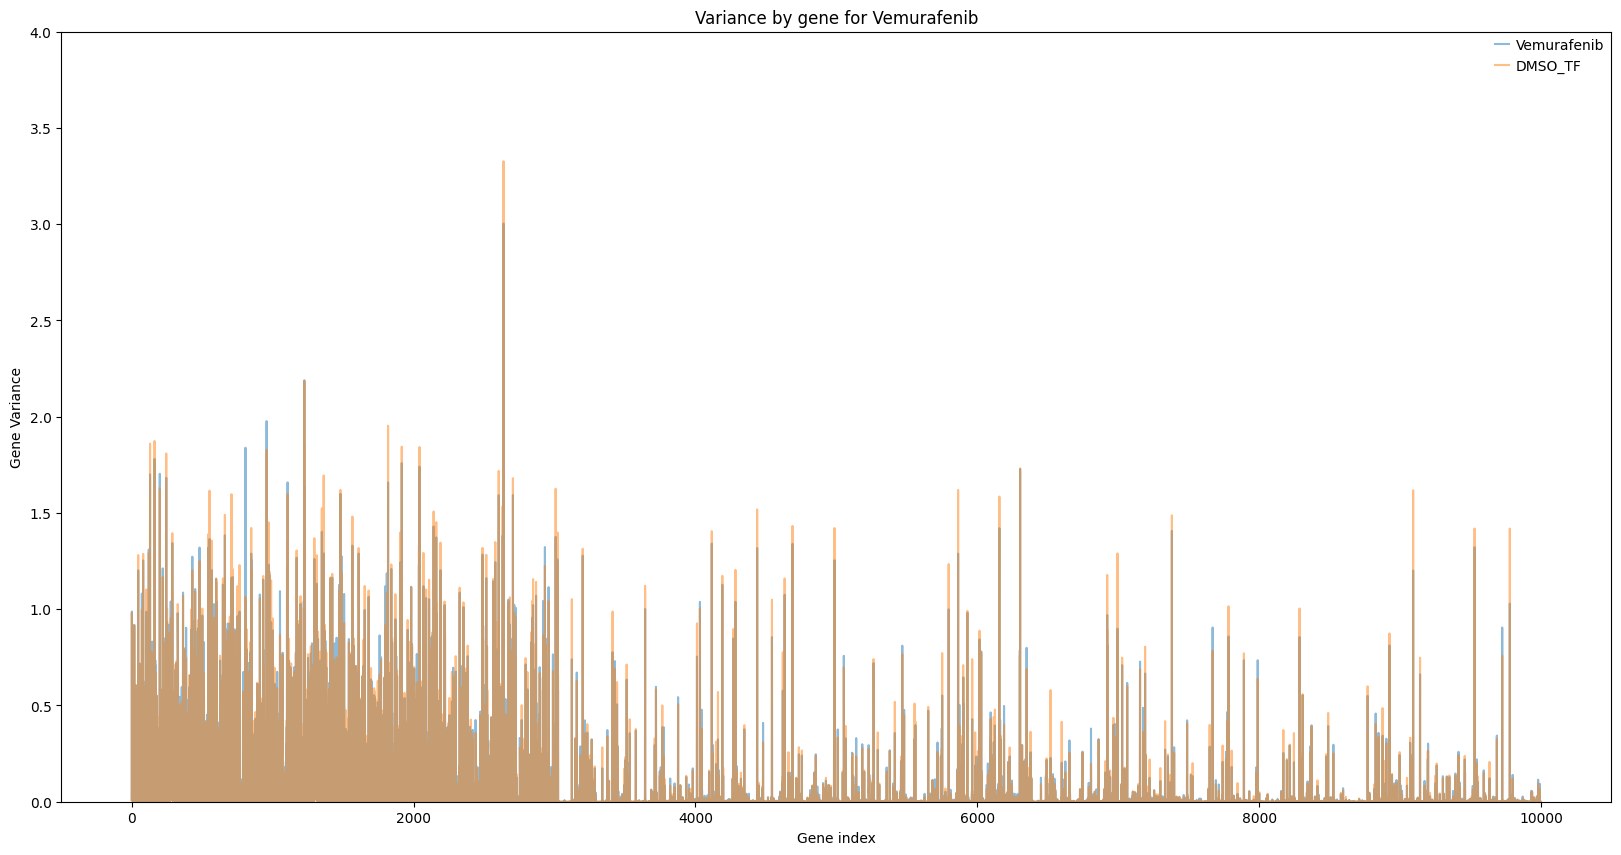

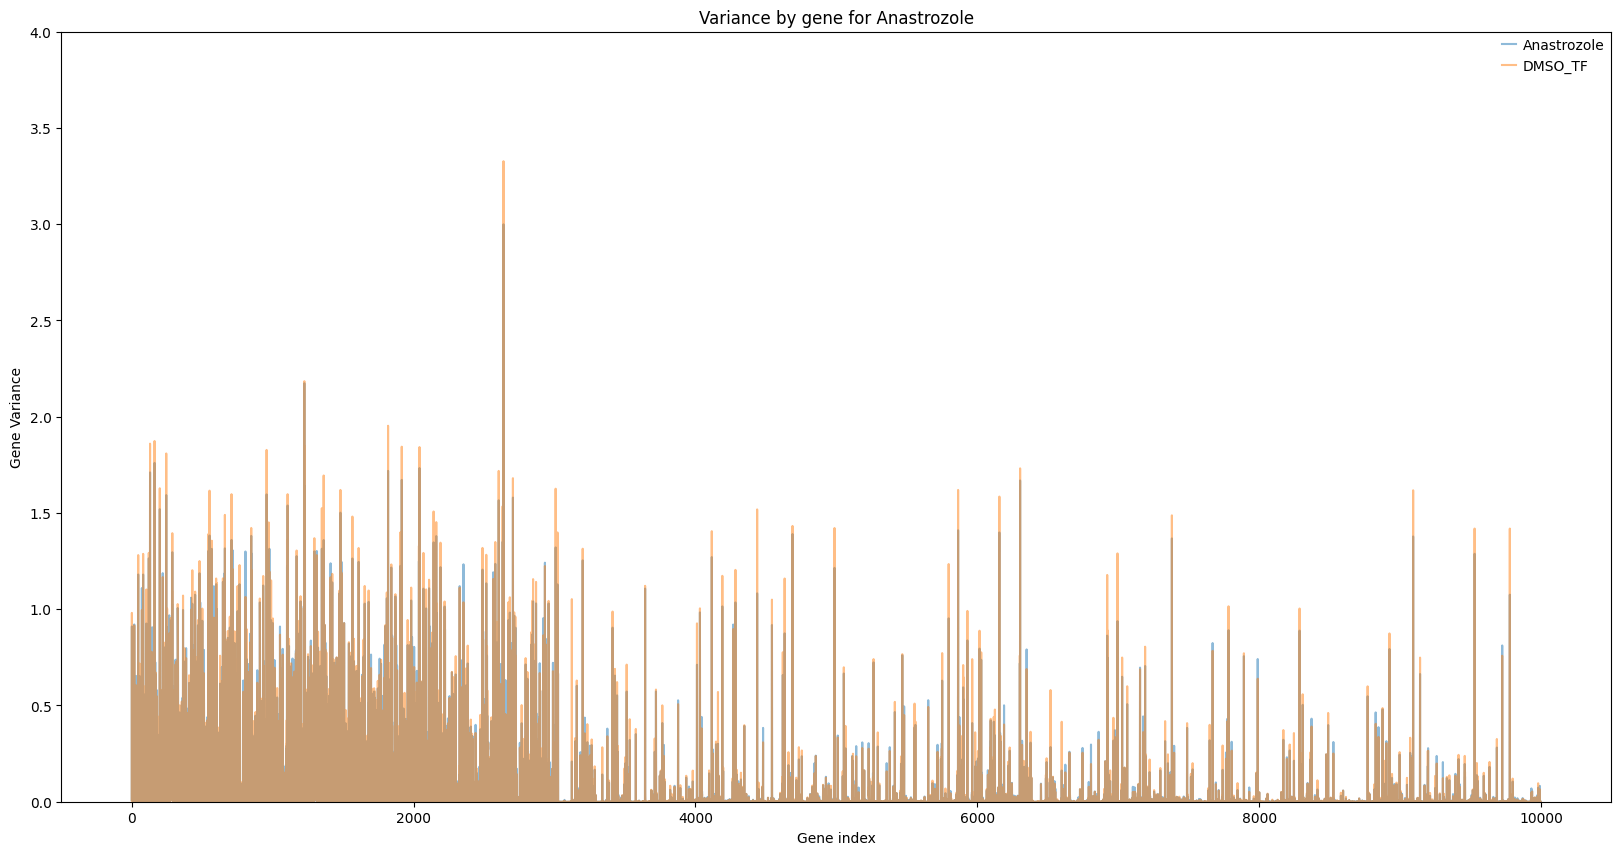

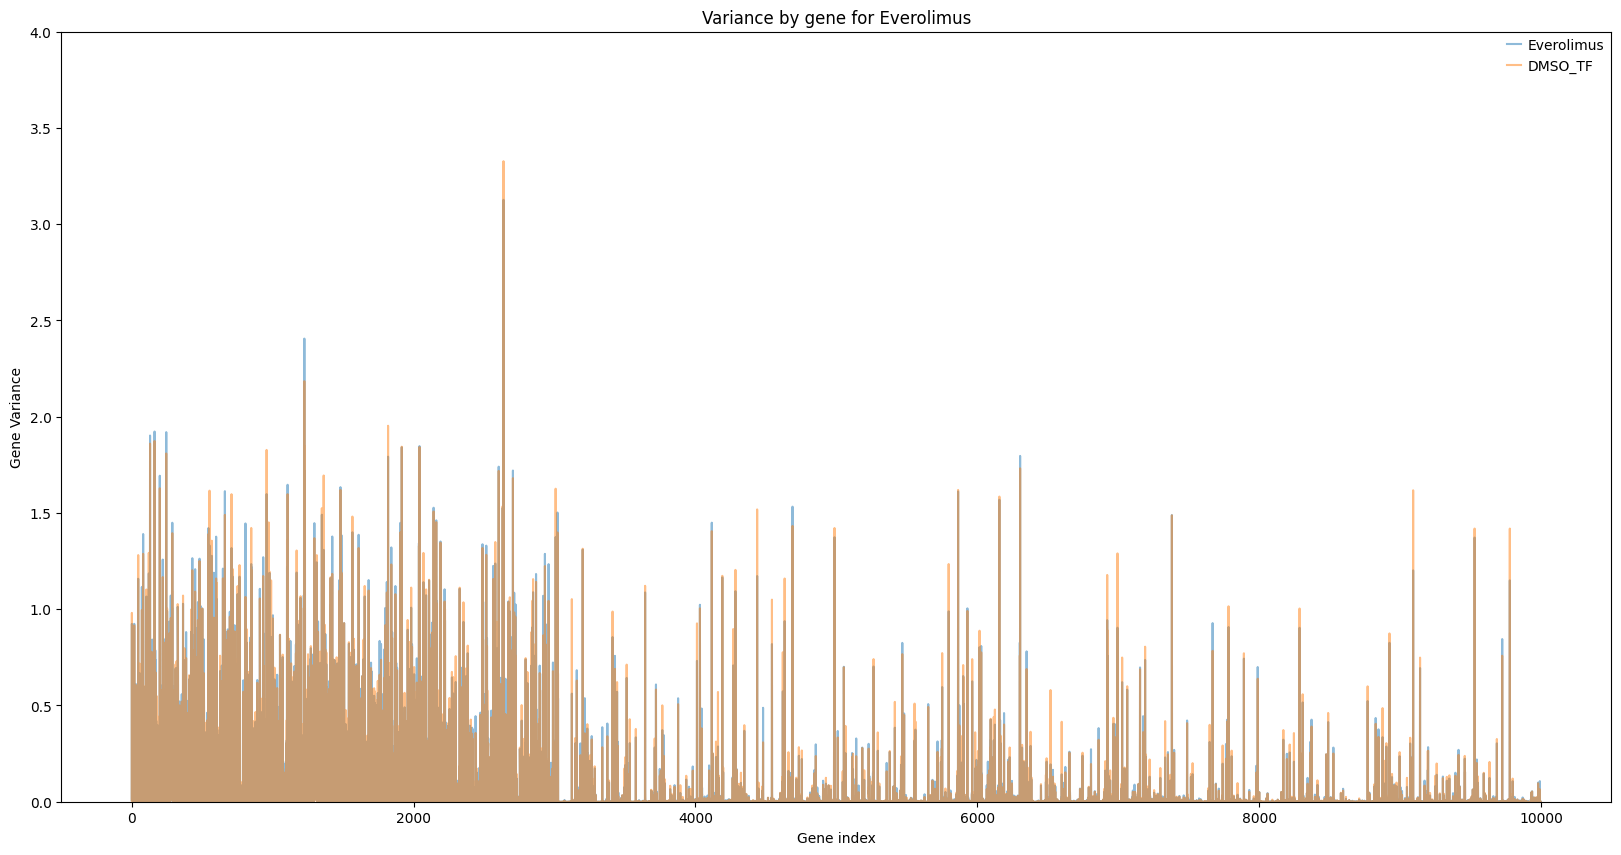

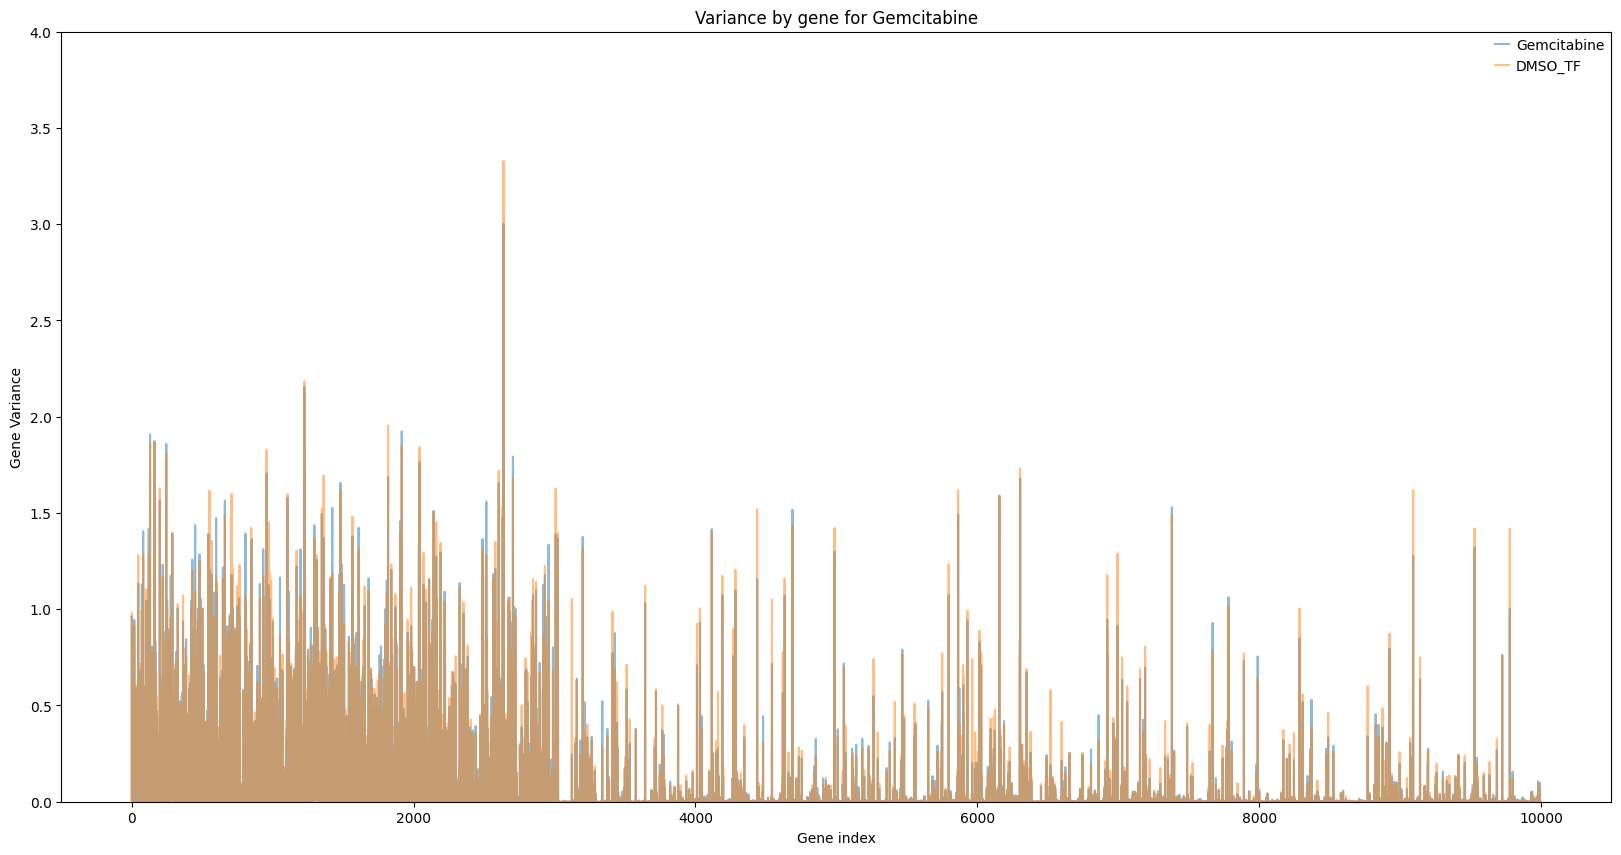

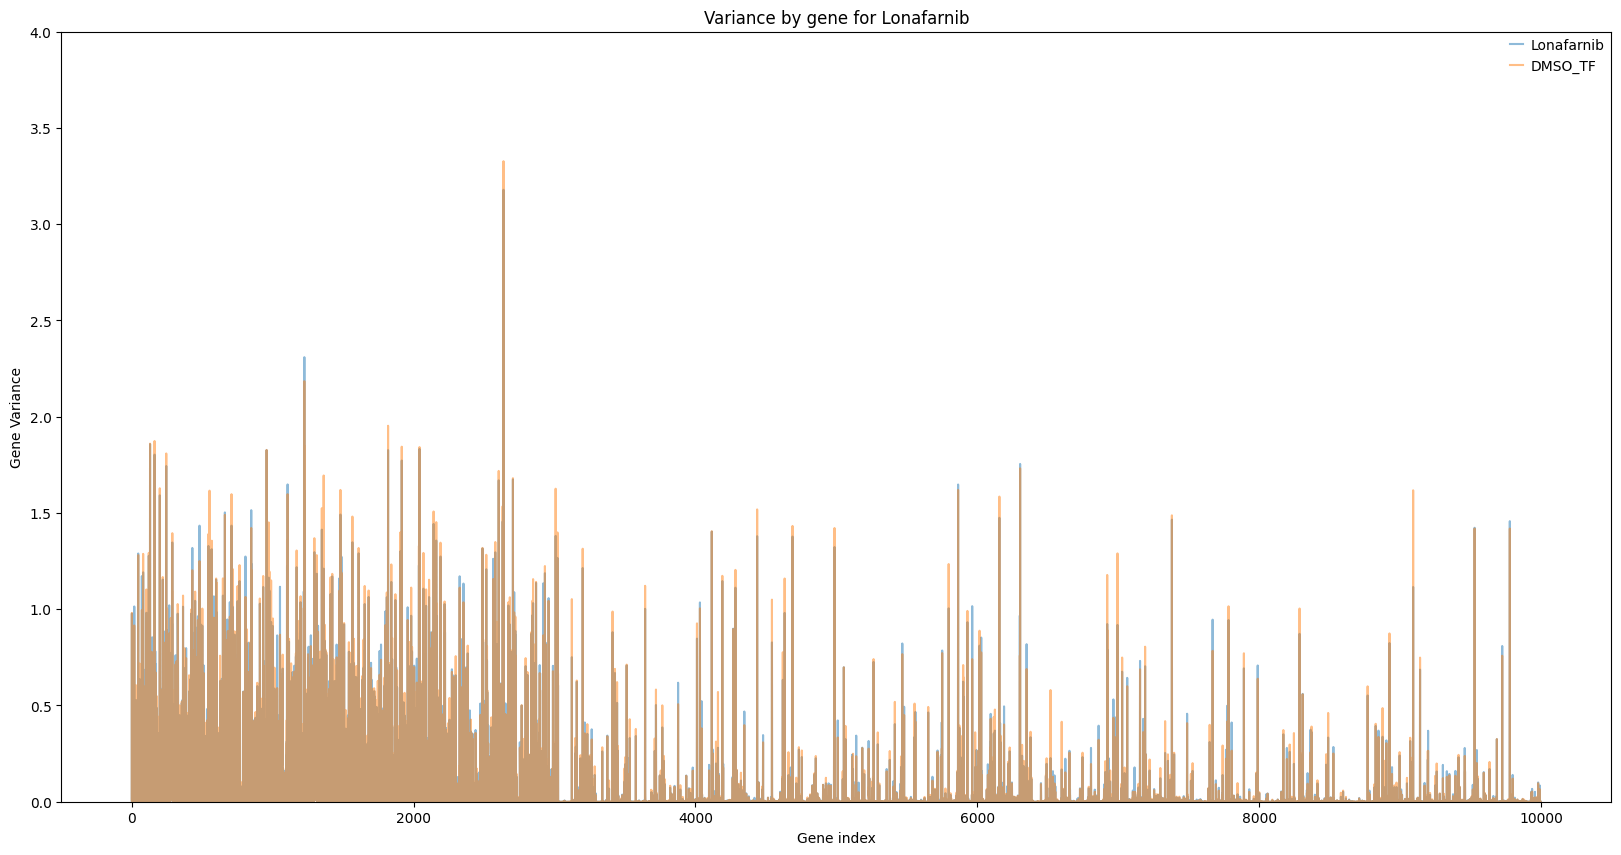

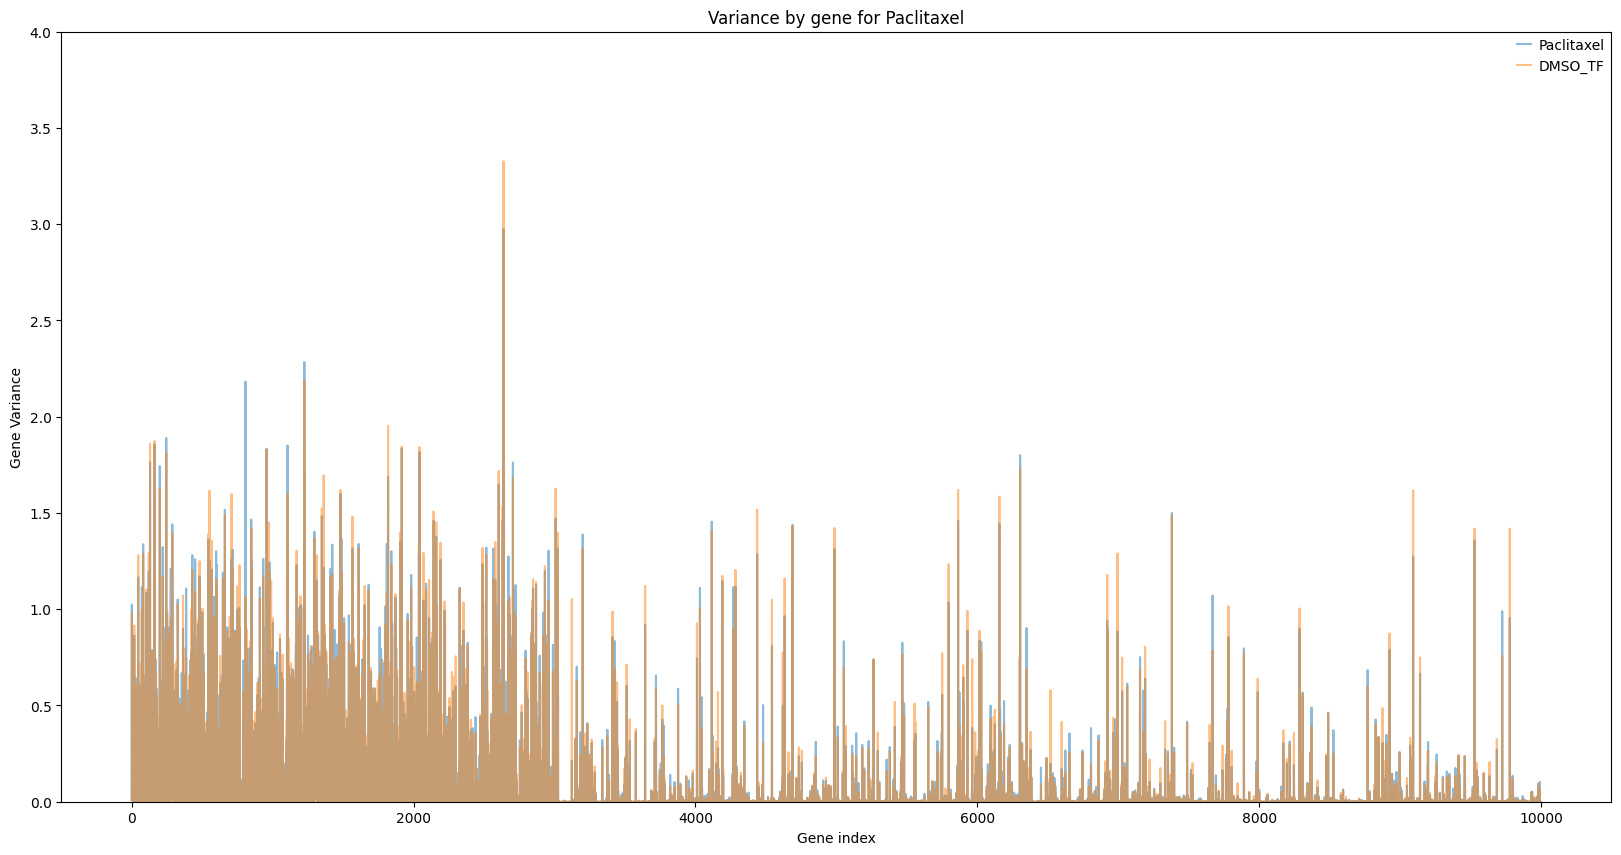

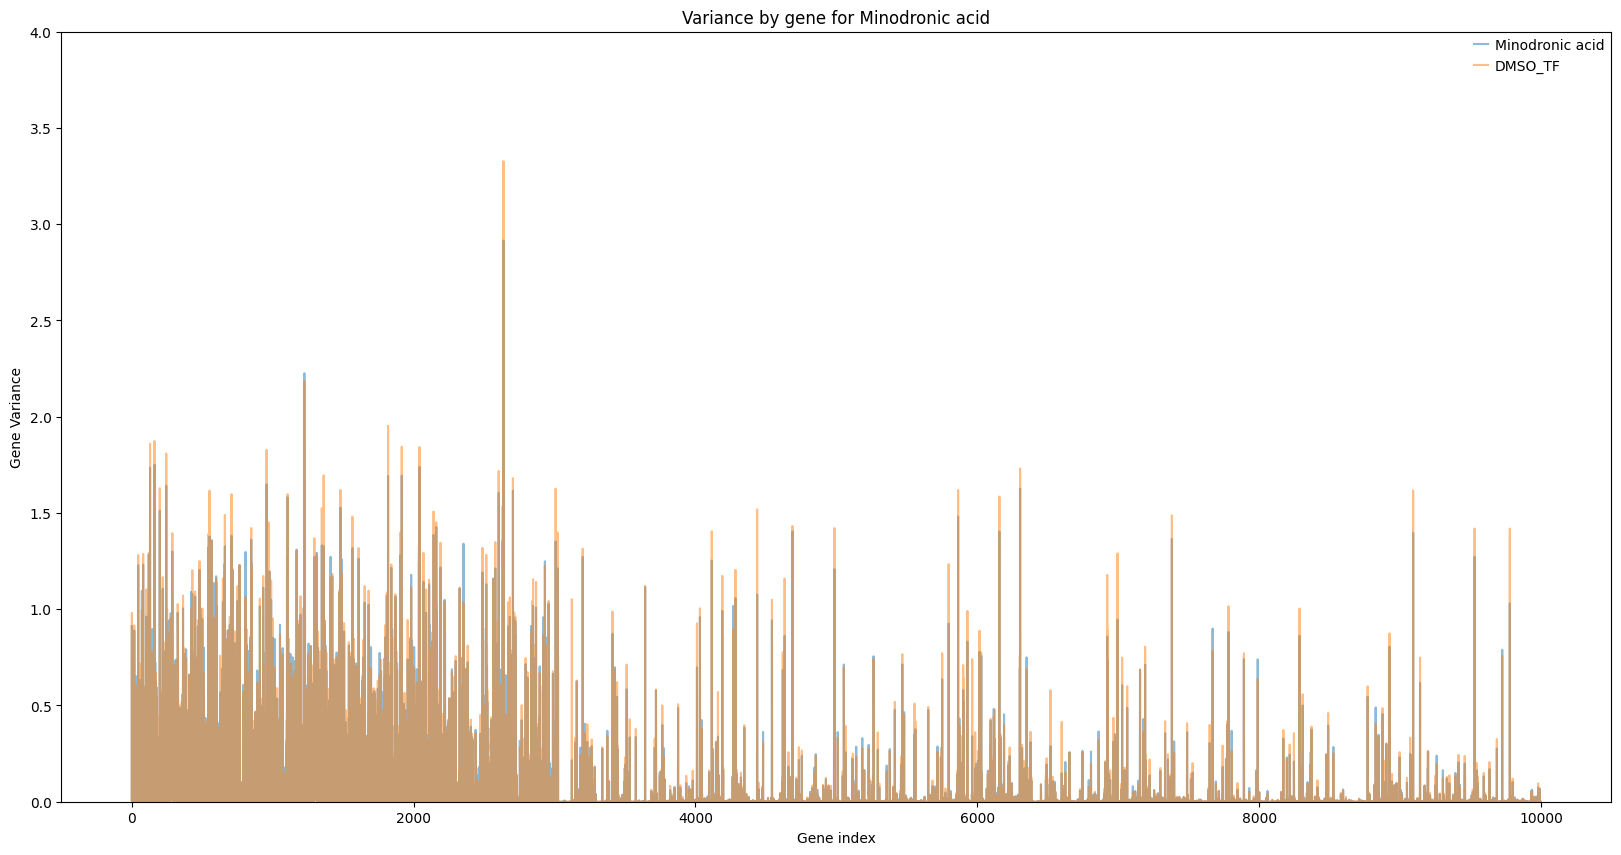

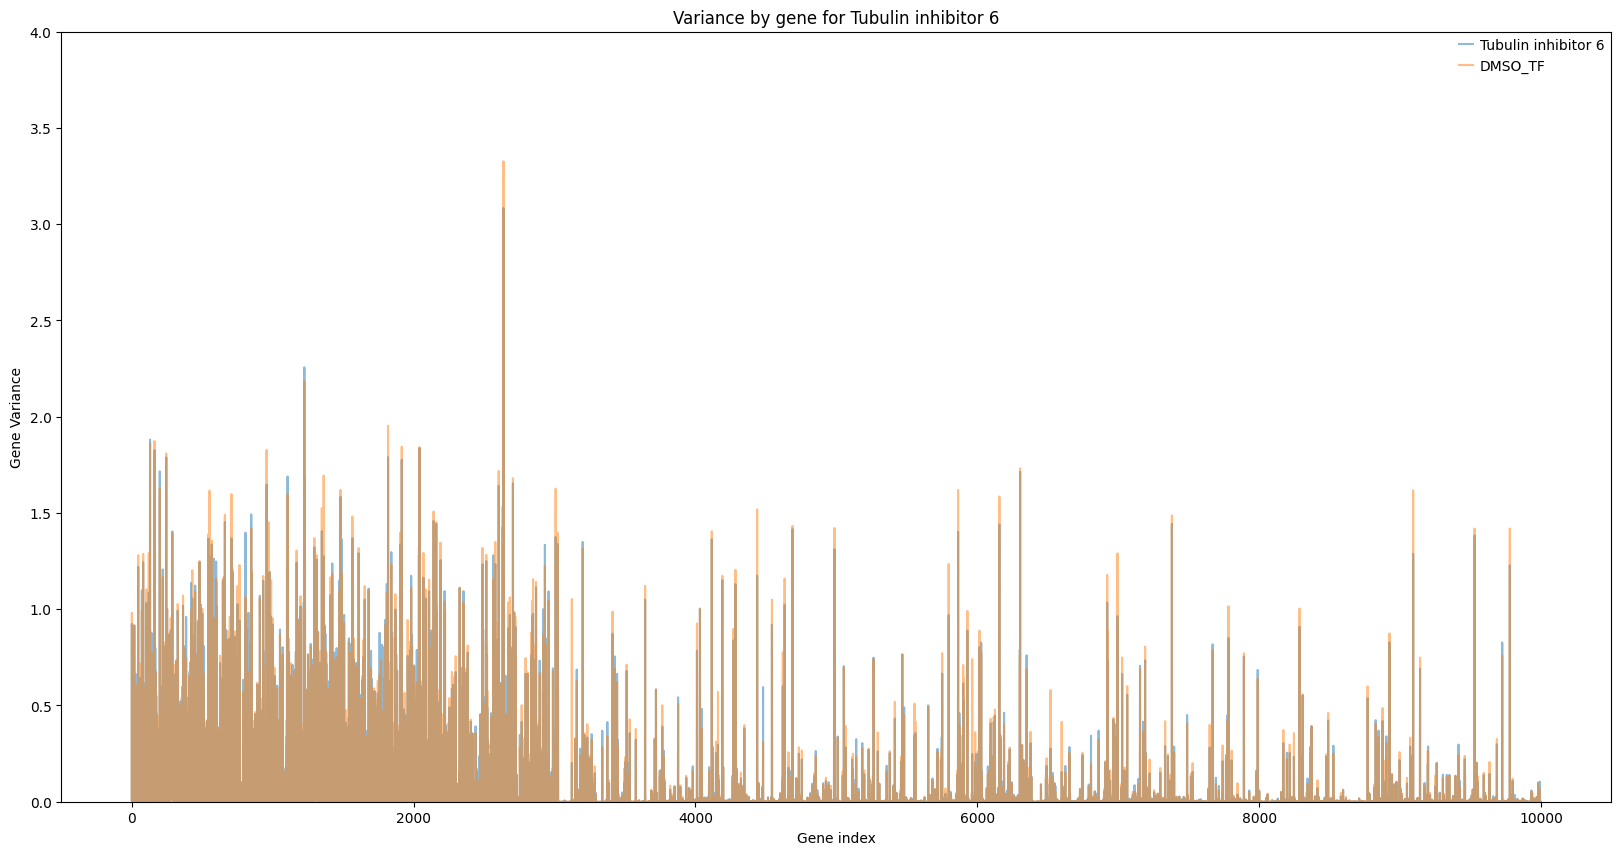

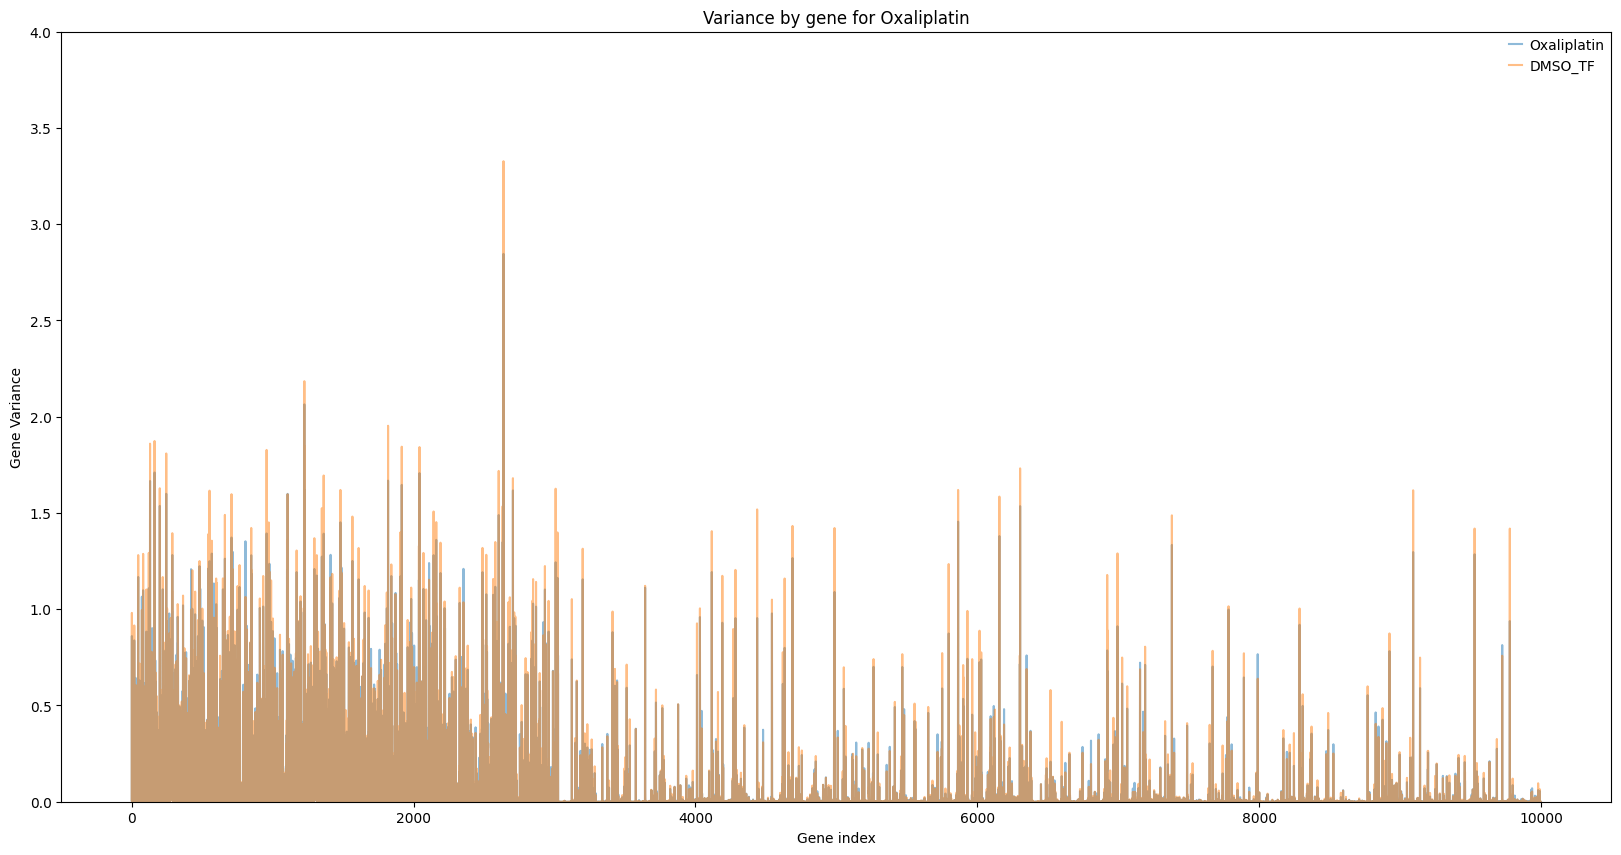

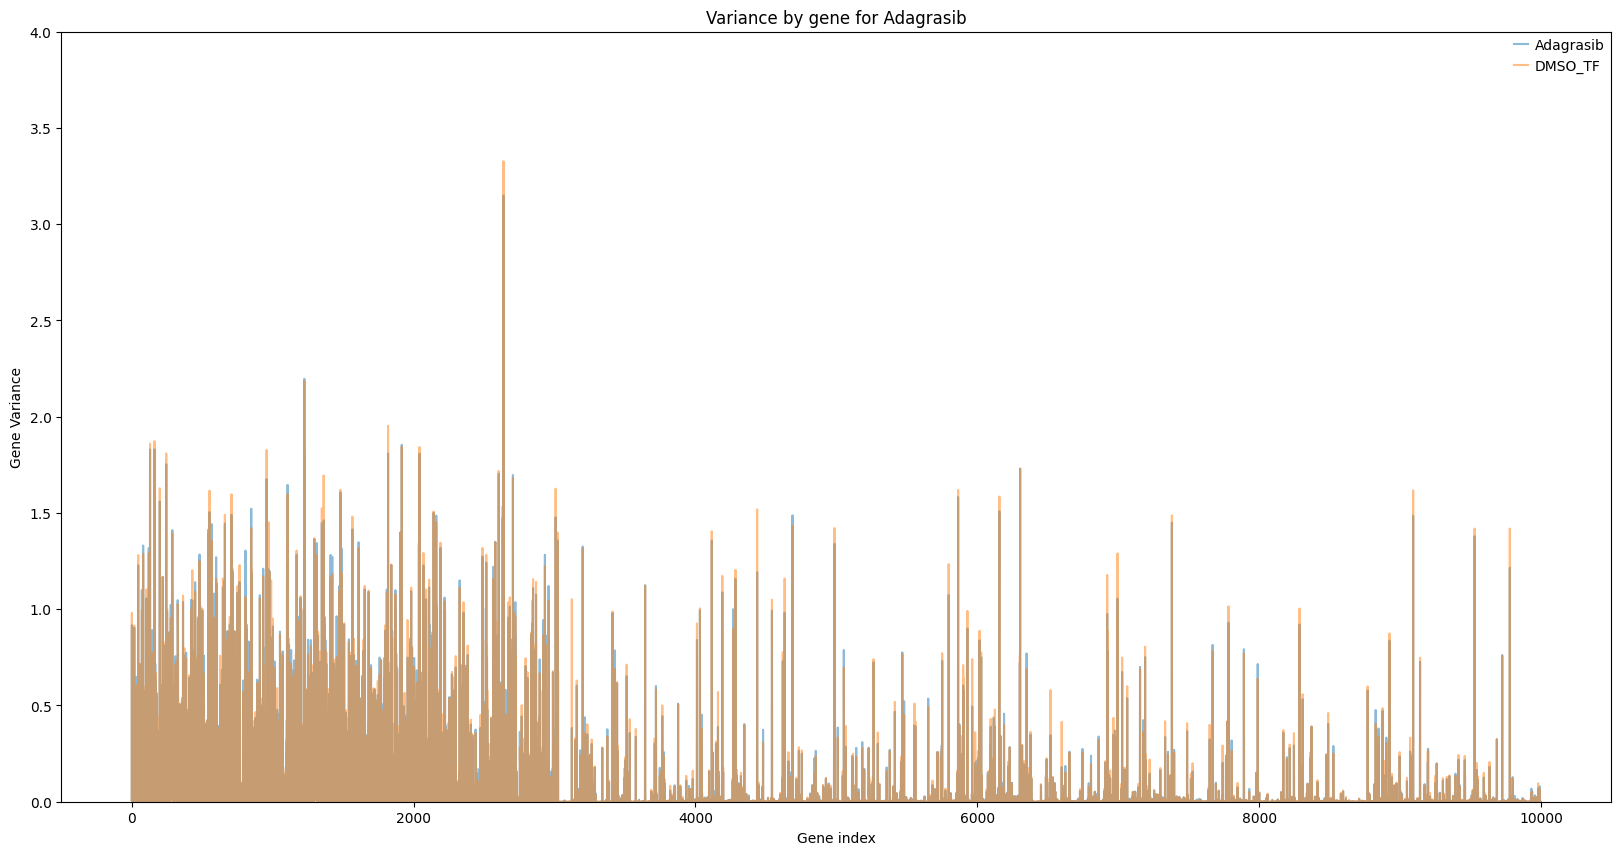

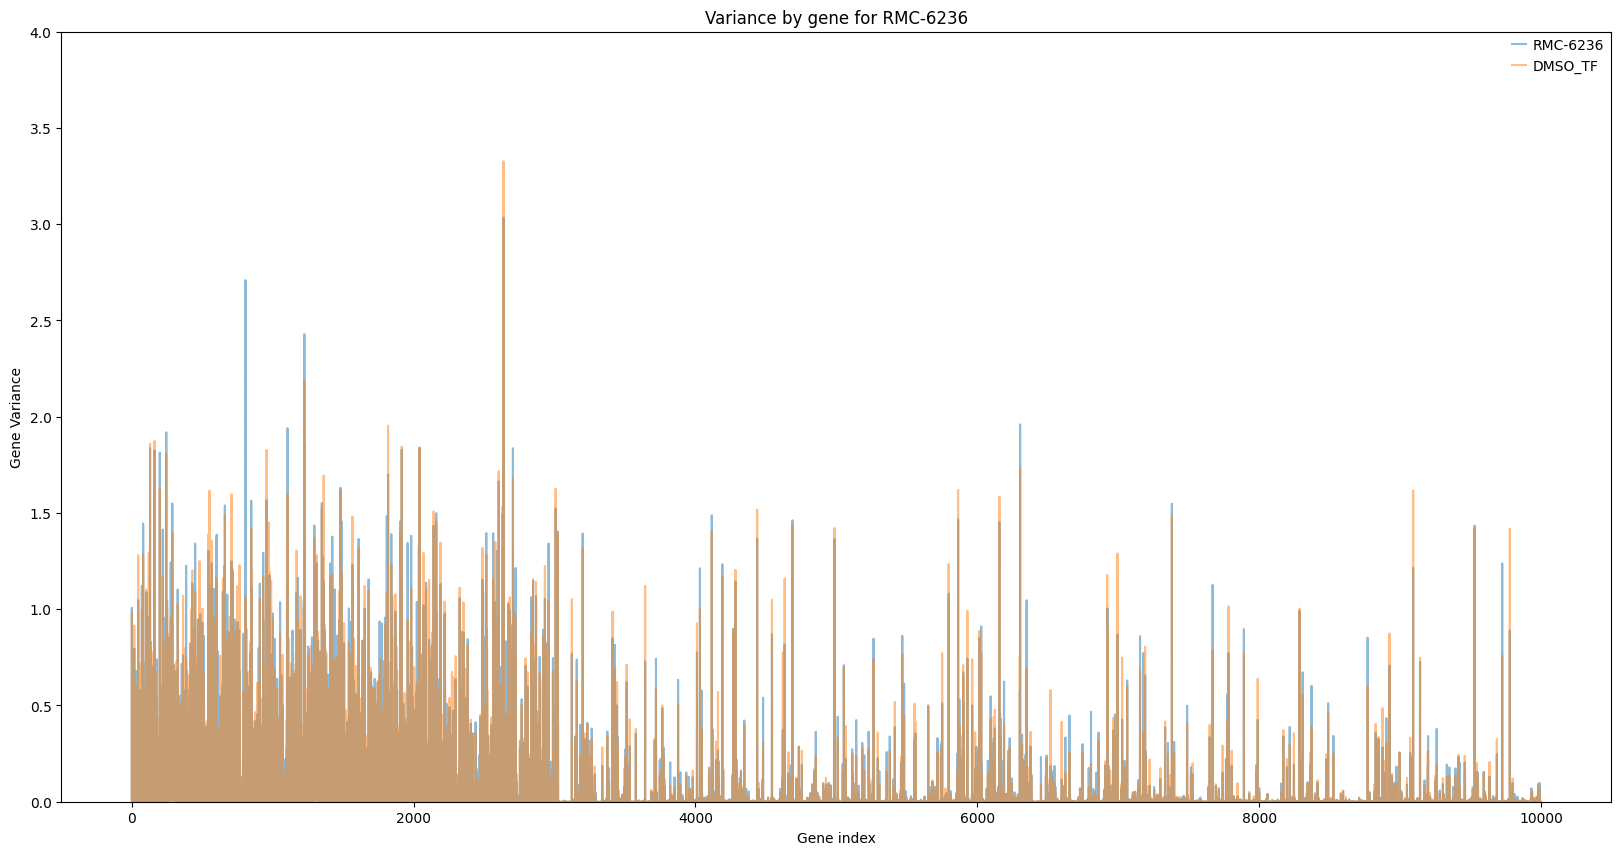

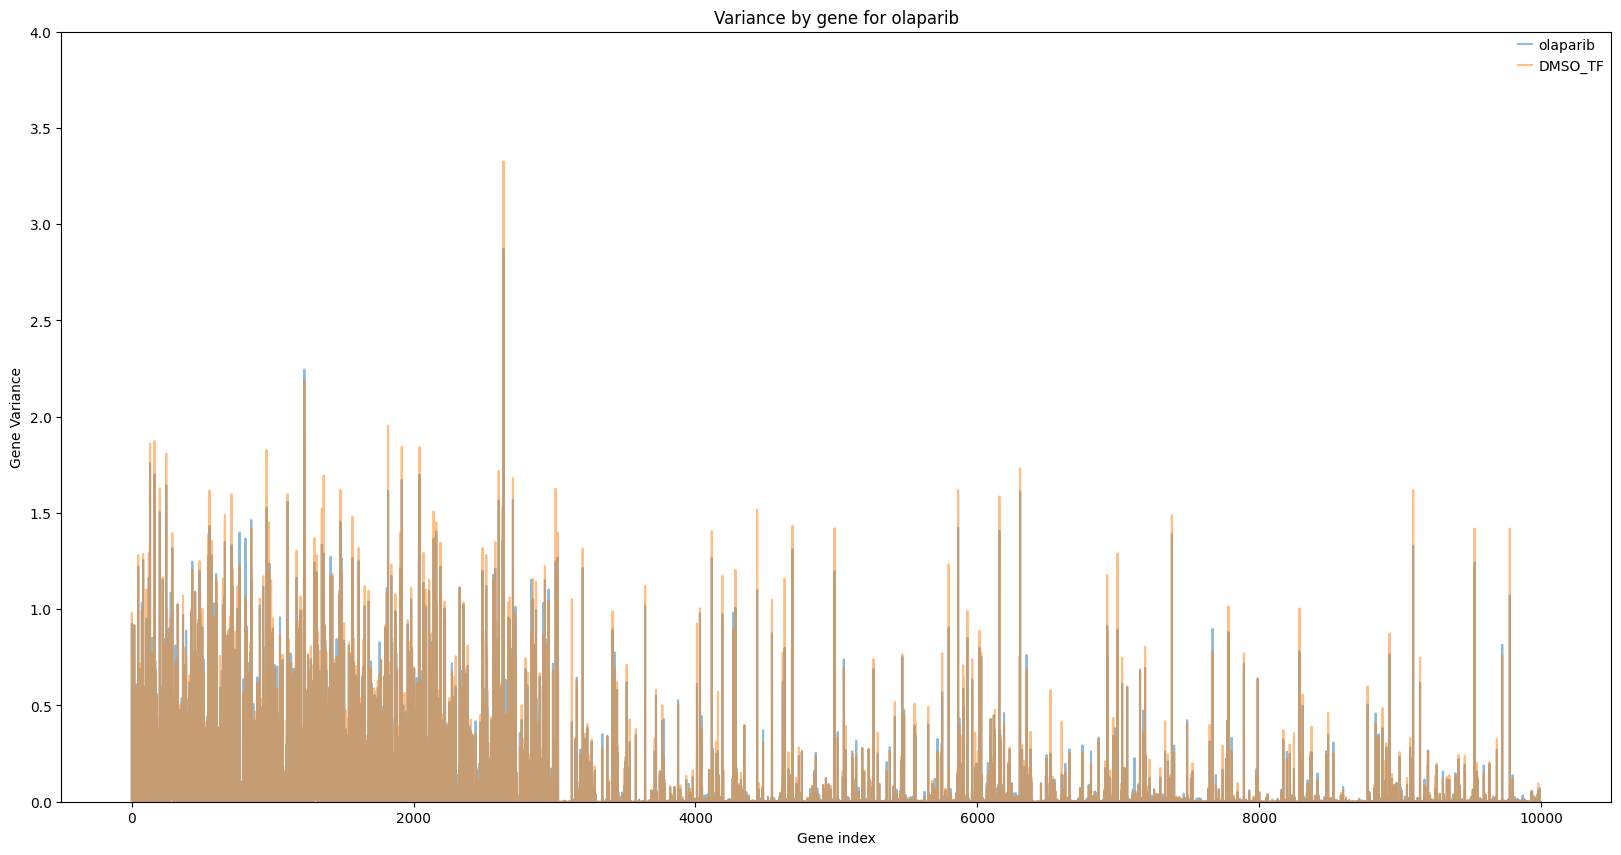

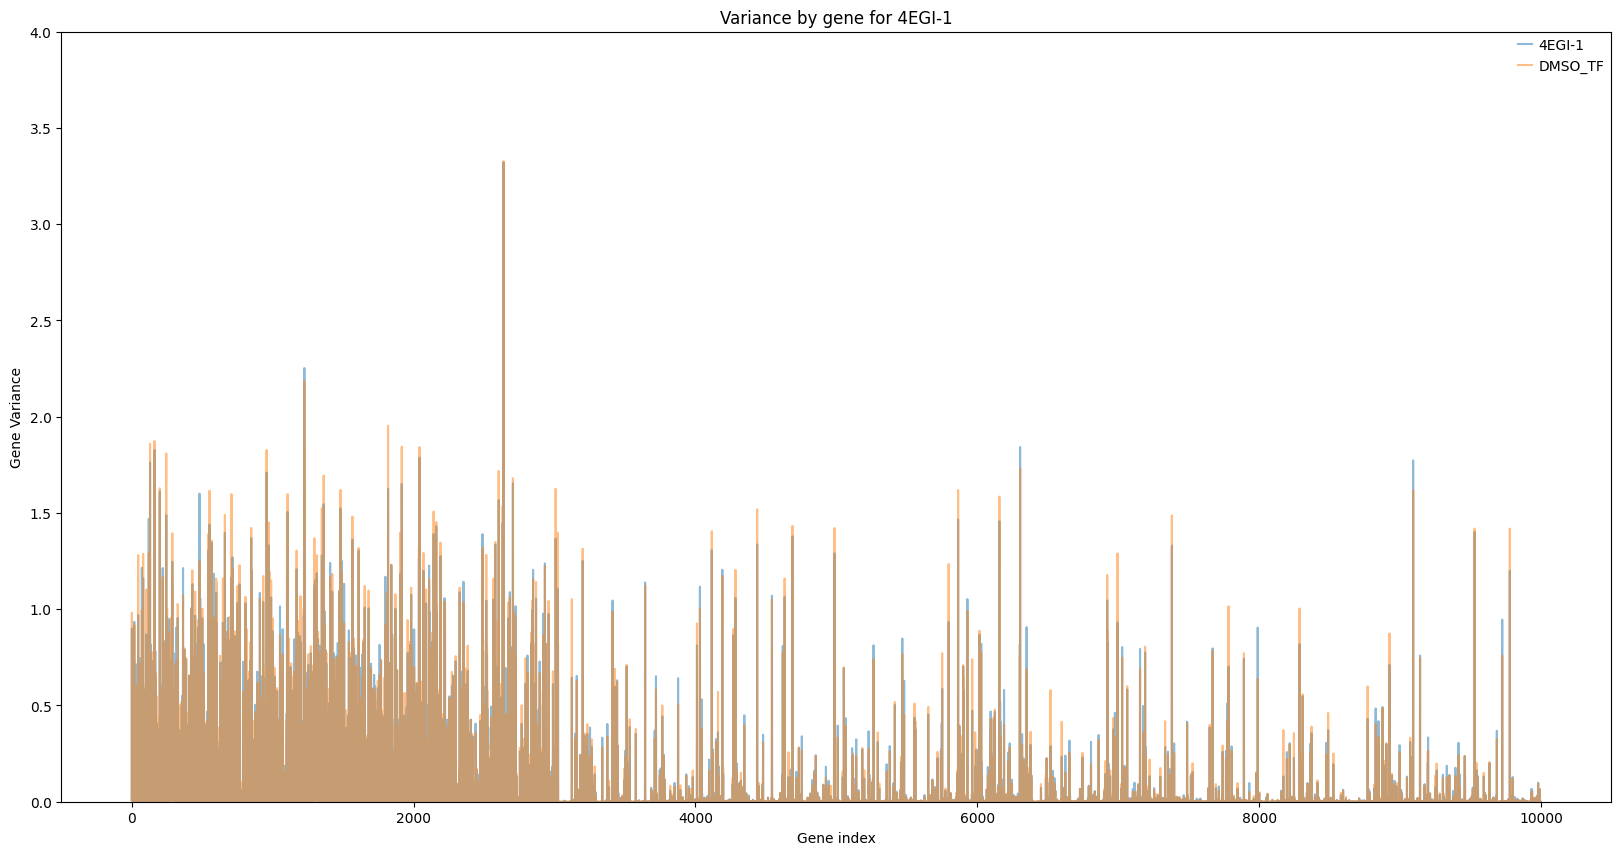

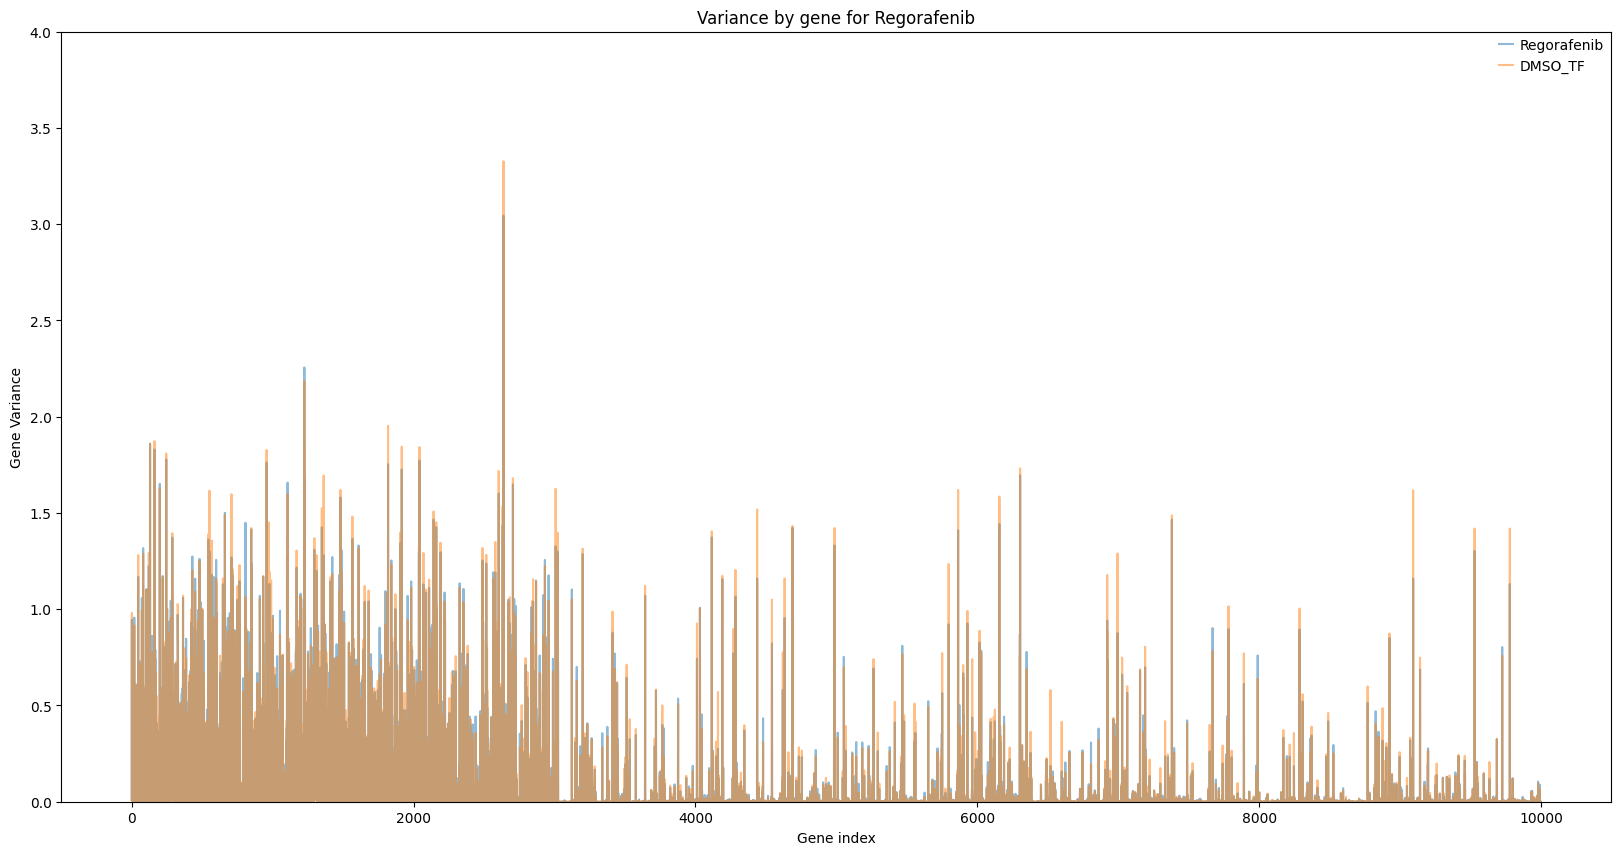

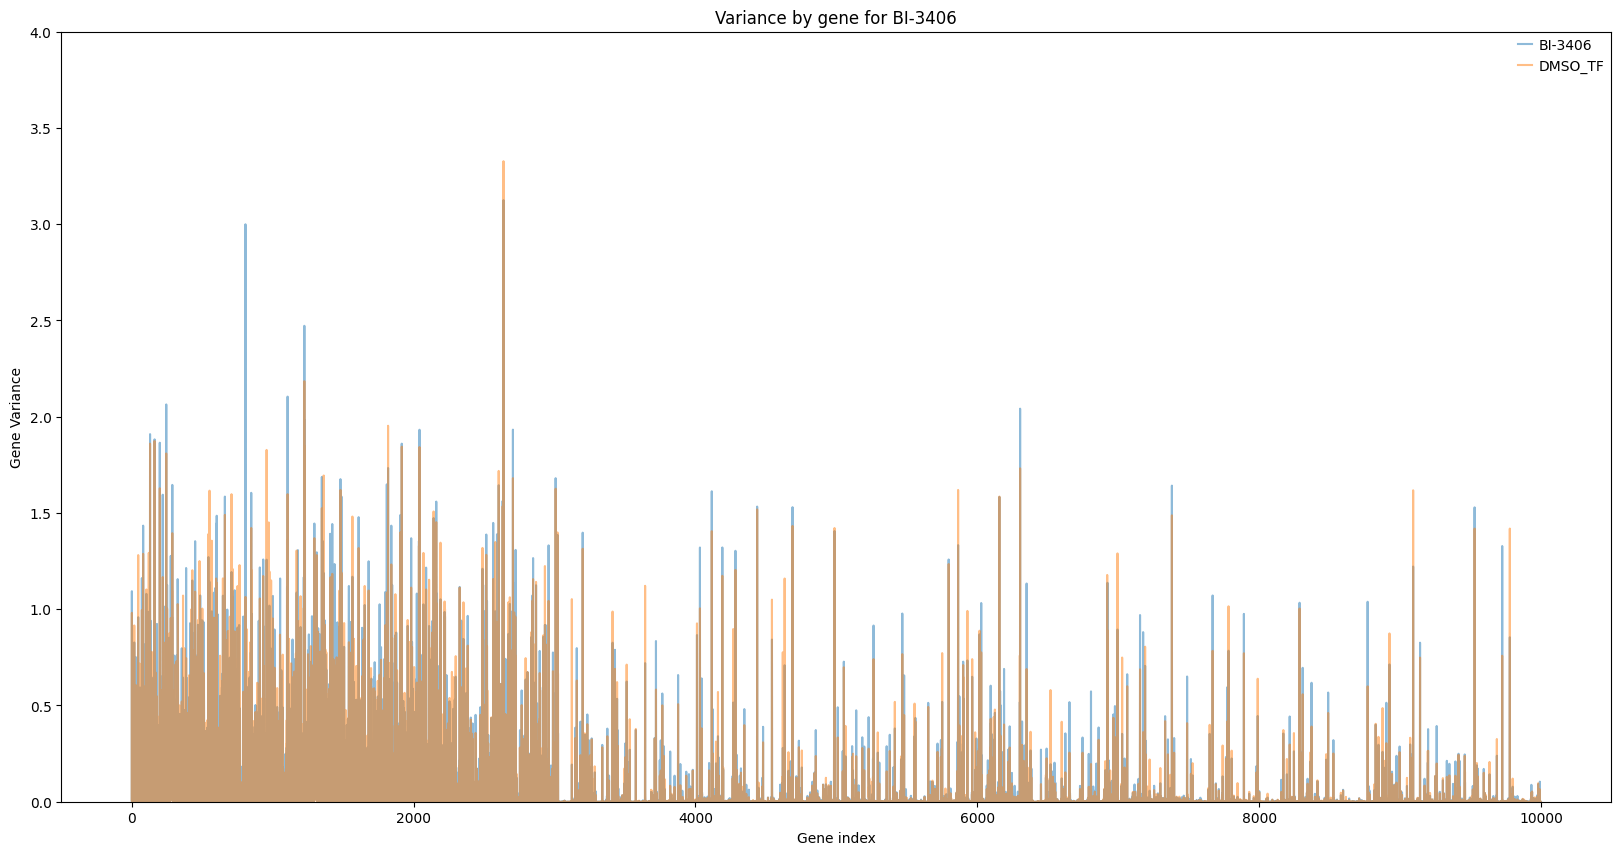

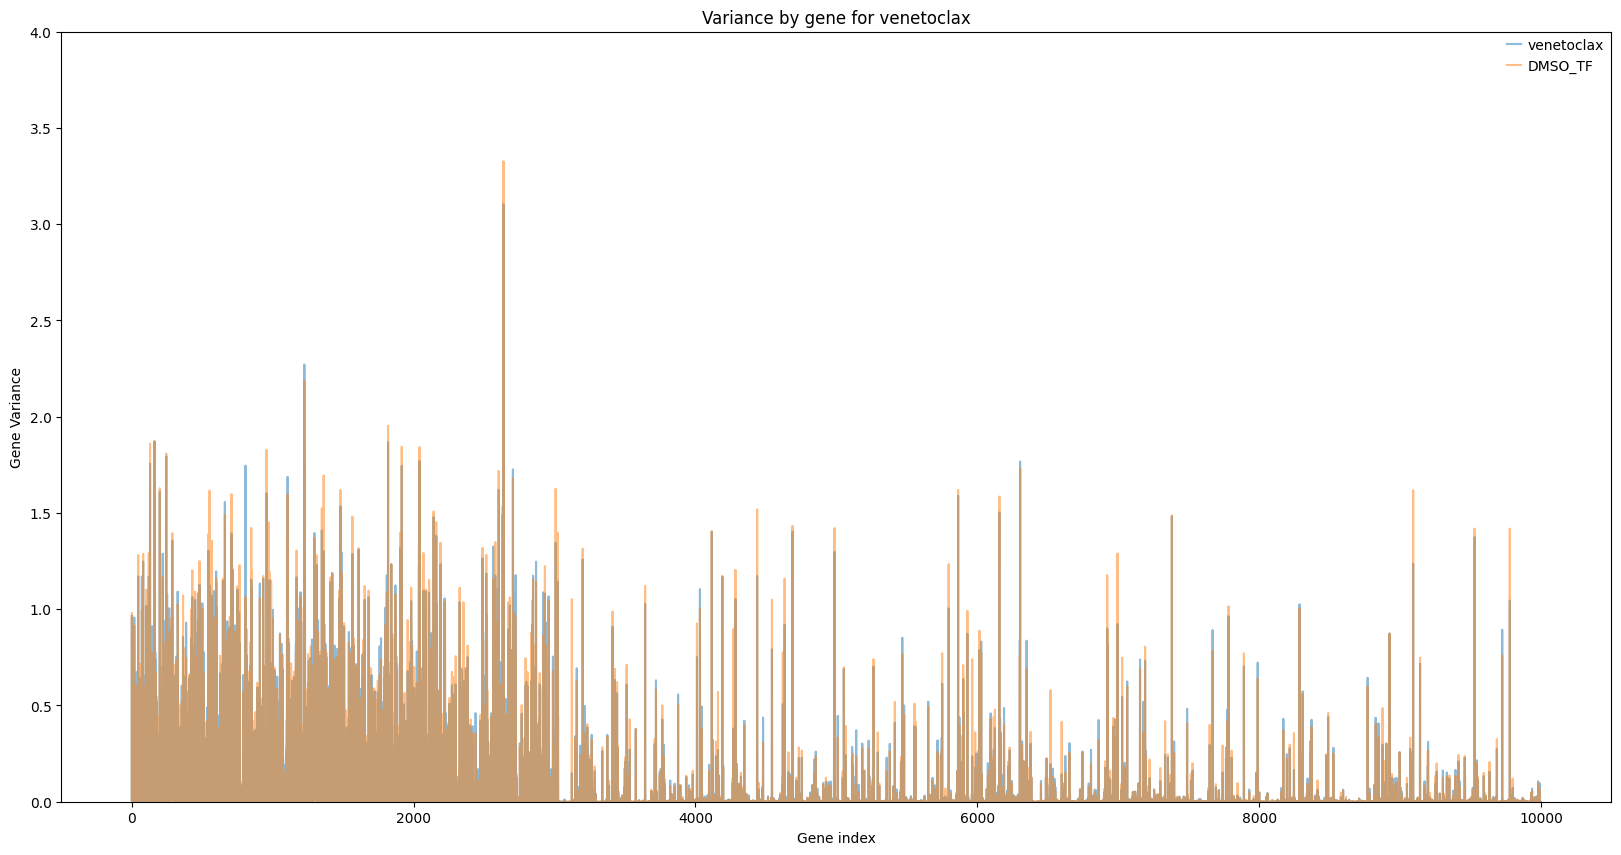

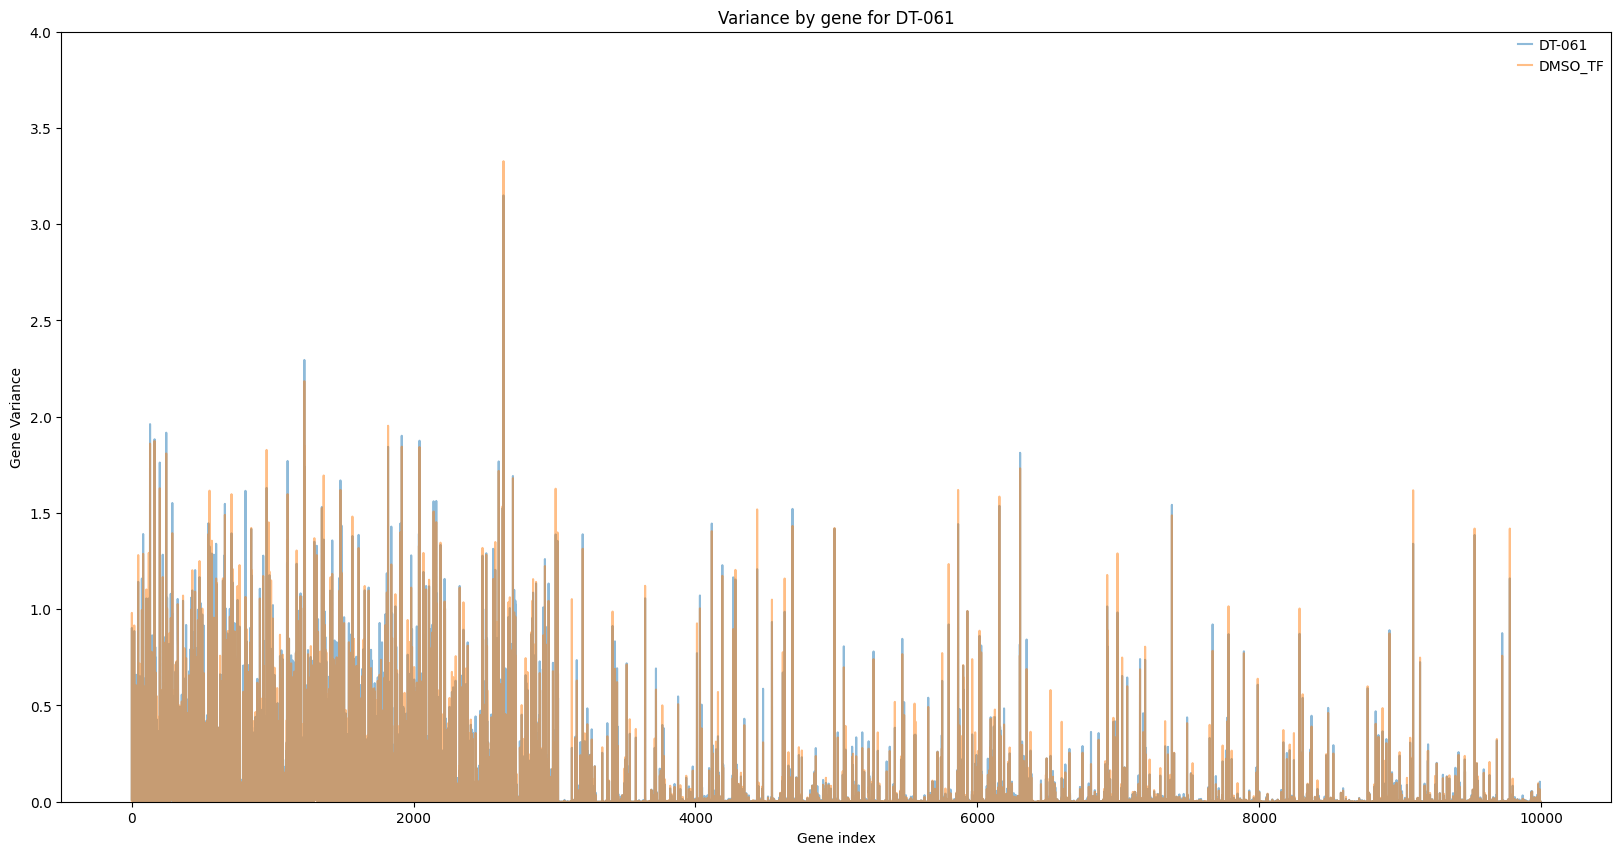

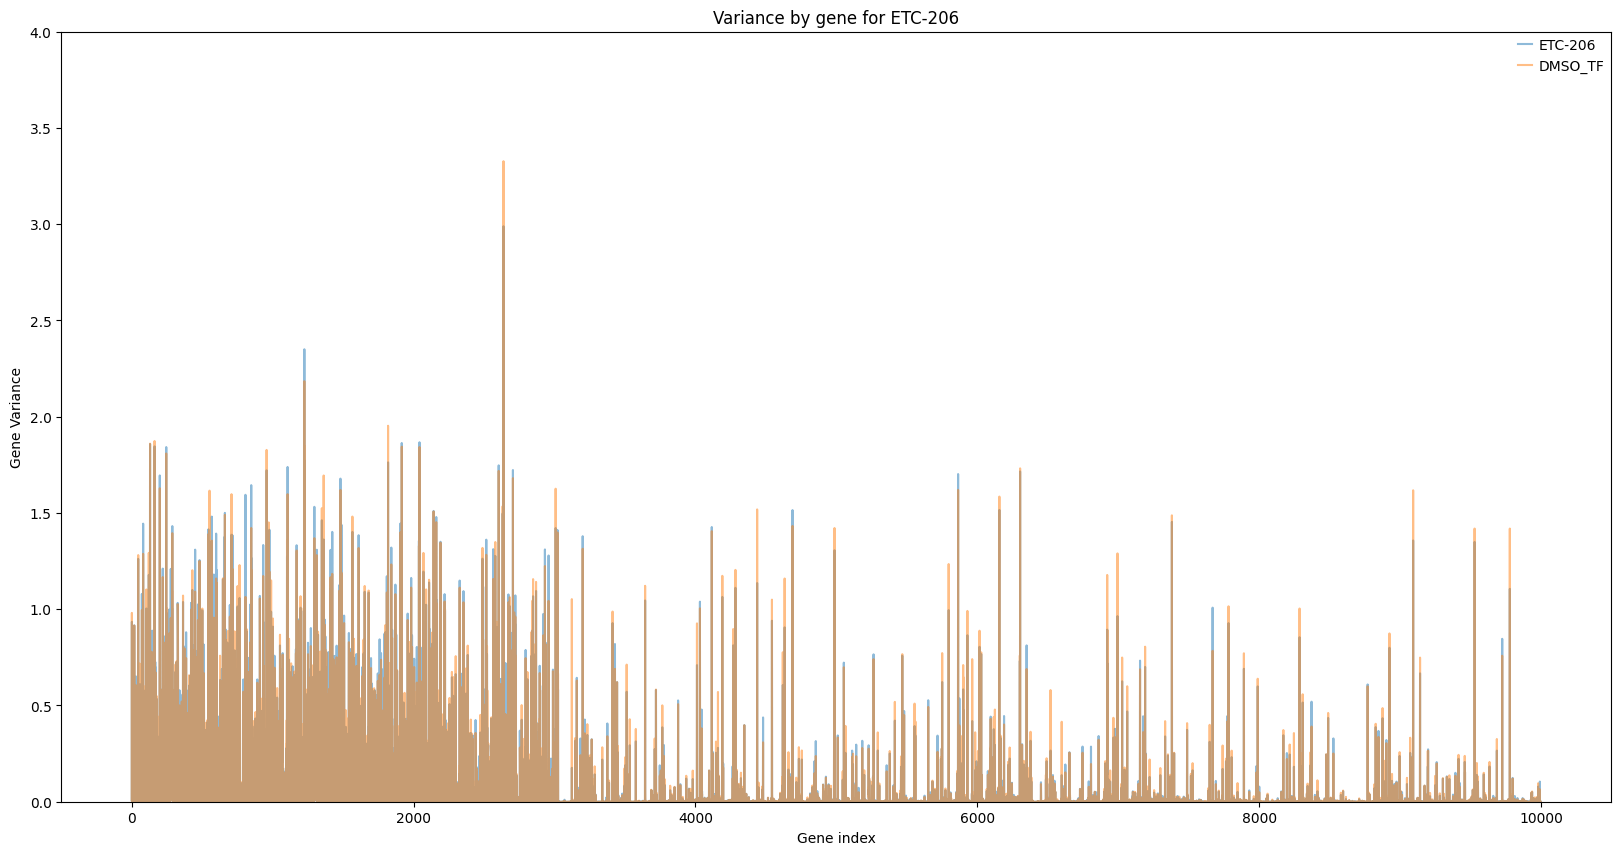

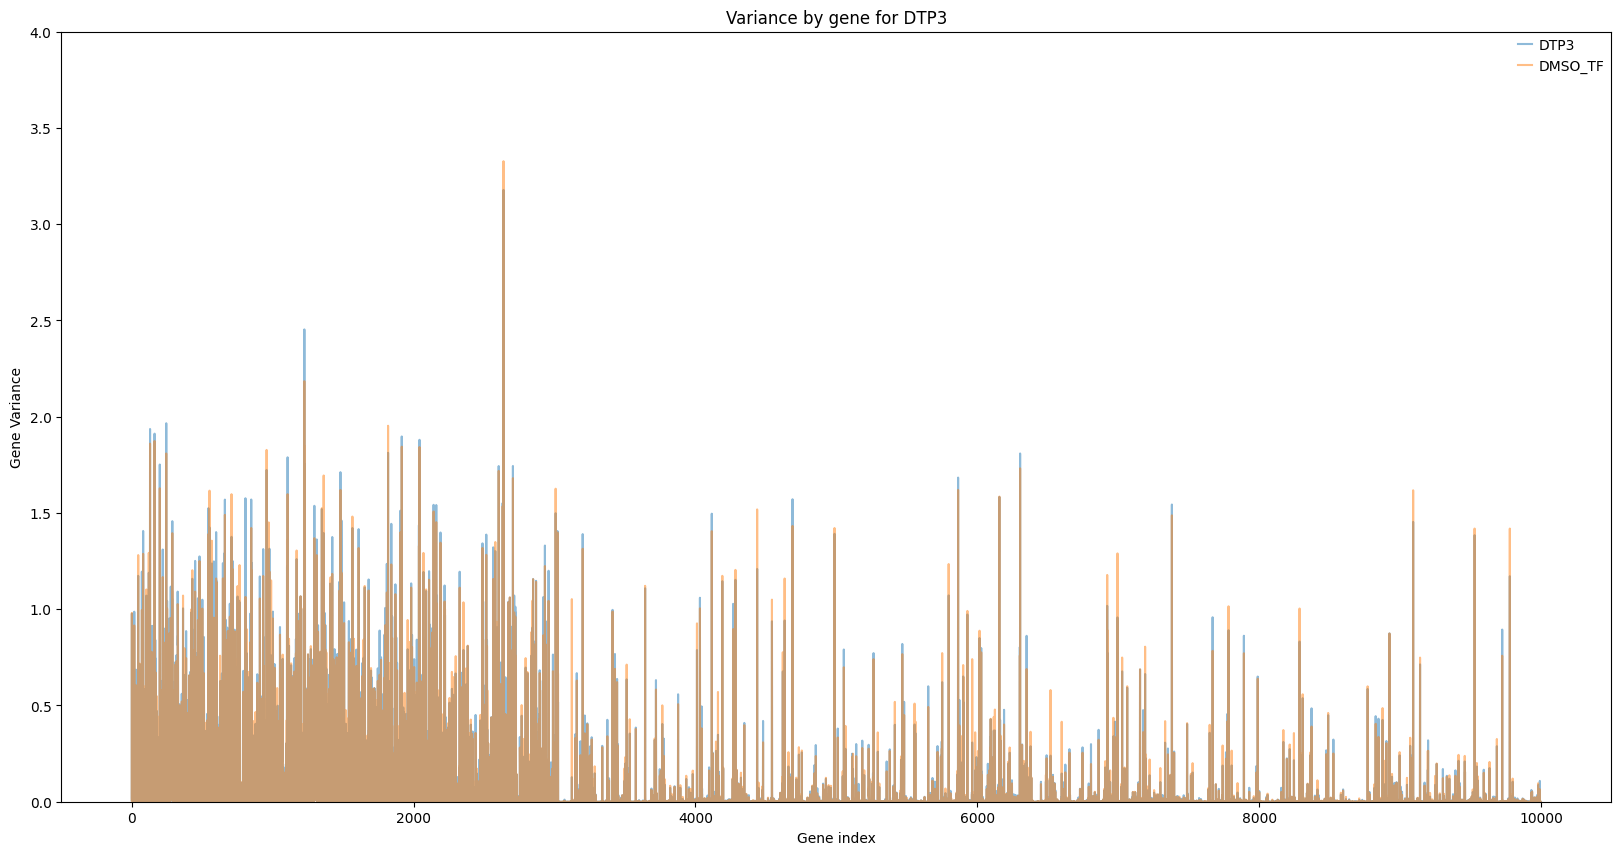

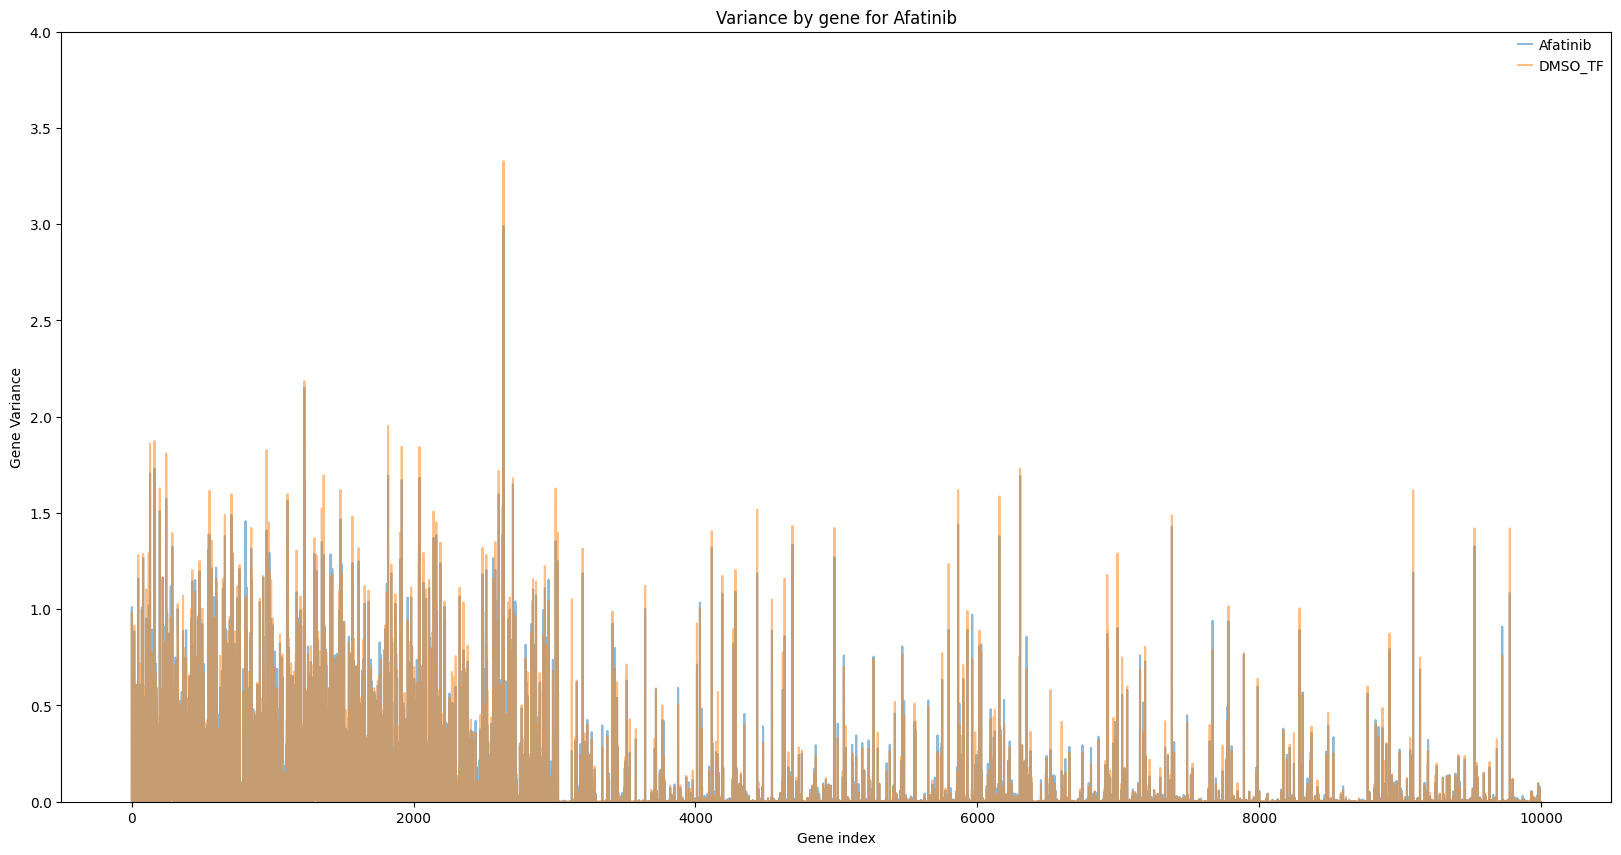

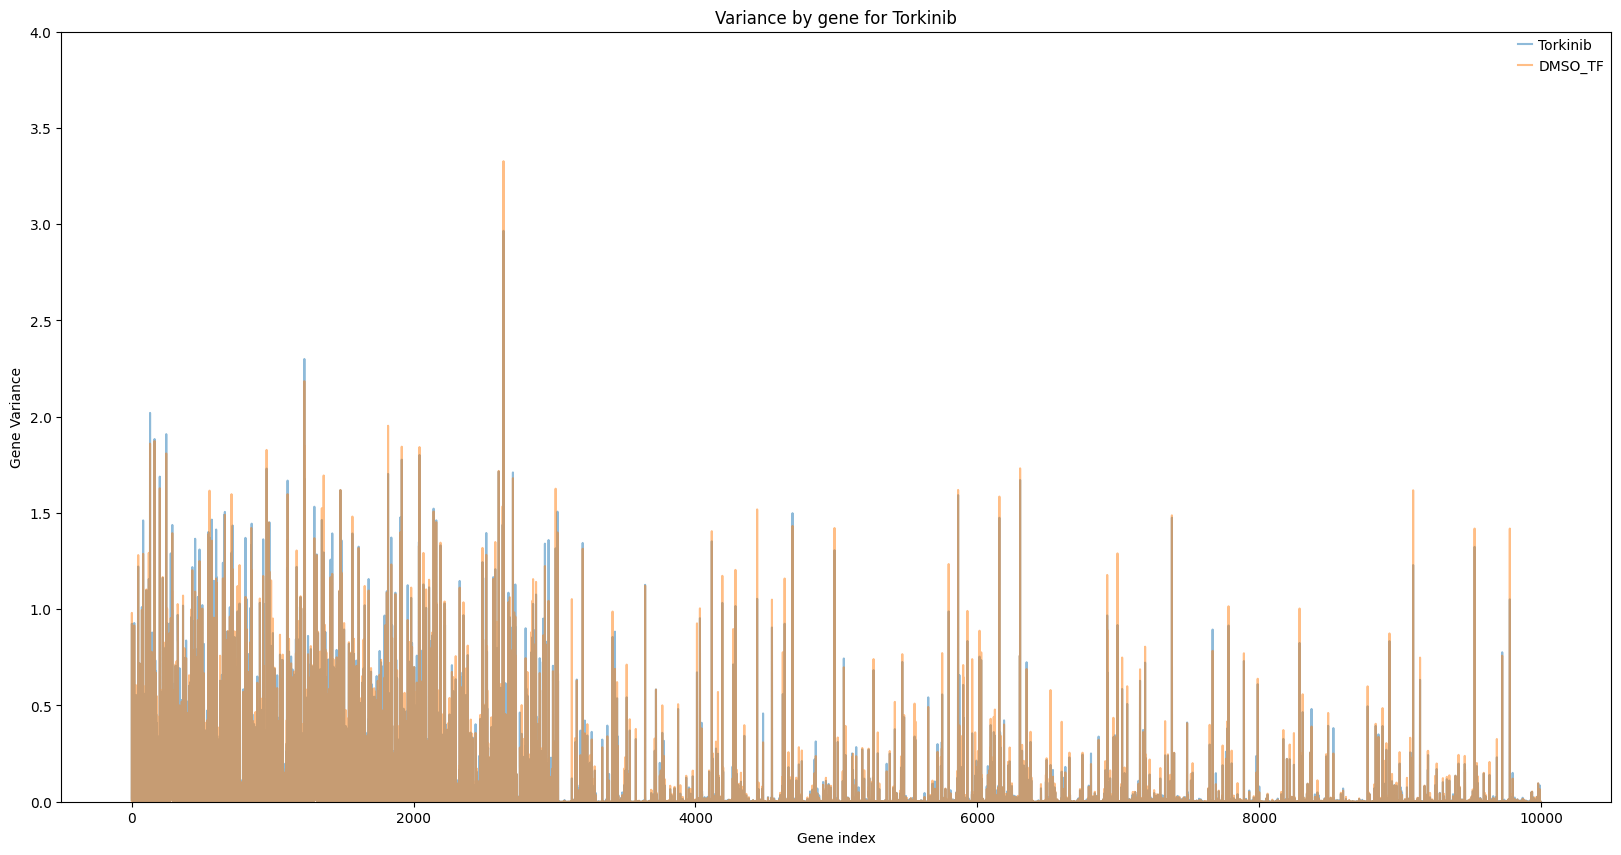

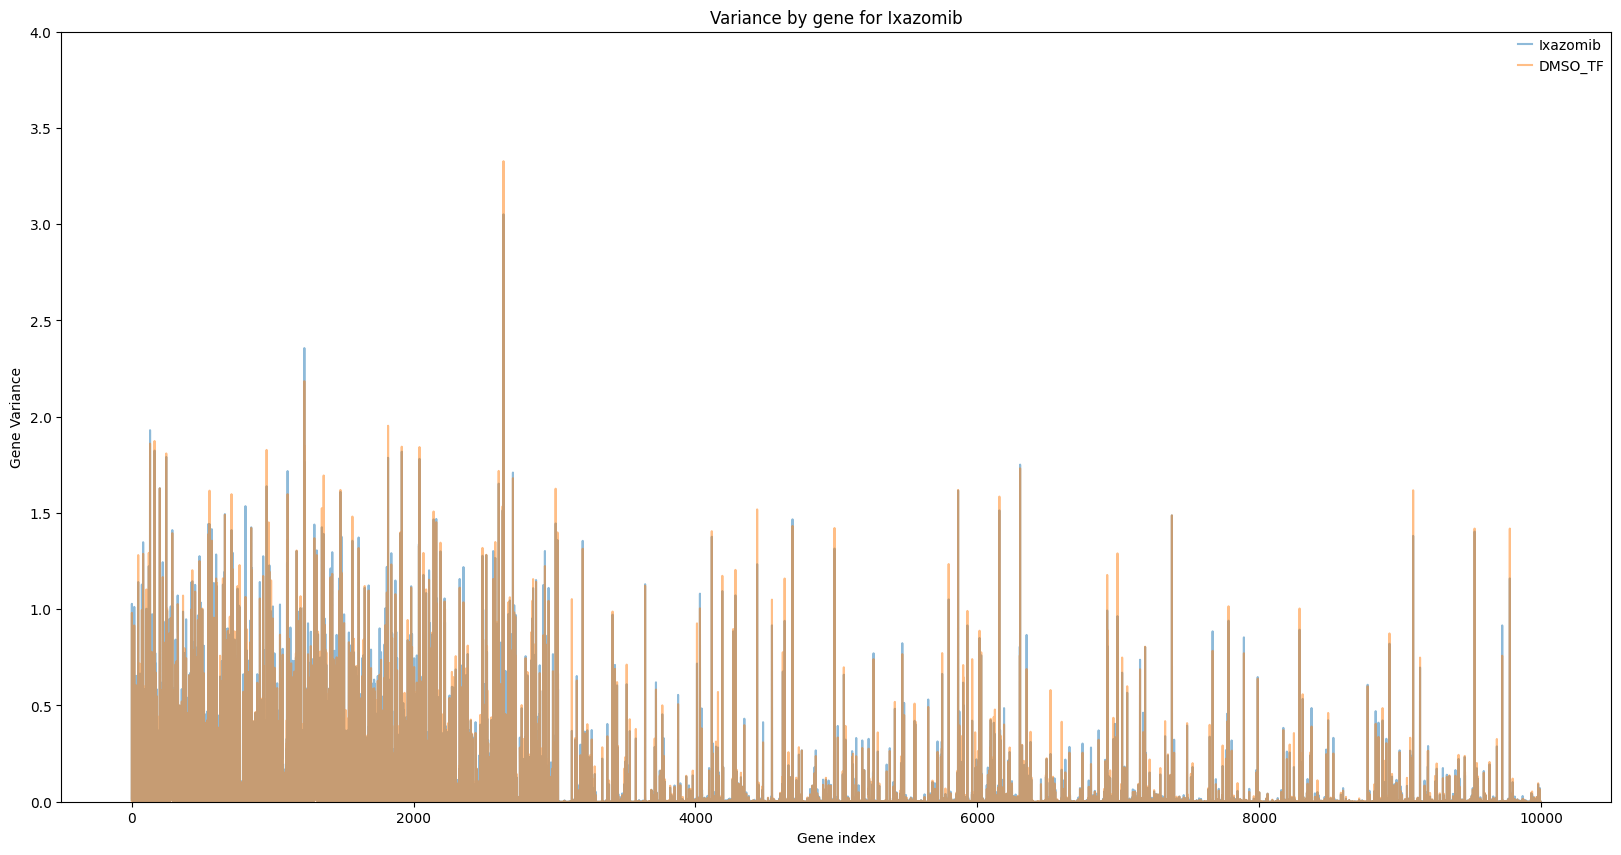

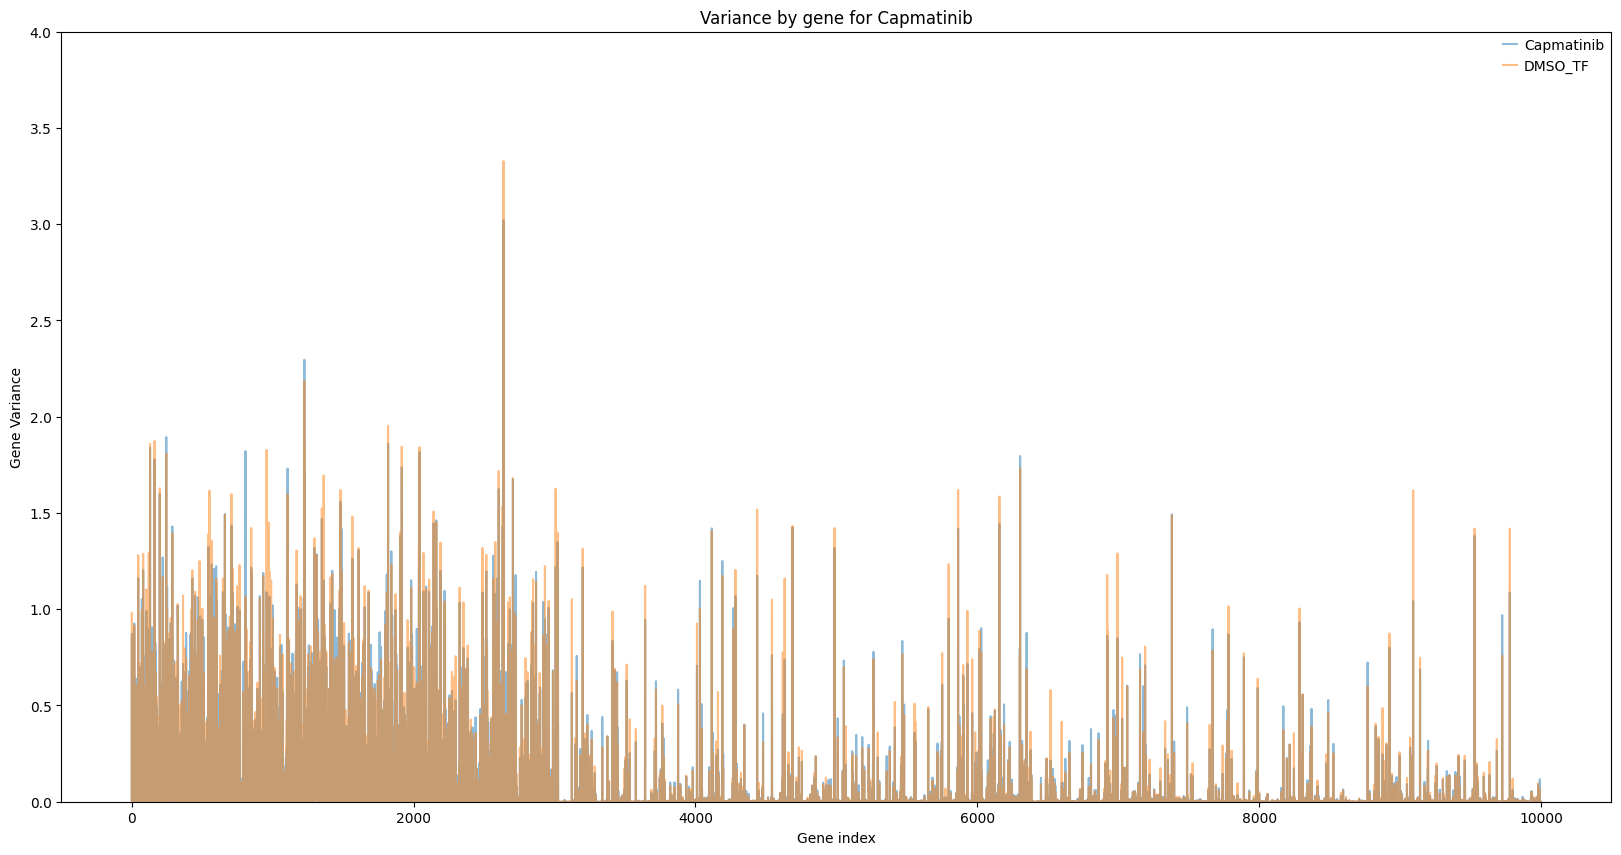

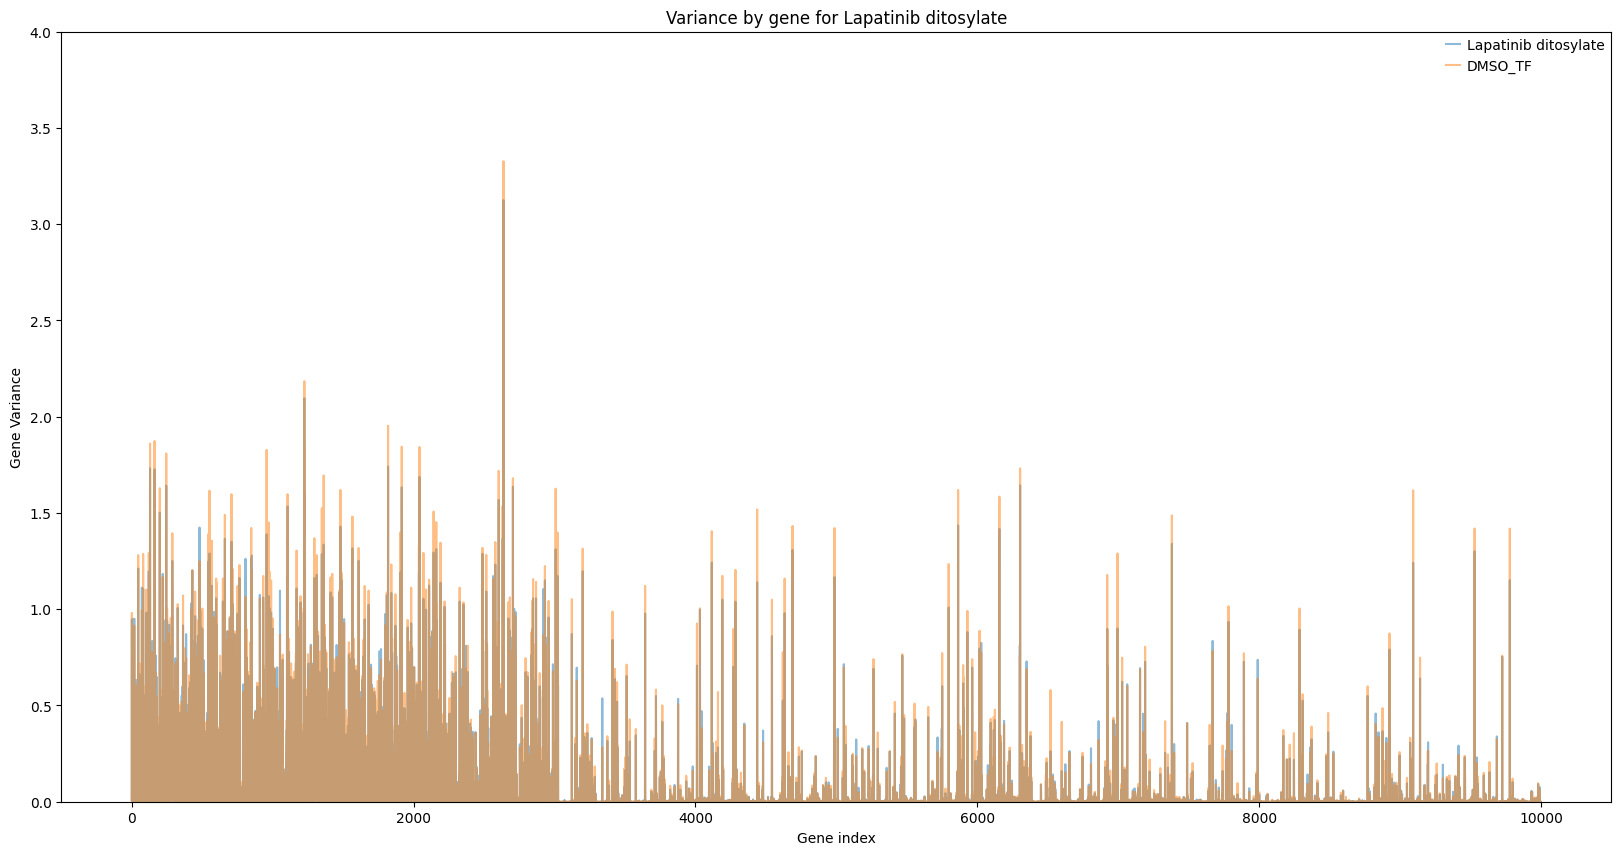

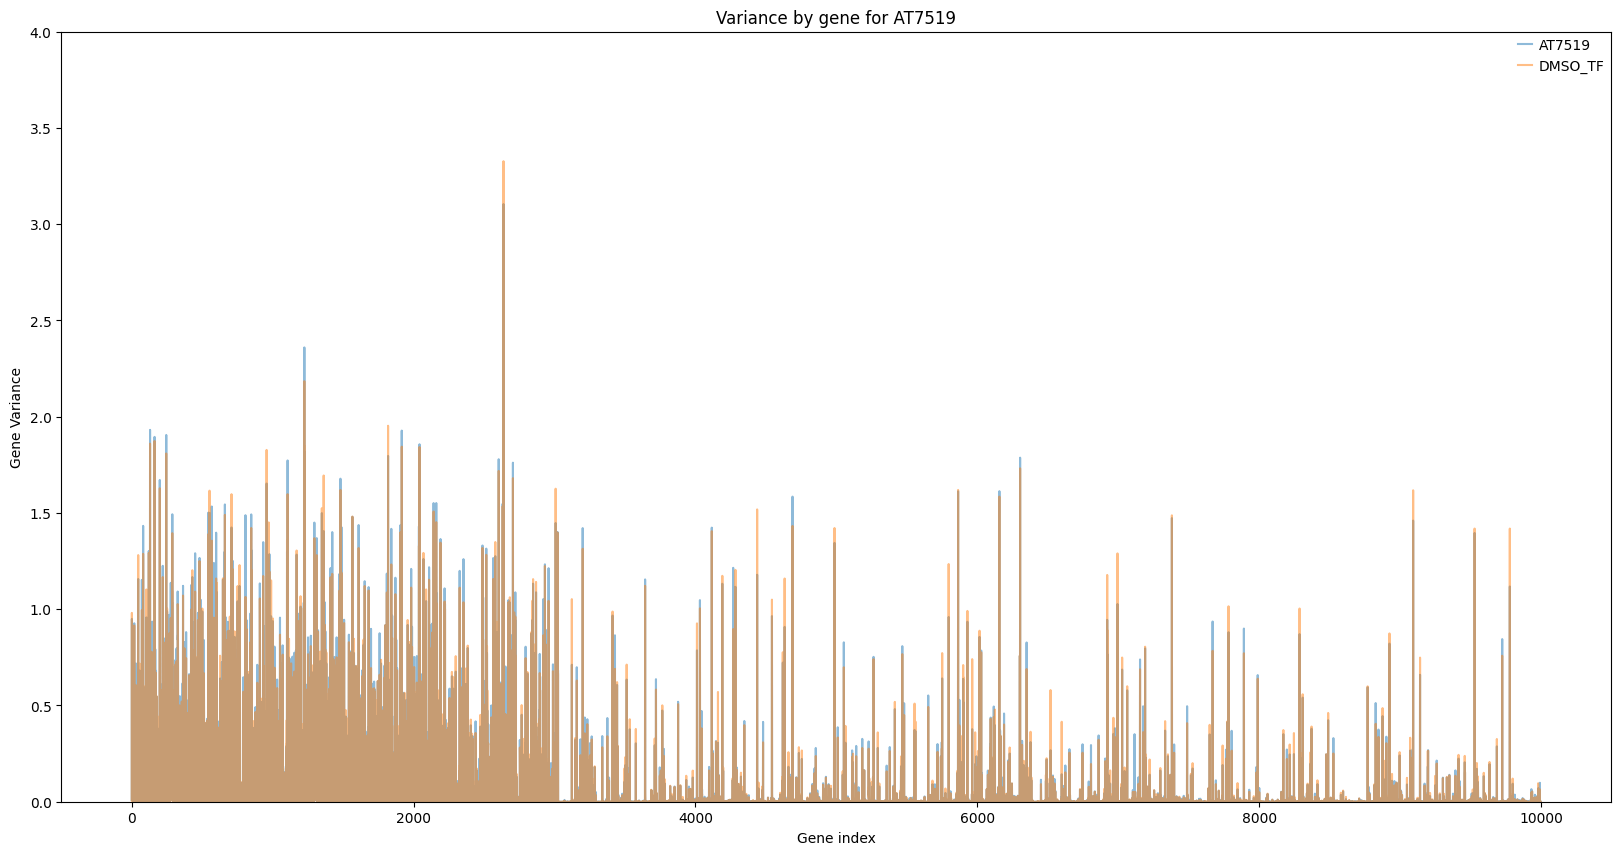

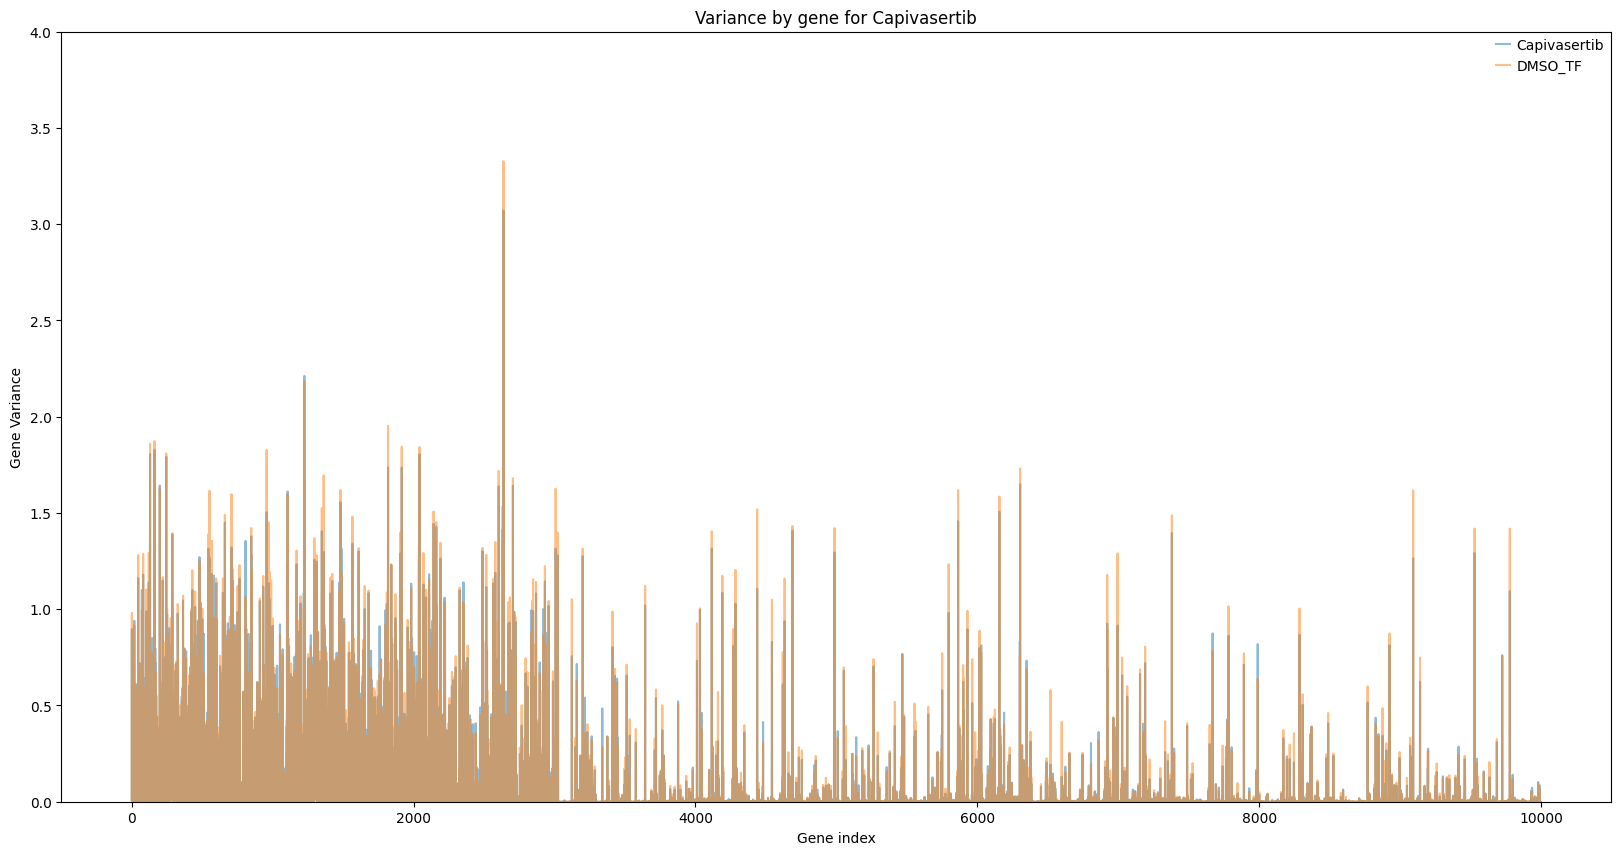

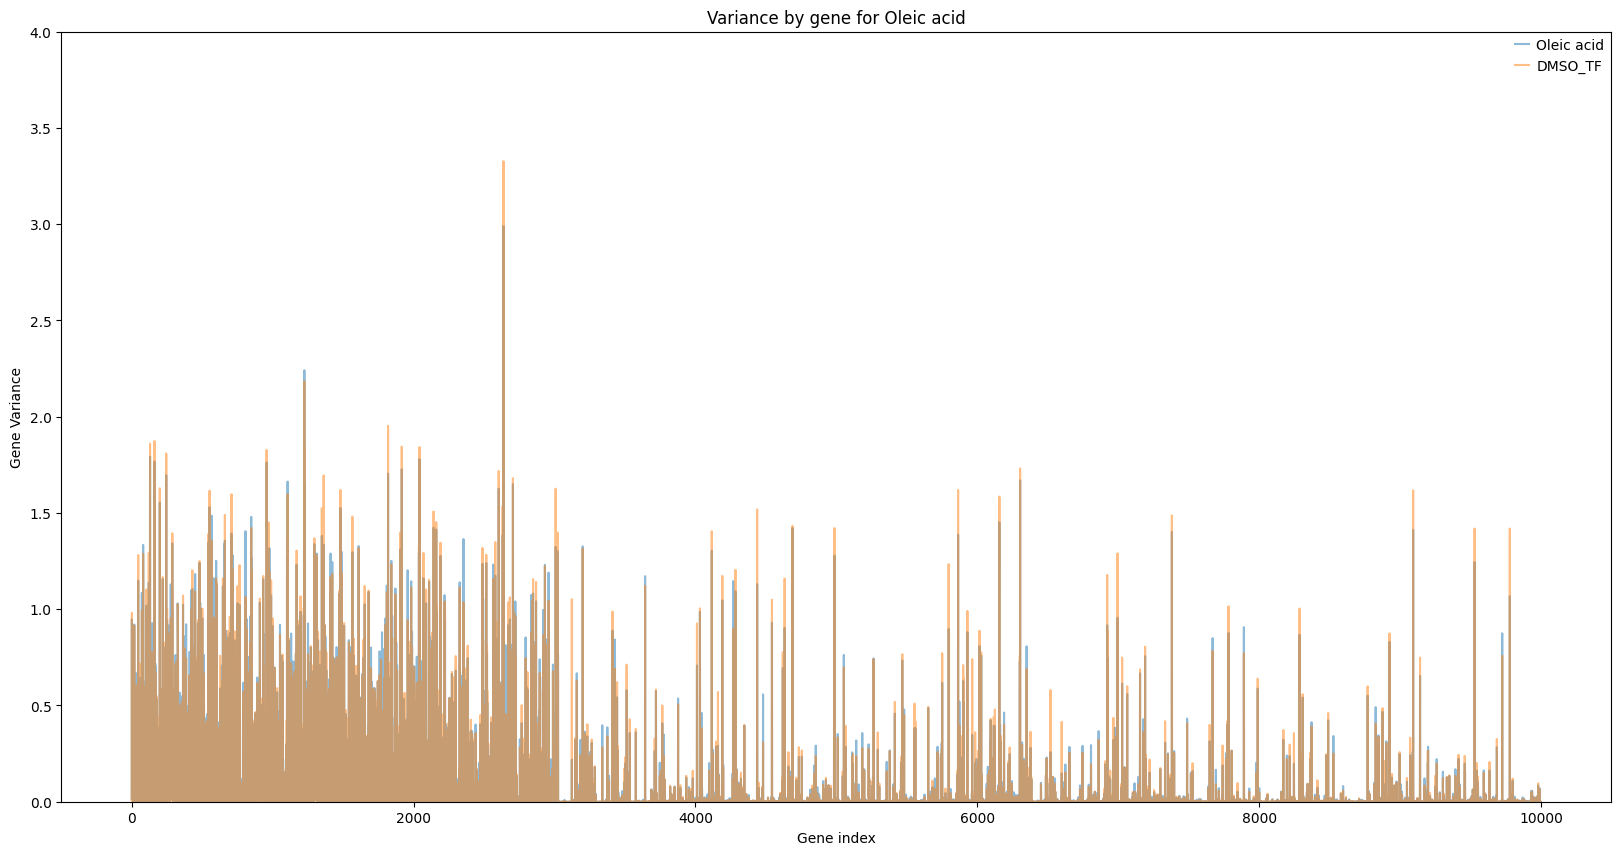

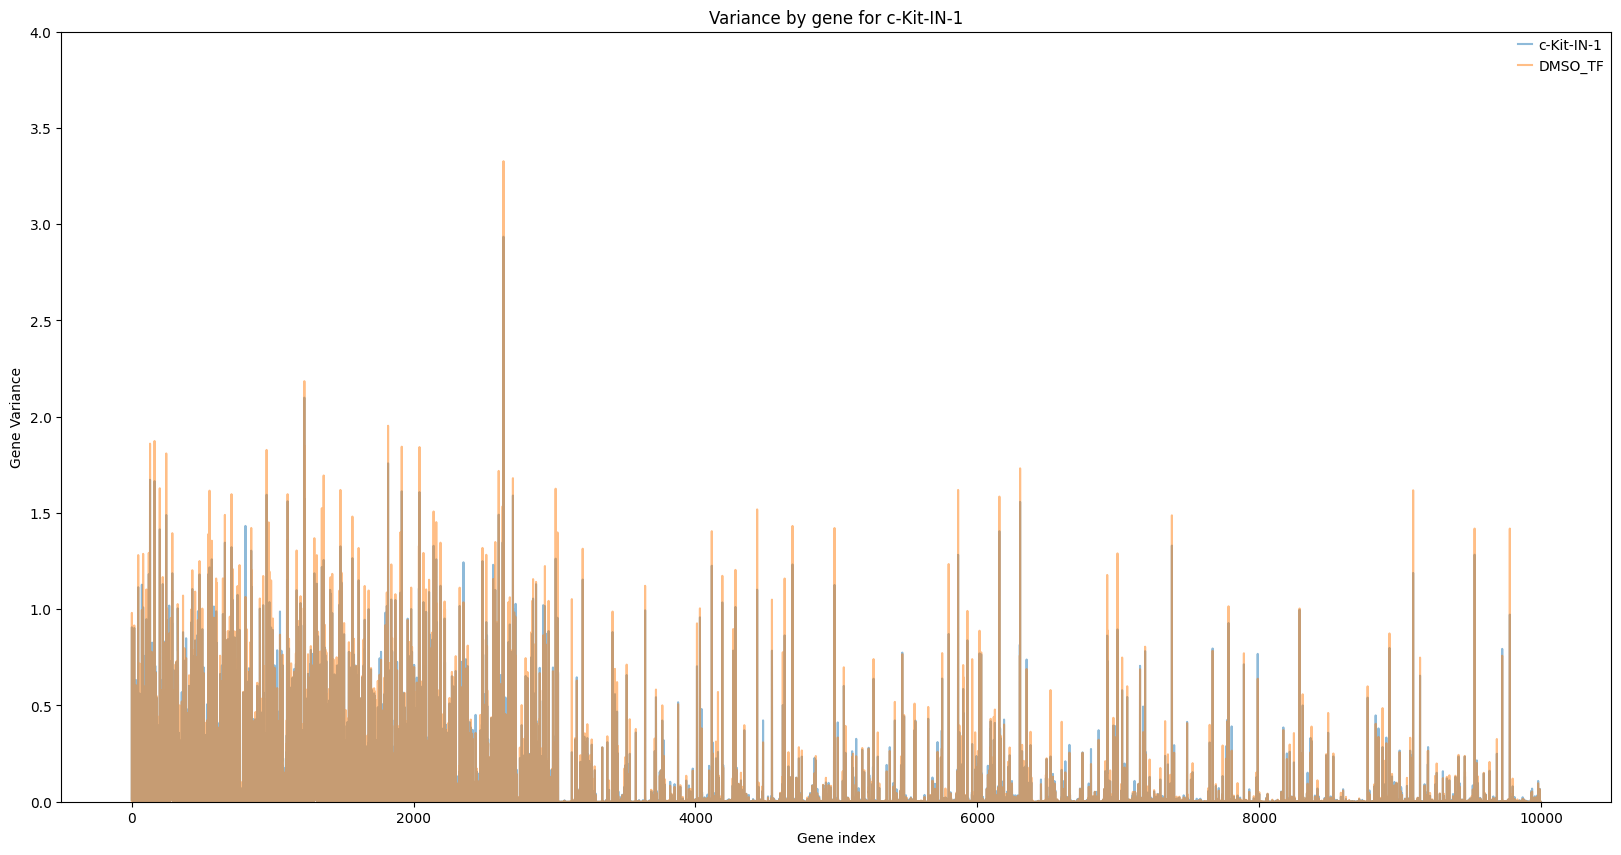

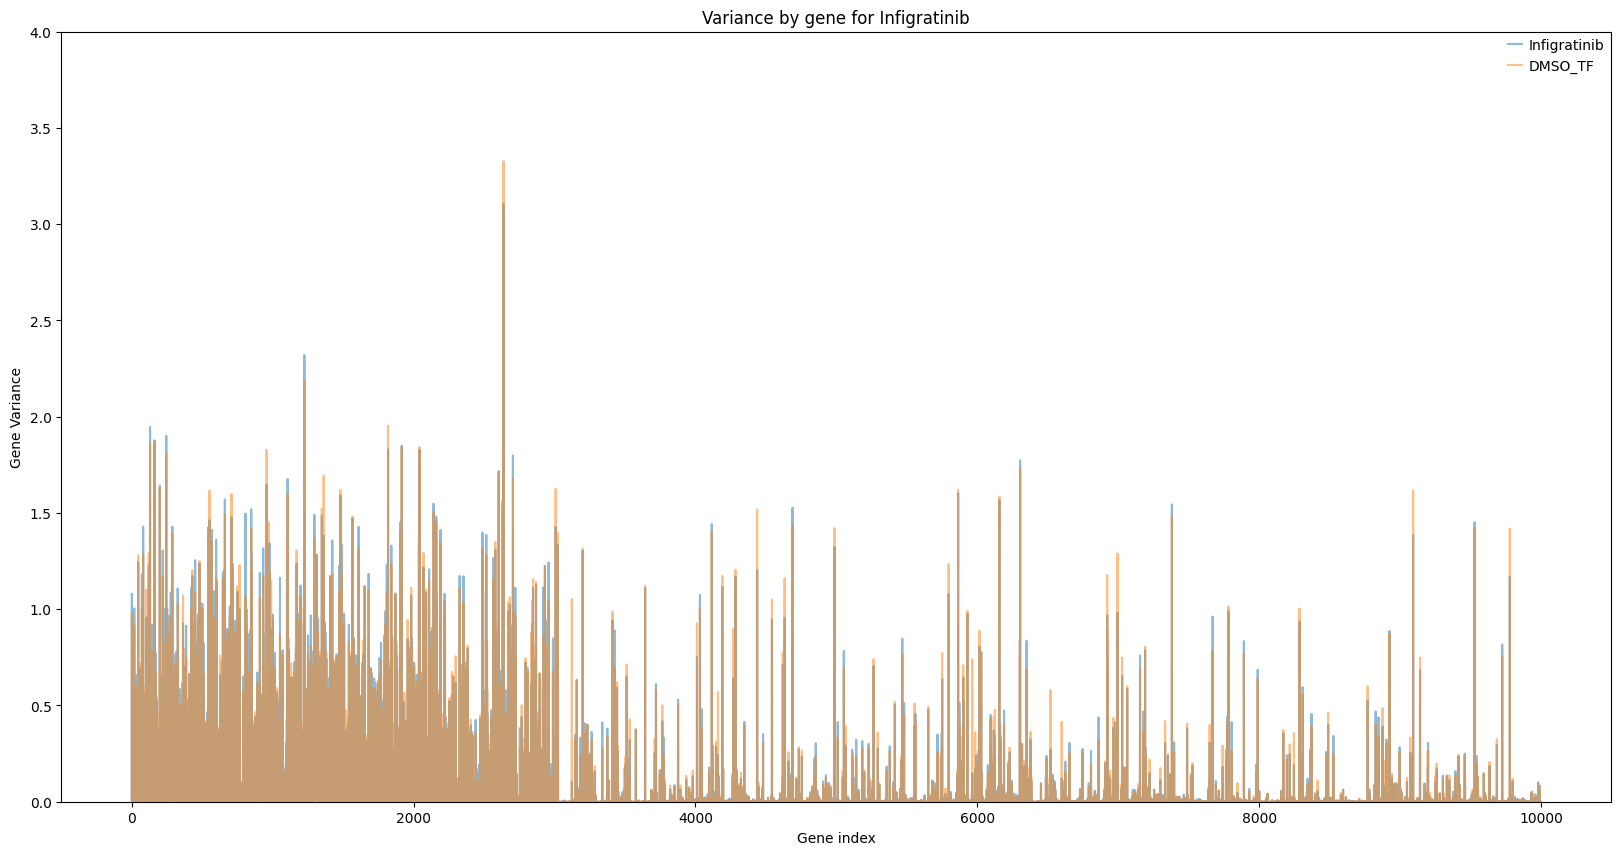

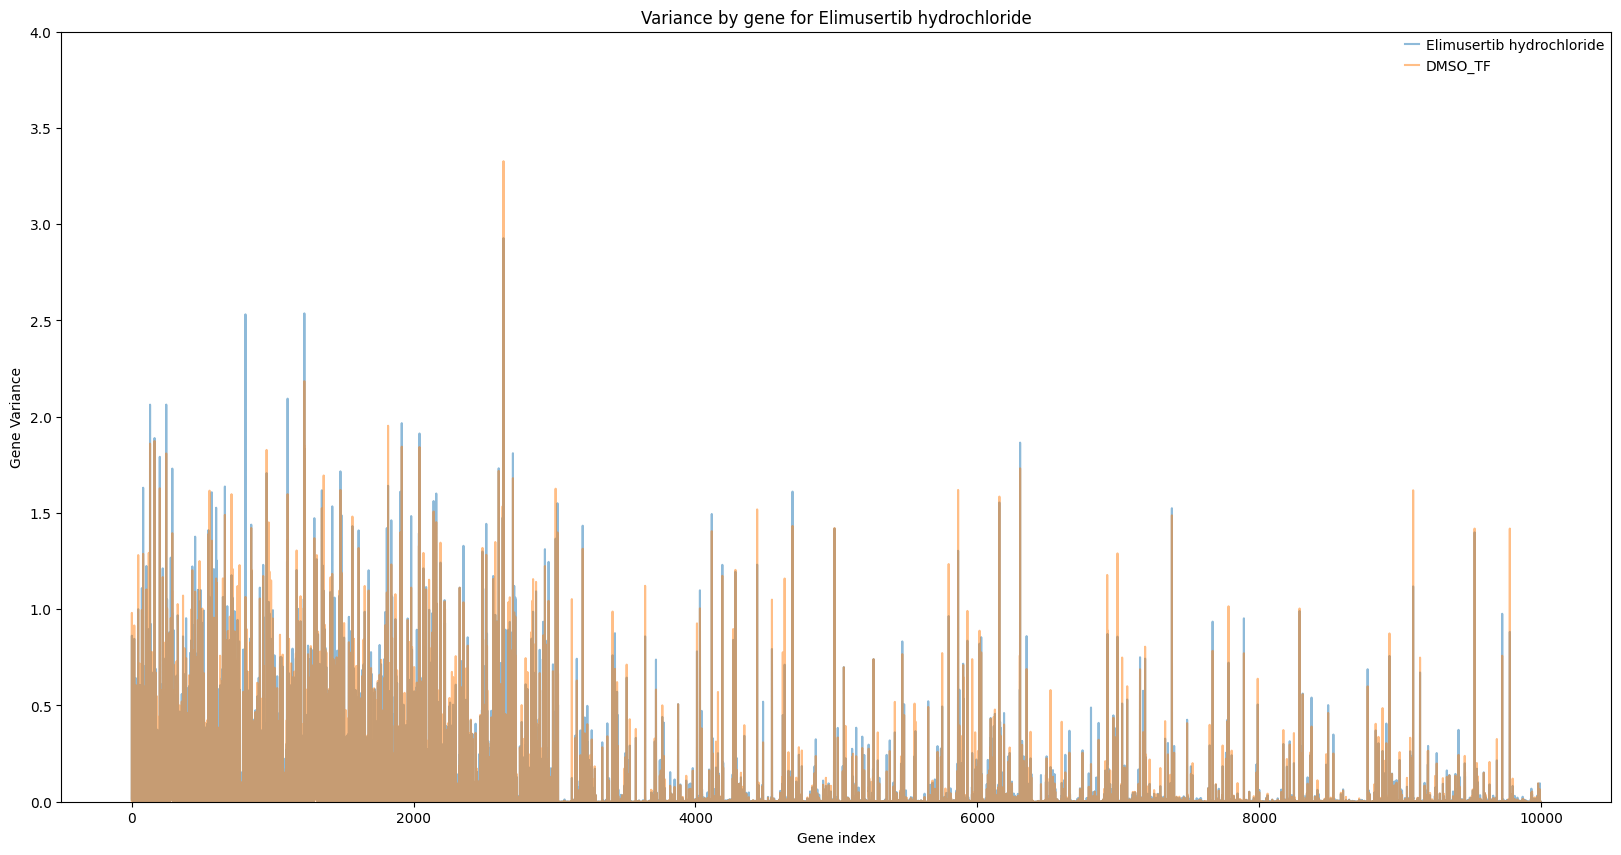

In [ ]:
variance_plot(top30_drugs)

# References

1. Heumos, L., Schaar, A.C., Lance, C. et al. Best practices for single-cell analysis across modalities. Nat Rev Genet (2023). https://doi.org/10.1038/s41576-023-00586-w

2. Zhang, Jesse, et al. "Tahoe-100m: A giga-scale single-cell perturbation atlas for context-dependent gene function and cellular modeling." BioRxiv (2025): 2025-02.